# 02 · Baselines no supervisados

**Grupo:** Oscar Romero Quincoces · Fernando Dapena Tauste · Daniel Garcia Lopez

**Objetivo.** Medir hasta dónde llega la **detección de anomalías pura**: modelos que aprenden solo cómo es una transacción normal y puntúan lo rara que es cada fila, sin ver nunca un fraude al entrenar. Las 295 etiquetas se usan solo para **validar** (AUPR), como recomienda el profesor: *"si tuviera anomalías y son muy pocas… las utilizaría para validar"* [02:45:03].

El 02 deja tres cosas: el **mejor detector no supervisado** (la referencia que tiene que batir el supervisado del 03), las **decisiones** de escalado, variables y duplicados que quedaban abiertas, y los **scores** de los mejores detectores para usarlos como variables en el híbrido del 04.

**Cómo leer este notebook.** Igual que el 01: cada sección sigue el orden **pregunta → figura → conclusión → impacto**. Cada familia de detectores se compara con el mismo protocolo de validación (§1).

| Parte I · Detectores por familia | Parte II · Comparación y entrega |
|---|---|
| 0. Setup | 10. ¿Qué detector gana en CV? |
| 1. ¿Cómo comparamos detectores? | 11. ¿Se parecen entre sí? |
| 2. ¿Cuánto da el GMM del profesor? | 12. ¿Se confirma en test? |
| 3. ¿Distancia o densidad? | 13. ¿Por qué un punto es fraude? |
| 4. ¿Cuántas gaussianas y con qué escala? | 14. Exportar scores para el 04 |
| 5. ¿Sirven los vecinos? | 15. Conclusiones |
| 6. ¿Aislar o envolver? | Conectores |
| 7. ¿Se puede reconstruir lo normal? | |
| 8. ¿Basta con mirar variable a variable? | |
| 9. ¿Todas las variables o las mejores? | |

In [1]:
# ============================================================
# CELDA COMÚN v2 — NO MODIFICAR (idéntica en 02, 03, 04 y 99)
# Lee el dataset preparado en 01: split fijo, folds por grupo y features. Ver D-0.1, D-1.1–D-1.4.
# Uso: m = fit(modelo, X_train, y_train); report("x", score(m, X_test)); cv_aupr(modelo); save_submission(score(m, X_prod))
# ============================================================
import os
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.base import clone, is_classifier
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler, RobustScaler
from sklearn.metrics import average_precision_score, roc_auc_score, precision_recall_curve

pd.options.display.max_columns = None
SEED = 42
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
OUTPUT_DIR = ROOT / "data" / "output"
PREP_CSV = Path(os.environ.get("PREP_CSV", OUTPUT_DIR / "01_dataset_preparado.csv"))
if not PREP_CSV.exists():
    raise FileNotFoundError(f"No existe {PREP_CSV}: ejecuta antes notebooks/01_EDA_y_preprocesado.ipynb")

FEAT_RAW = [f"X{i}" for i in range(1, 21)] + ["Amount"]
df = pd.read_csv(PREP_CSV)
df[FEAT_RAW] = df[FEAT_RAW].astype(float)  # el CSV guarda X enteras: se leen como float, igual que los originales
df_const = df[df["split"] != "prod"].sort_values("row_id").reset_index(drop=True)
df_prod = df[df["split"] == "prod"].sort_values("row_id").reset_index(drop=True)
FEATURES = [f"X{i}" for i in range(1, 21)] + ["log1p_Amount", "amount_freq"]  # conjunto por defecto (D-1.2)

tr, te = df_const[df_const["split"] == "train"], df_const[df_const["split"] == "test"]
X_train, y_train, groups_train = tr[FEATURES], tr["Class"].astype(int), tr["group_id"]
X_test, y_test = te[FEATURES], te["Class"].astype(int)
X_prod = df_prod[FEATURES]
dup_test = te["dup_en_train"].to_numpy(bool)  # filas de test con copia exacta en train (D-1.1)
# Folds por grupo hechos en 01 → (idx_train, idx_val) posicionales sobre X_train; vale como cv= en sklearn
cv_splits = [(np.flatnonzero(tr["fold"].to_numpy() != k), np.flatnonzero(tr["fold"].to_numpy() == k)) for k in range(5)]

def make_pipe(model, scaler="standard"):
    """Escalador ('standard' | 'robust' | None) + modelo: el escalado se ajusta DENTRO de cada fold."""
    steps = {"standard": [StandardScaler()], "robust": [RobustScaler()], None: []}[scaler]
    return make_pipeline(*steps, model)

def score(model, X):
    """Mayor = más fraude. Clasificador: predict_proba[:, 1] (o decision_function). No supervisado: −score_samples."""
    if not is_classifier(model):
        return -model.score_samples(X)  # GMM: −log-verosimilitud; IF / OCSVM / LOF(novelty=True): −normalidad
    return model.predict_proba(X)[:, 1] if hasattr(model, "predict_proba") else model.decision_function(X)

def fit(model, X, y):
    """Copia limpia ajustada: clasificador con (X, y); no supervisado SOLO con las normales (y == 0)."""
    y = np.asarray(y)
    return clone(model).fit(X, y) if is_classifier(model) else clone(model).fit(X[y == 0])

def metrics(y_true, scores):
    """Métrica oficial: AUPR (average_precision_score). Mayor score = más fraude."""
    return {"aupr": average_precision_score(y_true, scores), "roc_auc": roc_auc_score(y_true, scores)}

def cv_aupr(model, X=X_train, y=y_train):
    """AUPR por fold sobre cv_splits (clasificadores y no supervisados). Devuelve (media, std, scores OOF alineados con X)."""
    X, y, oof, auprs = np.asarray(X, dtype=float), np.asarray(y), np.zeros(len(y)), []
    assert len(X) == len(tr), "X debe tener las filas de X_train en su orden"
    for it, iv in cv_splits:
        oof[iv] = score(fit(model, X[it], y[it]), X[iv])
        auprs.append(average_precision_score(y[iv], oof[iv]))
    print(f"CV AUPR = {np.mean(auprs):.4f} ± {np.std(auprs):.4f}")
    return np.mean(auprs), np.std(auprs), oof

def report(name, s_test):
    """AUPR de test con y sin las filas duplicadas de train (D-1.1), y ROC-AUC."""
    s, y = np.asarray(s_test, dtype=float), y_test.to_numpy()
    assert len(s) == len(y), f"{len(s)} scores != {len(y)} filas de test"
    r = {"modelo": name, **metrics(y, s), "aupr_sin_dup": average_precision_score(y[~dup_test], s[~dup_test])}
    print(f"{name}: AUPR test={r['aupr']:.4f} | sin dup={r['aupr_sin_dup']:.4f} | ROC-AUC={r['roc_auc']:.4f}")
    return r

def plot_pr(y_true, scores_by_model, ax=None):
    ax = ax or plt.subplots(figsize=(6, 5))[1]
    for name, s in scores_by_model.items():
        p, r, _ = precision_recall_curve(y_true, s)
        ax.plot(r, p, label=f"{name} (AUPR={average_precision_score(y_true, s):.3f})")
    ax.axhline(np.mean(y_true), ls="--", c="grey", label="aleatorio")
    ax.set(xlabel="Recall", ylabel="Precision", title="Curva Precision-Recall")
    ax.legend()
    return ax

def save_submission(scores, name="scores_produccion"):
    """Entregable: CSV de UNA columna `score`, una fila por transacción de producción (mismo orden)."""
    scores = np.asarray(scores, dtype=float).ravel()
    assert len(scores) == len(df_prod) == 113_923, f"{len(scores)} scores, {len(df_prod)} filas de producción"
    assert np.isfinite(scores).all(), "hay scores no finitos"
    pd.DataFrame({"score": scores}).to_csv(OUTPUT_DIR / f"{name}.csv", index=False)

print(f"train {X_train.shape} fraudes={y_train.sum()} | test {X_test.shape} fraudes={y_test.sum()} "
      f"(dup={dup_test.sum()}) | prod {X_prod.shape} | folds={[len(v) for _, v in cv_splits]}")

train (119618, 22) fraudes=206 | test (51266, 22) fraudes=89 (dup=1643) | prod (113923, 22) | folds=[23924, 23924, 23923, 23924, 23923]


## 0. Setup

Librerías y utilidades propias de este notebook. Los datos (`X_train`, `X_test`, `X_prod`, `cv_splits`) y las funciones `fit()`, `score()`, `make_pipe()`, `report()` y `plot_pr()` vienen de la celda común v2.

Misma paleta que el 01 (**gris = normal, rojo = fraude**) y un color por **familia** de detector, que se mantiene en todas las figuras.

In [3]:
import time
import warnings
import seaborn as sns
from joblib import Parallel, delayed
from threadpoolctl import threadpool_limits
from scipy import stats
from sklearn.base import BaseEstimator, OutlierMixin

warnings.filterwarnings("ignore", category=FutureWarning)
sns.set_theme(style="whitegrid", context="notebook", rc={"figure.figsize": (8, 4.5), "axes.titleweight": "bold"})
C = {0: "#9e9e9e", 1: "#d62728"}          # gris = normal, rojo = fraude
LBL = {0: "normal", 1: "fraude"}
FAM = {"distancia": "#4c72b0", "densidad": "#dd8452", "vecindad": "#55a868", "aislamiento": "#8172b3",
       "una clase": "#937860", "reconstrucción": "#da8bc3", "marginal": "#8c8c8c"}
PREV = y_train.mean()                       # AUPR aleatorio de referencia

`evaluar()` es el **protocolo común** (§1): los mismos 5 folds de `cv_splits` para todos los detectores, ajuste solo con los normales del fold de train (`fit()` de la celda común) y AUPR en el fold de validación. Da lo mismo que `cv_aupr()`, pero corre los 5 folds en paralelo y guarda la AUPR de cada fold (para comparar por pares) y los scores *out-of-fold* (para el 04).

In [4]:
RES, OOF = {}, {}       # nombre → métricas de CV · nombre → scores out-of-fold alineados con X_train

def _fold(model, X, y, it, iv):
    with threadpool_limits(2):              # 5 folds en paralelo sin saturar los núcleos
        return iv, score(fit(model, X[it], y[it]), X[iv])

def evaluar(nombre, model, familia, feats=FEATURES, datos=X_train, guardar=True):
    """CV de 5 folds (cv_splits): ajusta con los normales del fold de train y mide AUPR en el de validación.
    datos: DataFrame con las filas de X_train en su orden (p. ej. `tr` para usar `Amount` crudo)."""
    X, y = datos[feats].to_numpy(float), y_train.to_numpy()
    t0 = time.time()
    oof = np.zeros(len(y))
    for iv, s in Parallel(n_jobs=5)(delayed(_fold)(model, X, y, it, iv) for it, iv in cv_splits):
        oof[iv] = s
    auprs = [average_precision_score(y[iv], oof[iv]) for _, iv in cv_splits]
    r = {"familia": familia, "n_feats": len(feats), "media": np.mean(auprs), "std": np.std(auprs),
         "segundos": time.time() - t0, **{f"fold{k}": a for k, a in enumerate(auprs)}}
    if guardar:
        RES[nombre], OOF[nombre] = r, oof
    print(f"{nombre}: CV AUPR = {r['media']:.3f} ± {r['std']:.3f}  ({r['segundos']:.0f} s)")
    return r

def tabla_cv(nombres=None):
    """Resultados de CV ordenados por AUPR media."""
    t = pd.DataFrame(RES).T.loc[nombres or list(RES)]
    return t.astype({c: float for c in t.columns if c != "familia"}).sort_values("media", ascending=False).round(3)

Tres figuras que se repiten en todo el notebook: comparación **por pares** fold a fold, curva de un hiperparámetro y distribución del score por clase.

In [5]:
def plot_folds(nombres, title="AUPR por fold (líneas = mismo fold; punto = media ± std)", ax=None):
    """Cada línea gris une el mismo fold en todos los detectores: si las líneas se cruzan, la diferencia no es robusta."""
    t = tabla_cv(nombres).loc[nombres]
    ax = ax or plt.subplots(figsize=(max(6, 1.1 * len(nombres)), 4.5))[1]
    folds = t[[f"fold{k}" for k in range(5)]].to_numpy(float)
    x = np.arange(len(nombres))
    for k in range(5):
        ax.plot(x, folds[:, k], c="grey", lw=.8, alpha=.6, marker=".", zorder=1)
    for i, (n, r) in enumerate(t.iterrows()):
        ax.errorbar(i, r["media"], yerr=r["std"], fmt="o", ms=9, capsize=5, c=FAM[r["familia"]], zorder=2)
        ax.annotate(f"{r['media']:.3f}", (i, r["media"]), xytext=(10, 0), textcoords="offset points", va="center", fontsize=9)
    ax.set_xticks(x, nombres, rotation=20, ha="right")
    ax.set(ylabel="AUPR (CV)", title=title)
    return ax

def plot_curva(xs, nombres, xlabel, title, label=None, ax=None):
    """AUPR media ± std de CV frente a un hiperparámetro (una curva por llamada)."""
    t = tabla_cv(nombres).loc[nombres]
    ax = ax or plt.subplots(figsize=(7, 4.5))[1]
    m, s = t["media"].to_numpy(float), t["std"].to_numpy(float)
    ax.plot(xs, m, marker="o", label=label)
    ax.fill_between(xs, m - s, m + s, alpha=.2)
    ax.set(xlabel=xlabel, ylabel="AUPR (CV, media ± std)", title=title)
    return ax

def hist_score(s, y, title, ax=None, log=True):
    """Distribución del score por clase (cada clase normalizada); con log, eje x en escala logarítmica."""
    s, y = np.asarray(s, float), np.asarray(y)
    ax = ax or plt.subplots(figsize=(9, 4.5))[1]
    lo = np.nanmin(s[s > 0]) if log and (s > 0).any() else np.nanmin(s)
    bins = np.logspace(np.log10(lo), np.log10(np.nanmax(s)), 80) if log and lo > 0 else 80
    for k in (0, 1):
        ax.hist(s[y == k], bins=bins, density=True, alpha=.55, color=C[k], label=LBL[k])
    if log and lo > 0: ax.set_xscale("log")
    ax.set(xlabel="score (mayor = más fraude)", ylabel="densidad", title=title)
    ax.legend()
    return ax

---
# PARTE I · DETECTORES POR FAMILIA

Primero las reglas de comparación (§1) y el punto de partida (§2). Después, una familia de detectores por sección, siempre con el mismo protocolo.

## 1. ¿Cómo comparamos detectores?

**Qué miramos y por qué.** Las reglas del juego antes de comparar nada. Con 206 fraudes en train (~41 por fold), la AUPR de una sola partición "oscila ±0,07" (D-0.1). Antes de declarar un ganador hay que saber cuánto ruido trae la propia medida.

El protocolo es el mismo para todos los detectores (lo aplica `evaluar()`):

1. **Ajuste solo con normales** del fold de train (*novelty detection*). Los fraudes no entran nunca en el ajuste.
2. **Se puntúa el fold de validación completo** (normales y fraudes) con el convenio **mayor = más fraude**: `score()` invierte el signo de `score_samples`. Con el signo al revés, la AUPR cae al nivel del aleatorio.
3. **AUPR** (`average_precision_score`) en cada fold. El aleatorio es la prevalencia, **0,0017**.
4. **5 folds `StratifiedGroupKFold`** hechos en el 01: los duplicados nunca cruzan train y validación.
5. **Se decide por media ± std y fold a fold** (`plot_folds`): un detector es mejor si gana en casi todos los folds, no solo en la media.
6. El **test fijo** (89 fraudes) no se toca hasta §12, y se usa una sola vez.

In [6]:
# los 5 folds de validación del 01
pd.DataFrame({"filas": [len(iv) for _, iv in cv_splits], "fraudes": [int(y_train.iloc[iv].sum()) for _, iv in cv_splits]},
             index=pd.Index(range(5), name="fold")).assign(pct_fraude=lambda t: 100 * t.fraudes / t.filas).round(3)

,filas,fraudes,pct_fraude
fold,,,
0,23924,41,0.171
1,23924,41,0.171
2,23923,41,0.171
3,23924,42,0.176
4,23923,41,0.171


¿Cuánto se mueve la AUPR solo por azar? Lo medimos con el detector más barato: **Mahalanobis**, la distancia al centro de los normales teniendo en cuenta su covarianza, que equivale a ajustarles **una sola gaussiana** (§3). `EmpiricalCovariance` no tiene `score_samples`, así que va en un wrapper mínimo.

In [7]:
from sklearn.covariance import EmpiricalCovariance

class Mahalanobis(OutlierMixin, BaseEstimator):
    """Gaussiana única: score_samples = −d² de Mahalanobis al centro de los normales (mayor = más normal)."""
    def fit(self, X, y=None):
        self.cov_ = EmpiricalCovariance().fit(X)
        return self
    def score_samples(self, X):
        return -self.cov_.mahalanobis(X)

evaluar("Mahalanobis", make_pipe(Mahalanobis()), "densidad");

Mahalanobis: CV AUPR = 0.655 ± 0.076  (4 s)


Bootstrap estratificado **dentro de cada fold de validación**: se remuestrean con reemplazo los normales y los fraudes por separado (300 réplicas) y se recalcula la AUPR con los mismos scores. Mide cuánto cambiaría la AUPR del fold con otros ~41 fraudes parecidos.

In [8]:
rng = np.random.default_rng(SEED)
y_np, s_mah = y_train.to_numpy(), OOF["Mahalanobis"]
boot = []
for k, (_, iv) in enumerate(cv_splits):
    i0, i1 = iv[y_np[iv] == 0], iv[y_np[iv] == 1]
    for _ in range(300):
        ib = np.r_[rng.choice(i0, len(i0)), rng.choice(i1, len(i1))]
        boot.append({"fold": k, "aupr": average_precision_score(y_np[ib], s_mah[ib])})
boot = pd.DataFrame(boot)

In [9]:
# AUPR de cada fold e intervalo bootstrap del 90 %
r_mah = RES["Mahalanobis"]
ic = boot.groupby("fold").aupr.quantile([.05, .95]).unstack().set_axis(["p5", "p95"], axis=1)
ic.insert(0, "aupr_fold", [r_mah[f"fold{k}"] for k in range(5)])
ic.assign(ancho=ic.p95 - ic.p5).round(3)

,aupr_fold,p5,p95,ancho
fold,,,,
0,0.749,0.660,0.840,0.180
1,0.628,0.520,0.745,0.224
2,0.554,0.433,0.692,0.259
3,0.607,0.495,0.726,0.231
4,0.737,0.637,0.837,0.200


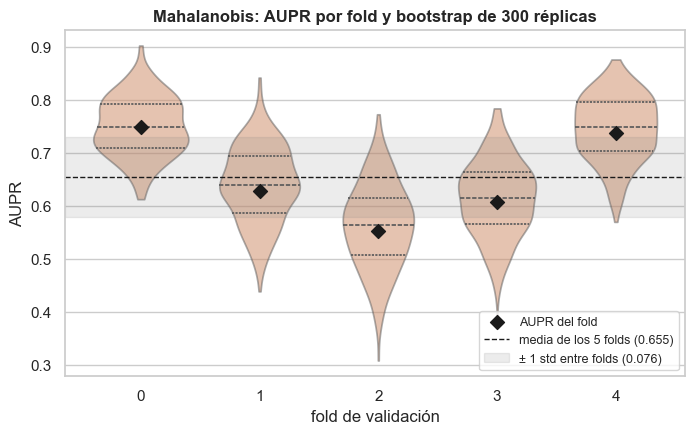

In [10]:
ax = sns.violinplot(data=boot, x="fold", y="aupr", color=FAM["densidad"], inner="quartile", cut=0, alpha=.5)
ax.scatter(range(5), ic.aupr_fold, marker="D", s=50, c="k", zorder=3, label="AUPR del fold")
ax.axhline(r_mah["media"], ls="--", c="k", lw=1, label=f"media de los 5 folds ({r_mah['media']:.3f})")
ax.axhspan(r_mah["media"] - r_mah["std"], r_mah["media"] + r_mah["std"], color="grey", alpha=.15, label=f"± 1 std entre folds ({r_mah['std']:.3f})")
ax.set(xlabel="fold de validación", ylabel="AUPR", title="Mahalanobis: AUPR por fold y bootstrap de 300 réplicas")
ax.legend(loc="lower right", fontsize=9);

> **Conclusión:** Los 5 folds tienen **41–42 fraudes** (0,171–0,176 %). Con el mismo detector (Mahalanobis, **0,655 ± 0,076**), la AUPR va de **0,554** (fold 2) a **0,749** (fold 0), y dentro de cada fold el bootstrap la mueve en una banda p5–p95 de **0,18 a 0,26** de ancho. Con ~41 fraudes, la AUPR de un fold es muy ruidosa, y la del test fijo (89 fraudes) también. → **Impacto:** regla para todo el notebook: una diferencia de medias menor que ~1 std entre folds (≈ 0,08) **no es concluyente**, salvo que se repita en al menos 4 de los 5 folds (`plot_folds`). La dificultad de cada fold es común a todos los detectores, así que comparar fold a fold es más fino que mirar la std. El test de §12 solo confirma; no elige.

## 2. ¿Cuánto da el GMM del profesor?

**Qué miramos y por qué.** El punto de partida: `GaussianMixture(5)` sobre las 21 variables crudas y sin escalar, ajustado con los "datos ok" (notebook de partida, celda 20). En el test fijo da **0,567**; aquí se mide con el protocolo de §1. Después se le añade el preprocesado del 01 paso a paso, para separar el efecto de los datos del efecto del modelo (teoria/01, A.2).

In [11]:
from sklearn.mixture import GaussianMixture
# tal cual el notebook de partida: 21 variables crudas (Amount sin transformar) y sin escalar
evaluar("GMM 5 (crudo)", GaussianMixture(5, random_state=SEED), "densidad", feats=FEAT_RAW, datos=tr);

GMM 5 (crudo): CV AUPR = 0.533 ± 0.077  (13 s)


El mismo modelo con el preprocesado del 01: primero `log1p_Amount` en lugar de `Amount` (§6 del 01) y después también `amount_freq` (§13 del 01), que completa el conjunto por defecto `FEATURES`.

In [12]:
FEAT_LOG = [f"X{i}" for i in range(1, 21)] + ["log1p_Amount"]
evaluar("GMM 5 (log1p)", GaussianMixture(5, random_state=SEED), "densidad", feats=FEAT_LOG)
evaluar("GMM 5 (log1p + freq)", GaussianMixture(5, random_state=SEED), "densidad");

GMM 5 (log1p): CV AUPR = 0.637 ± 0.130  (22 s)


GMM 5 (log1p + freq): CV AUPR = 0.638 ± 0.079  (15 s)


In [13]:
GMM5 = ["GMM 5 (crudo)", "GMM 5 (log1p)", "GMM 5 (log1p + freq)"]
tabla_cv(GMM5).drop(columns=["familia", "segundos"])

,n_feats,media,std,fold0,fold1,fold2,fold3,fold4
GMM 5 (log1p + freq),22.0,0.638,0.079,0.734,0.616,0.526,0.592,0.722
GMM 5 (log1p),21.0,0.637,0.130,0.815,0.613,0.426,0.609,0.721
GMM 5 (crudo),21.0,0.533,0.077,0.648,0.458,0.454,0.511,0.593


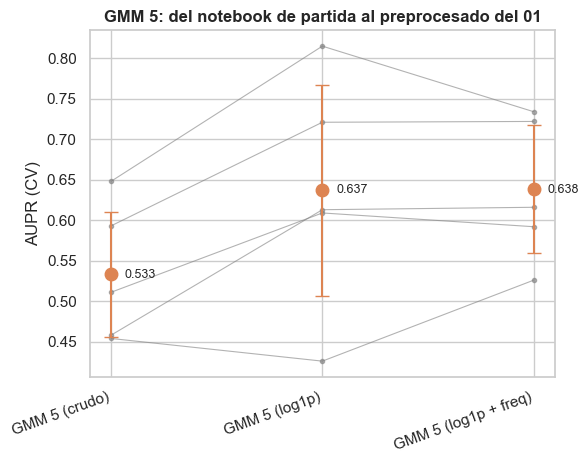

In [14]:
plot_folds(GMM5, title="GMM 5: del notebook de partida al preprocesado del 01");

¿Dónde caen los fraudes? Distribución del score *out-of-fold* ($-\log p(x)$) del mejor de los tres, con el p99 de los normales como referencia (como en §9 del 01).

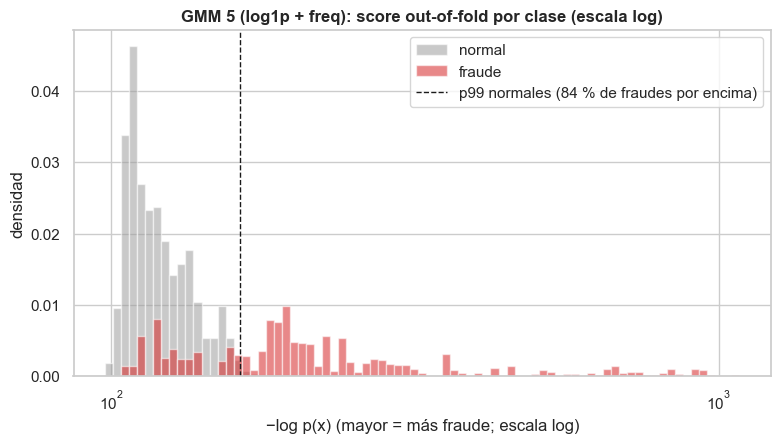

In [15]:
mejor = tabla_cv(GMM5).index[0]
s_gmm, y_np = OOF[mejor], y_train.to_numpy()
p99 = np.quantile(s_gmm[y_np == 0], .99)
ax = hist_score(s_gmm, y_np, f"{mejor}: score out-of-fold por clase (escala log)")
ax.axvline(p99, ls="--", c="k", lw=1, label=f"p99 normales ({100 * (s_gmm[y_np == 1] > p99).mean():.0f} % de fraudes por encima)")
ax.set_xlabel("−log p(x) (mayor = más fraude; escala log)")
ax.legend();

> **Conclusión:** El GMM 5 del profesor da **0,533 ± 0,077** en CV (0,567 en el test fijo, dentro del ruido de §1). Con `log1p_Amount` sube a **0,637 ± 0,130** (gana en 4 de los 5 folds). Añadir `amount_freq` da **0,638 ± 0,079**: frente a `log1p` solo no es concluyente (gana en 3 de 5), pero baja la std y sube el peor fold de 0,426 a 0,526, y al crudo le gana en los **5 folds**. El **84 %** de los fraudes supera el p99 de los normales; el resto, **~1 de cada 6**, cae dentro de la nube, como en §9 del 01. → **Impacto:** `FEATURES` (`log1p_Amount` + `amount_freq`) queda como conjunto por defecto (confirma D-1.2 y D-1.4). Ese ~16 % de fraudes parece normal a cualquier detector de rareza global: en la Parte I lo que queda por ganar es ordenar mejor la cola derecha.

## 3. ¿Distancia o densidad?

**Qué miramos y por qué.** "Si estoy utilizando la euclídea en un sitio donde debería utilizar Mahalanobis, estoy ordenando mis puntos mal en el espacio" [01:30:19]. Comparamos, sobre `FEATURES` estandarizadas, la **euclídea** al centroide de los normales (ignora las correlaciones), **Mahalanobis** (§1) y **Mahalanobis robusta** (`MinCovDet`). Mahalanobis ordena igual que el $-\log p(x)$ de una gaussiana, así que cuenta como densidad: es la prueba de que "los métodos de probabilidad van a ser mejores que los de distancia" [01:39:33].

In [16]:
class Euclidea(OutlierMixin, BaseEstimator):
    """Distancia euclídea al centroide de los normales: score_samples = −‖x − μ‖² (mayor = más normal)."""
    def fit(self, X, y=None):
        self.centro_ = X.mean(axis=0)
        return self
    def score_samples(self, X):
        return -((X - self.centro_) ** 2).sum(axis=1)

evaluar("Euclídea (std)", make_pipe(Euclidea()), "distancia");

Euclídea (std): CV AUPR = 0.316 ± 0.065  (0 s)


`MinCovDet` con los ~95.000 normales de cada fold tarda unos 2 minutos por ajuste. Se ajusta con una **submuestra de 20.000 normales** (fija, `SEED`), suficiente para estimar 22 medias y una covarianza 22 × 22. Hereda `score_samples` del wrapper de §1.

In [17]:
from sklearn.covariance import MinCovDet

class MahalanobisRobusta(Mahalanobis):
    """Mahalanobis con covarianza robusta (MCD) ajustada en una submuestra de n normales."""
    def __init__(self, n=20_000, random_state=SEED):
        self.n, self.random_state = n, random_state
    def fit(self, X, y=None):
        idx = np.random.default_rng(self.random_state).choice(len(X), min(self.n, len(X)), replace=False)
        self.cov_ = MinCovDet(random_state=self.random_state).fit(X[idx])
        return self

evaluar("Mahalanobis robusta (20k)", make_pipe(MahalanobisRobusta()), "densidad");

Mahalanobis robusta (20k): CV AUPR = 0.384 ± 0.205  (10 s)


In [18]:
DIST = ["Euclídea (std)", "Mahalanobis", "Mahalanobis robusta (20k)"]
tabla_cv(DIST).drop(columns=["familia", "segundos"])

,n_feats,media,std,fold0,fold1,fold2,fold3,fold4
Mahalanobis,22.0,0.655,0.076,0.749,0.628,0.554,0.607,0.737
Mahalanobis robusta (20k),22.0,0.384,0.205,0.418,0.261,0.219,0.252,0.769
Euclídea (std),22.0,0.316,0.065,0.366,0.284,0.227,0.292,0.411


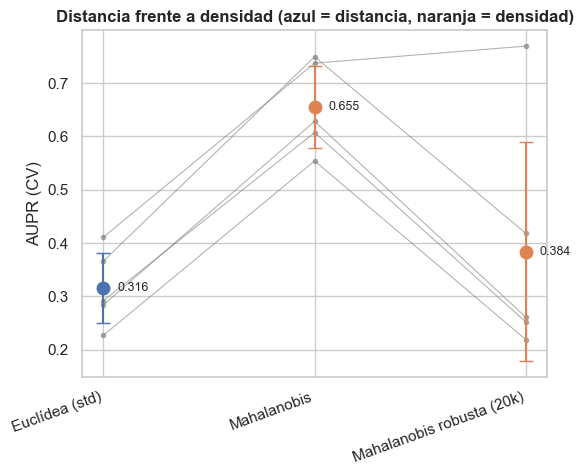

In [19]:
plot_folds(DIST, title="Distancia frente a densidad (azul = distancia, naranja = densidad)");

La robusta, además de perder en 4 de los 5 folds, es inestable: va de 0,219 a 0,769 según el fold. ¿Por qué empeora? Porque estrecha la elipse. Con colas tan pesadas, la MCD describe solo el núcleo de los normales, y muchos normales de la cola pasan a parecer tan raros como los fraudes. Lo medimos con el % de puntos de validación fuera del contorno $\chi^2_{22}$ al 99 % (lo que dejaría fuera una gaussiana perfecta: un 1 %).

In [20]:
corte = stats.chi2.ppf(.99, df=len(FEATURES))
y_np = y_train.to_numpy()
fuera = lambda n, k: 100 * (OOF[n][y_np == k] > corte).mean()      # OOF = d² de Mahalanobis
pd.DataFrame({n: {"% normales fuera": fuera(n, 0), "% fraudes fuera": fuera(n, 1)} for n in DIST[1:]}).T.round(1)

,% normales fuera,% fraudes fuera
Mahalanobis,5.9,89.8
Mahalanobis robusta (20k),56.7,97.1


La elipse clásica ya deja fuera al 5,9 % de los normales (sus colas pesan más que las de una gaussiana); la robusta, a más de la mitad. Para la MCD, la cola de los normales es tan rara como el fraude.

¿Por qué la euclídea ordena mal? En las 22 dimensiones hay una dirección en la que los normales **casi no varían**. Es la de mínima varianza de su matriz de covarianza (calculada solo con normales). Su varianza es mucho menor que la de cualquier variable estandarizada (= 1), y estas son sus cargas principales:

In [21]:
X0 = X_train[y_train == 0]
sc = StandardScaler().fit(X0)
w, V = np.linalg.eigh(np.cov(sc.transform(X0).T))        # autovalores en orden creciente
V[:, 0] *= np.sign(V[FEATURES.index("X17"), 0])            # signo del eje menor: X17 positiva
cargas = pd.Series(V[:, 0], index=FEATURES)
cargas[cargas.abs().nlargest(6).index].round(2).rename(f"eje menor (varianza {w[0]:.2f})").to_frame().T

,X17,X12,X14,X10,X7,X16
eje menor (varianza 0.16),0.45,0.34,0.34,0.31,0.29,0.29


En la base propia de los normales (sus autovectores), la euclídea suma el cuadrado de cada coordenada **con el mismo peso**. Mahalanobis divide cada cuadrado por la varianza de ese eje: un desvío en el eje menor pesa $1/0{,}16 \approx 6$ veces más que en un eje de varianza 1.

In [22]:
P0, P1 = sc.transform(X0) @ V, sc.transform(X_train[y_train == 1]) @ V     # coordenadas en la base propia
d2_eu = lambda P, ejes=slice(None): (P[:, ejes] ** 2).sum(1)              # euclídea: todos los ejes pesan igual
d2_ma = lambda P, ejes=slice(None): (P[:, ejes] ** 2 / w[ejes]).sum(1)    # Mahalanobis: cada eje / su varianza
E = [-1, 0]                                                               # plano (eje mayor, eje menor)

Primero, el plano formado por el eje mayor y el eje menor, con el contorno que deja fuera el 0,1 % de los normales en cada métrica:

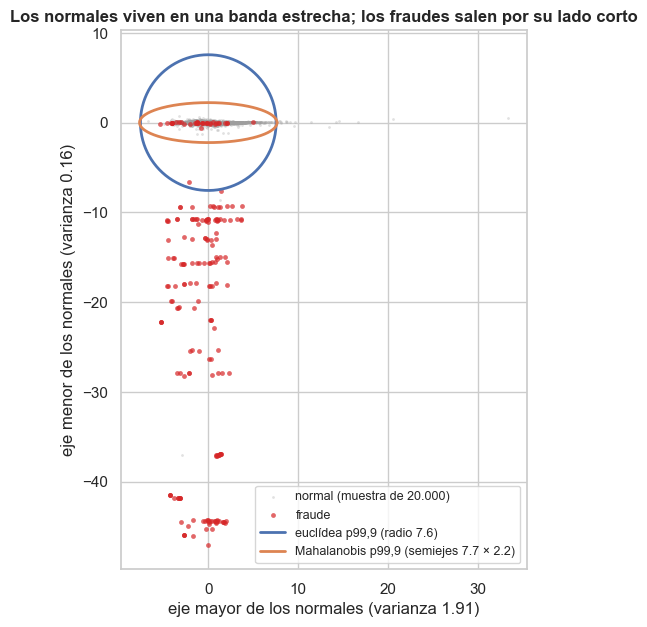

In [23]:
r_eu, r_ma, t = np.quantile(d2_eu(P0, E), .999), np.quantile(d2_ma(P0, E), .999), np.linspace(0, 2 * np.pi, 300)
m = np.random.default_rng(SEED).choice(len(P0), 20_000, replace=False)      # muestra de normales para pintar
fig, ax = plt.subplots(figsize=(8, 7))
ax.scatter(*P0[m][:, E].T, s=4, c=C[0], alpha=.3, linewidths=0, label="normal (muestra de 20.000)")
ax.scatter(*P1[:, E].T, s=12, c=C[1], alpha=.7, linewidths=0, label="fraude")
ax.plot(np.sqrt(r_eu) * np.cos(t), np.sqrt(r_eu) * np.sin(t), c=FAM["distancia"], lw=2, label=f"euclídea p99,9 (radio {np.sqrt(r_eu):.1f})")
ax.plot(np.sqrt(r_ma * w[-1]) * np.cos(t), np.sqrt(r_ma * w[0]) * np.sin(t), c=FAM["densidad"], lw=2,
        label=f"Mahalanobis p99,9 (semiejes {np.sqrt(r_ma * w[-1]):.1f} × {np.sqrt(r_ma * w[0]):.1f})")
ax.set(xlabel=f"eje mayor de los normales (varianza {w[-1]:.2f})", ylabel=f"eje menor de los normales (varianza {w[0]:.2f})",
       title="Los normales viven en una banda estrecha; los fraudes salen por su lado corto", aspect="equal")
ax.legend(loc="lower right", fontsize=9);

En dos dimensiones las dos métricas aún separan parecido. El problema aparece al sumar las 22: las colas pesadas de los normales en las otras 21 direcciones inflan la distancia euclídea tanto como el desvío del fraude en el eje menor. Cada punto, con sus dos distancias:

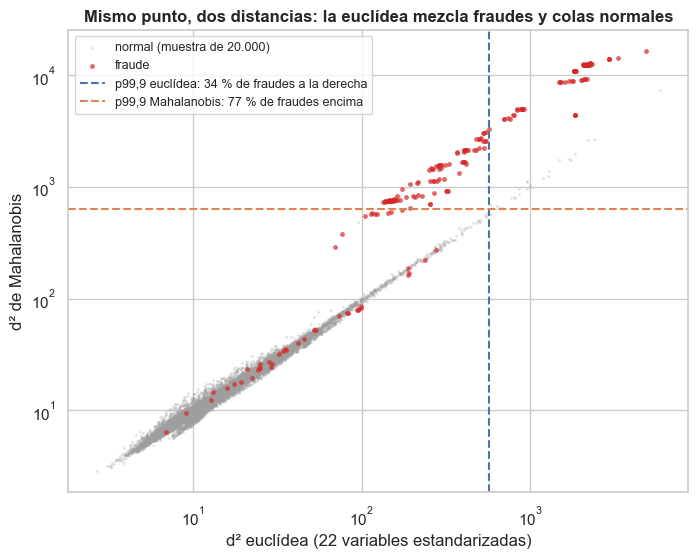

In [24]:
p999 = {"euclídea": np.quantile(d2_eu(P0), .999), "Mahalanobis": np.quantile(d2_ma(P0), .999)}
pct = {"euclídea": 100 * (d2_eu(P1) > p999["euclídea"]).mean(), "Mahalanobis": 100 * (d2_ma(P1) > p999["Mahalanobis"]).mean()}
fig, ax = plt.subplots(figsize=(8, 6))
ax.scatter(d2_eu(P0[m]), d2_ma(P0[m]), s=4, c=C[0], alpha=.3, linewidths=0, label="normal (muestra de 20.000)")
ax.scatter(d2_eu(P1), d2_ma(P1), s=12, c=C[1], alpha=.7, linewidths=0, label="fraude")
ax.axvline(p999["euclídea"], c=FAM["distancia"], ls="--", lw=1.5, label=f"p99,9 euclídea: {pct['euclídea']:.0f} % de fraudes a la derecha")
ax.axhline(p999["Mahalanobis"], c=FAM["densidad"], ls="--", lw=1.5, label=f"p99,9 Mahalanobis: {pct['Mahalanobis']:.0f} % de fraudes encima")
ax.set(xscale="log", yscale="log", xlabel="d² euclídea (22 variables estandarizadas)", ylabel="d² de Mahalanobis",
       title="Mismo punto, dos distancias: la euclídea mezcla fraudes y colas normales")
ax.legend(loc="upper left", fontsize=9);

> **Conclusión:** Con las mismas `FEATURES`, Mahalanobis da **0,655 ± 0,076** y la euclídea **0,316 ± 0,065**: más del doble, y en los 5 folds. Los normales casi no varían en la dirección X17 + X12 + X14 + X10 + … (varianza **0,16**), justo por donde salen los fraudes (la cola diagonal de §8 del 01). La euclídea no da más peso a esa dirección y mezcla los fraudes con las colas normales: supera el p99,9 de los normales el **34 %** de los fraudes, frente al **77 %** con Mahalanobis (en todo train, como cifra explicativa; la comparación válida es la de CV). La robusta cae a **0,384 ± 0,205**, porque su elipse deja fuera al **56,7 %** de los normales. → **Impacto:** manda la covarianza, y la clásica: las colas de los normales son normales, no ruido. La euclídea queda descartada. Una sola gaussiana ya iguala al GMM 5 de §2 (0,655 frente a 0,638, no concluyente); §4 le da más flexibilidad.

## 4. ¿Cuántas gaussianas y con qué escala?

**Qué miramos y por qué.** El GMM es el detector de densidad de referencia: "el modelo tiene que ser suficientemente complicado" [02:41:01], pero no más. Aquí fijamos sus tres hiperparámetros (escalador, nº de componentes K y tipo de covarianza) por AUPR en CV, no por verosimilitud ni BIC. Además comprobamos la afirmación de D-1.2 de que un GMM `full` no cambia con escalados lineales.

Nombres cortos para los tres escaladores (con un tono de la paleta de densidad cada uno) y tres semillas para separar el efecto de la escala del de la inicialización.

In [25]:
from sklearn.cluster import KMeans

ESC = {None: "sin escalar", "standard": "standard", "robust": "robust"}
COL_ESC = dict(zip(ESC, sns.light_palette(FAM["densidad"], n_colors=4)[1:]))   # más oscuro = robust
SEMILLAS = [SEED, SEED + 1, SEED + 2]
gmm = lambda K, sc, rs=SEED, **kw: make_pipe(GaussianMixture(K, random_state=rs, **kw), sc)
nom = lambda sc, rs=SEED, K=5: f"GMM {K} ({ESC[sc]})" + ("" if rs == SEED else f" · s{rs}")

**Escalador.** GMM de 5 componentes `full` (las del profesor) con los tres escaladores y tres semillas (`random_state` de EM). Si las diferencias fueran solo ruido de la semilla, el orden de los escaladores cambiaría de una semilla a otra.

In [26]:
for rs in SEMILLAS:
    for sc in ESC:
        evaluar(nom(sc, rs), gmm(5, sc, rs), "densidad")

GMM 5 (sin escalar): CV AUPR = 0.638 ± 0.079  (15 s)


GMM 5 (standard): CV AUPR = 0.660 ± 0.094  (21 s)


GMM 5 (robust): CV AUPR = 0.734 ± 0.075  (19 s)


GMM 5 (sin escalar) · s43: CV AUPR = 0.634 ± 0.078  (17 s)


GMM 5 (standard) · s43: CV AUPR = 0.700 ± 0.071  (30 s)


GMM 5 (robust) · s43: CV AUPR = 0.749 ± 0.056  (20 s)


GMM 5 (sin escalar) · s44: CV AUPR = 0.642 ± 0.073  (15 s)


GMM 5 (standard) · s44: CV AUPR = 0.661 ± 0.061  (28 s)


GMM 5 (robust) · s44: CV AUPR = 0.743 ± 0.074  (18 s)


Lo mismo con K = 10, solo con la semilla común (cada configuración cuesta unas tres veces más).

In [27]:
for sc in ESC:
    evaluar(nom(sc, K=10), gmm(10, sc), "densidad")

GMM 10 (sin escalar): CV AUPR = 0.537 ± 0.137  (60 s)


GMM 10 (standard): CV AUPR = 0.678 ± 0.092  (61 s)


GMM 10 (robust): CV AUPR = 0.731 ± 0.079  (56 s)


Prueba de la invarianza: con `init_params="random"` EM arranca de responsabilidades aleatorias que **no miran X**. Si D-1.2 tiene razón, los tres escaladores deben dar la misma AUPR.

In [28]:
for sc in ESC:
    evaluar(f"GMM 5 init aleatoria ({ESC[sc]})", gmm(5, sc, init_params="random"), "densidad")

GMM 5 init aleatoria (sin escalar): CV AUPR = 0.646 ± 0.106  (22 s)


GMM 5 init aleatoria (standard): CV AUPR = 0.646 ± 0.106  (22 s)


GMM 5 init aleatoria (robust): CV AUPR = 0.646 ± 0.106  (22 s)


Resumen: AUPR media de CV por configuración y escalador, y en cuántos de los 5 folds robust gana a standard (comparación por pares).

In [29]:
por_fold = lambda n: np.array([RES[n][f"fold{k}"] for k in range(5)])
filas = {f"K = 5 · semilla {rs}": [nom(sc, rs) for sc in ESC] for rs in SEMILLAS}
filas["K = 10 · semilla 42"] = [nom(sc, K=10) for sc in ESC]
filas["K = 5 · init aleatoria"] = [f"GMM 5 init aleatoria ({ESC[sc]})" for sc in ESC]
t_esc = pd.DataFrame({f: [RES[n]["media"] for n in ns] for f, ns in filas.items()}, index=ESC.values()).T.round(3)
t_esc["folds robust > standard"] = pd.array([int((por_fold(ns[2]) > por_fold(ns[1])).sum()) if "aleatoria" not in f else pd.NA
                                             for f, ns in filas.items()], dtype="Int64")   # init aleatoria: empate
t_esc

,sin escalar,standard,robust,folds robust > standard
K = 5 · semilla 42,0.638,0.660,0.734,4
K = 5 · semilla 43,0.634,0.700,0.749,4
K = 5 · semilla 44,0.642,0.661,0.743,5
K = 10 · semilla 42,0.537,0.678,0.731,4
K = 5 · init aleatoria,0.646,0.646,0.646,<NA>


Robust gana con las tres semillas y con K = 10, y a standard en 4 o 5 de los 5 folds: no es suerte de la semilla. Con init aleatoria, los tres escaladores empatan.

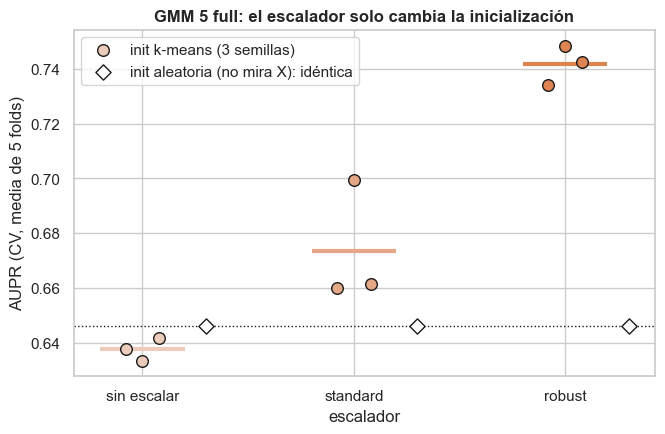

In [30]:
# cada punto = AUPR media de CV con una semilla (barra = media de las 3); rombos = init aleatoria
fig, ax = plt.subplots(figsize=(7.5, 4.5))
for i, sc in enumerate(ESC):
    m = [RES[nom(sc, rs)]["media"] for rs in SEMILLAS]
    ax.scatter(i + np.array([-.08, 0, .08]), m, s=70, color=COL_ESC[sc], edgecolor="k", zorder=3,
               label="init k-means (3 semillas)" if i == 0 else None)
    ax.hlines(np.mean(m), i - .2, i + .2, color=COL_ESC[sc], lw=3)
    ax.scatter(i + .3, RES[f"GMM 5 init aleatoria ({ESC[sc]})"]["media"], marker="D", s=60, color="w", edgecolor="k",
               zorder=3, label="init aleatoria (no mira X): idéntica" if i == 0 else None)
ax.axhline(RES["GMM 5 init aleatoria (robust)"]["media"], ls=":", c="k", lw=1)
ax.set_xticks(range(3), ESC.values())
ax.set(xlabel="escalador", ylabel="AUPR (CV, media de 5 folds)", title="GMM 5 full: el escalador solo cambia la inicialización")
ax.legend(loc="upper left");

¿Por qué cambia la inicialización? EM arranca de un k-means, y k-means usa la **euclídea**, que sí depende de la escala. Tamaño de los 5 grupos iniciales en los normales de train según el escalador:

In [31]:
# el mismo KMeans que usa GaussianMixture para arrancar (n_init=1, misma semilla)
X0 = X_train[y_train == 0].to_numpy(float)
pd.DataFrame({ESC[sc]: np.sort(np.bincount(make_pipe(KMeans(5, n_init=1, random_state=SEED), sc).fit(X0)[-1].labels_))[::-1]
              for sc in ESC}, index=[f"grupo {k + 1}" for k in range(5)])

,sin escalar,standard,robust
grupo 1,49849,48874,91183
grupo 2,43035,34439,17723
grupo 3,14297,16038,5636
grupo 4,6566,11089,3823
grupo 5,5665,8972,1047


Peso relativo de cada variable en esa euclídea: con robust, las variables de colas pesadas pesan más que con standard (std/IQR > 1).

In [32]:
q = X_train[y_train == 0].quantile([.25, .75])
peso = (X_train[y_train == 0].std() / (q.loc[.75] - q.loc[.25])).rename("std / IQR")
peso.sort_values(ascending=False).head(4).round(2).to_frame().T

,amount_freq,X20,X8,X2
std / IQR,3.54,2.24,2.17,1.18


Con robust, `amount_freq` pesa 3,5 veces más que con standard, y k-means arranca con un grupo central de 91.183 normales y cuatro pequeños. Sin escalar y con standard, reparte los normales en dos grupos grandes. Cada arranque lleva a EM a un óptimo local distinto.

**Número de componentes.** Con robust y la semilla común, K de 1 (= Mahalanobis) a 10. En el eje derecho, la −log-verosimilitud media de los normales de validación (scores *out-of-fold*): es lo que optimizaría un criterio no supervisado como el BIC.

In [33]:
# K = 5 y K = 10 ya están evaluados arriba
KS = [1, 2, 3, 5, 7, 10]
for K in [1, 2, 3, 7]:
    evaluar(nom("robust", K=K), gmm(K, "robust"), "densidad")

GMM 1 (robust): CV AUPR = 0.655 ± 0.076  (1 s)


GMM 2 (robust): CV AUPR = 0.641 ± 0.069  (3 s)


GMM 3 (robust): CV AUPR = 0.733 ± 0.063  (17 s)


GMM 7 (robust): CV AUPR = 0.636 ± 0.067  (50 s)


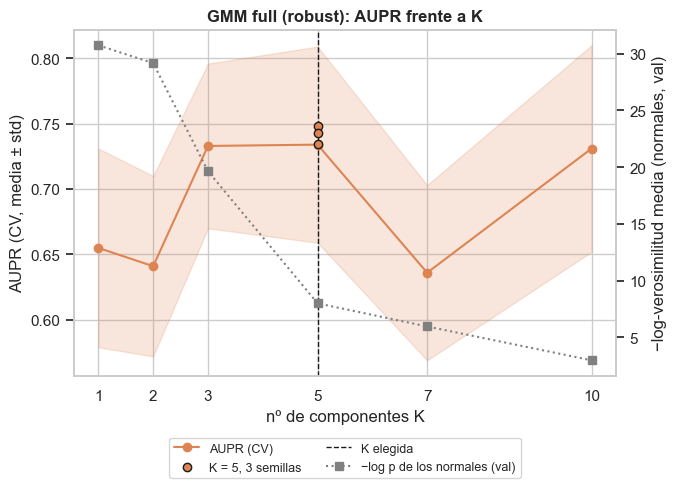

In [34]:
# AUPR media ± std frente a K; puntos = las 3 semillas de K = 5; línea punteada = ajuste a los normales
nombres_k = [nom("robust", K=K) for K in KS]
ax = plot_curva(KS, nombres_k, "nº de componentes K", "GMM full (robust): AUPR frente a K", label="AUPR (CV)")
ax.get_lines()[-1].set_color(FAM["densidad"]); ax.collections[-1].set_color(FAM["densidad"])
ax.scatter([5] * 3, [RES[nom("robust", rs)]["media"] for rs in SEMILLAS], color=COL_ESC["robust"], edgecolor="k", zorder=3, label="K = 5, 3 semillas")
ax.axvline(5, ls="--", c="k", lw=1, label="K elegida")
ax2 = ax.twinx(); ax2.grid(False)
ax2.plot(KS, [OOF[n][y_train.to_numpy() == 0].mean() for n in nombres_k], ls=":", marker="s", c="grey", label="−log p de los normales (val)")
ax2.set_ylabel("−log-verosimilitud media (normales, val)")
ax.set_xticks(KS)
ax2.legend(handles=ax.get_legend_handles_labels()[0] + ax2.get_legend_handles_labels()[0], loc="upper center",
           bbox_to_anchor=(.5, -.16), ncol=2, fontsize=9);

La AUPR no crece con la complejidad: K = 1 (= Mahalanobis) da 0,655, K = 3, 5 y 10 empatan en torno a 0,73 y K = 7 cae a 0,636. Hay una sola semilla por K, así que los saltos entre K vecinas pueden ser de inicialización. La verosimilitud de los normales, en cambio, mejora siempre con K: un criterio no supervisado (verosimilitud o BIC) habría elegido el modelo más grande. Nos quedamos con K = 5: empata con K = 3 y K = 10, y es la única K comprobada con tres semillas.

**Tipo de covarianza.** Con K = 5 y robust: `full` (cada gaussiana con su elipse), `tied` (una elipse común) y `diag` (variables independientes dentro de cada gaussiana).

In [35]:
for cov in ["tied", "diag"]:
    evaluar(f"GMM 5 {cov} (robust)", gmm(5, "robust", covariance_type=cov), "densidad")
t_cov = tabla_cv([nom("robust"), "GMM 5 tied (robust)", "GMM 5 diag (robust)"])
t_cov[["media", "std", "segundos"] + [f"fold{k}" for k in range(5)]]

GMM 5 tied (robust): CV AUPR = 0.652 ± 0.075  (6 s)


GMM 5 diag (robust): CV AUPR = 0.512 ± 0.063  (5 s)


,media,std,segundos,fold0,fold1,fold2,fold3,fold4
GMM 5 (robust),0.734,0.075,18.691,0.835,0.616,0.700,0.737,0.783
GMM 5 tied (robust),0.652,0.075,6.045,0.744,0.626,0.557,0.596,0.736
GMM 5 diag (robust),0.512,0.063,4.782,0.608,0.491,0.428,0.475,0.556


`full` gana a `tied` en 4 de los 5 folds y a `diag` en los 5, como anticipaba el EDA: el fraude es una anomalía dependiente (correlación media 0,415 frente a 0,036, §7 del 01), y las gaussianas necesitan su propia elipse.

**Estabilidad.** La configuración elegida con sus tres semillas: si la dispersión entre semillas es pequeña frente a la de los folds, basta `n_init=1`.

In [36]:
m_rs = np.array([RES[nom("robust", rs)]["media"] for rs in SEMILLAS])
pd.Series({"AUPR media (3 semillas)": m_rs.mean(), "std entre semillas": m_rs.std(), "rango entre semillas": np.ptp(m_rs),
           "std entre folds (semilla común)": RES[nom("robust")]["std"]}, name="GMM 5 full (robust)").round(3).to_frame()

,GMM 5 full (robust)
AUPR media (3 semillas),0.742
std entre semillas,0.006
rango entre semillas,0.014
std entre folds (semilla común),0.075


La configuración elegida queda en `RES` con su nombre definitivo, y el estimador sin ajustar en `GMM_FINAL` para §10.

In [37]:
RES["GMM 5 full (robust)"], OOF["GMM 5 full (robust)"] = RES.pop(nom("robust")), OOF.pop(nom("robust"))
GMM_FINAL = make_pipe(GaussianMixture(5, covariance_type="full", random_state=SEED), "robust")
tabla_cv(["GMM 5 full (robust)"])[["media", "std", "segundos"]]

,media,std,segundos
GMM 5 full (robust),0.734,0.075,18.691


> **Conclusión:** D-1.2 acierta a medias. Con arranque aleatorio, los tres escaladores dan **0,646**: el EM de un GMM `full` no cambia con la escala. Pero el arranque por defecto es un k-means, que sí cambia, y con robust el GMM 5 da **0,734 / 0,749 / 0,743** en tres semillas, frente a 0,660–0,700 con standard, y le gana en **4, 4 y 5 de los 5 folds**. K = 3, 5 y 10 empatan (**0,733, 0,734 y 0,731**), y `full` supera a `tied` (0,652) y a `diag` (0,512). → **Impacto:** D-1.2 se cierra con **RobustScaler** para la familia densidad, con la frase corregida: el modelo no depende de la escala, el ajuste sí. Configuración final: **GMM 5 full (robust)**, **0,734 ± 0,075** en CV (`GMM_FINAL`), estable entre semillas (± 0,006) y con menos de la mitad del coste de K = 10.

## 5. ¿Sirven los vecinos?

**Qué miramos y por qué.** Hasta aquí, un punto es raro si está lejos del centro (§3) o en una zona de baja densidad del modelo global (§4). Los métodos de vecindad no ajustan ningún modelo: miran solo alrededor de cada punto. Probamos los dos de la teoría: la distancia a los normales más cercanos ("una de las más típicas es intentar buscar el punto más cercano dentro de la clase" [01:32:29]) y **LOF**, que compara la densidad del punto con la de sus vecinos (slides p45–p46). Su problema conocido es el coste: "todos escalan muy mal" [02:59:58].

**kNN-distancia.** El score es la distancia euclídea media a los k normales más cercanos. sklearn no lo trae como detector, así que va en un wrapper con `NearestNeighbors`. La referencia es una **submuestra de 20.000 normales** del fold de train (fija, `SEED`): el coste de puntuar crece con filas de referencia × filas puntuadas, y con los ~95.500 normales de cada fold sería unas 5 veces mayor, también al puntuar test y producción.

In [38]:
from sklearn.neighbors import NearestNeighbors, LocalOutlierFactor

class KNNDist(OutlierMixin, BaseEstimator):
    """Distancia media a los k normales más cercanos de una submuestra de n: score_samples = −distancia (mayor = más normal)."""
    def __init__(self, k=20, n=20_000, random_state=SEED):
        self.k, self.n, self.random_state = k, n, random_state
    def fit(self, X, y=None):
        idx = np.random.default_rng(self.random_state).choice(len(X), min(self.n, len(X)), replace=False)
        self.nn_ = NearestNeighbors(n_neighbors=self.k).fit(X[idx])
        return self
    def score_samples(self, X):
        return -self.nn_.kneighbors(X)[0].mean(axis=1)

Barrido de k con los dos escaladores. Aquí el escalador cambia el propio score, no solo el arranque como en el GMM de §4: la distancia euclídea depende de cuánto pesa cada variable.

In [39]:
KS_V = [1, 5, 10, 20, 50]
for sc in ["standard", "robust"]:
    for k in KS_V:
        evaluar(f"kNN {k} ({sc})", make_pipe(KNNDist(k), sc), "vecindad")

kNN 1 (standard): CV AUPR = 0.424 ± 0.074  (2 s)


kNN 5 (standard): CV AUPR = 0.501 ± 0.059  (2 s)


kNN 10 (standard): CV AUPR = 0.531 ± 0.055  (2 s)


kNN 20 (standard): CV AUPR = 0.533 ± 0.059  (2 s)


kNN 50 (standard): CV AUPR = 0.493 ± 0.059  (2 s)


kNN 1 (robust): CV AUPR = 0.362 ± 0.079  (2 s)


kNN 5 (robust): CV AUPR = 0.393 ± 0.065  (2 s)


kNN 10 (robust): CV AUPR = 0.383 ± 0.064  (2 s)


kNN 20 (robust): CV AUPR = 0.346 ± 0.065  (2 s)


kNN 50 (robust): CV AUPR = 0.293 ± 0.071  (2 s)


In [40]:
# AUPR media por k y escalador; última columna: en cuántos folds standard gana a robust
por_fold = lambda n: np.array([RES[n][f"fold{k}"] for k in range(5)])
t_knn = pd.DataFrame({sc: [RES[f"kNN {k} ({sc})"]["media"] for k in KS_V] for sc in ["standard", "robust"]},
                     index=pd.Index(KS_V, name="k")).round(3)
t_knn["folds standard > robust"] = [int((por_fold(f"kNN {k} (standard)") > por_fold(f"kNN {k} (robust)")).sum()) for k in KS_V]
t_knn

,standard,robust,folds standard > robust
k,,,
1,0.424,0.362,5
5,0.501,0.393,5
10,0.531,0.383,5
20,0.533,0.346,5
50,0.493,0.293,5


Standard gana a robust con todos los k y en los 5 folds (0,533 frente a 0,346 con k = 20). Es el efecto de §4 en sentido contrario: con robust, las variables de colas pesadas (`amount_freq` pesa 3,5 veces más) dominan la distancia euclídea, y aquí esa distancia es el propio score.

**LOF** (`LocalOutlierFactor(novelty=True)`): ajusta con los normales y puntúa filas nuevas. Un LOF ≈ 1 es un punto tan denso como sus vecinos; LOF ≫ 1, uno mucho más aislado que ellos. El wrapper permite elegir la referencia (submuestra de n, todos los normales, deduplicados o no), que usaremos enseguida.

In [41]:
class LOFRef(OutlierMixin, BaseEstimator):
    """LOF de novedad ajustado con una referencia: n normales al azar (n=None: todos), deduplicados o no.
    score_samples = −LOF (mayor = más normal)."""
    def __init__(self, n_neighbors=20, n=20_000, dedup=False, random_state=SEED):
        self.n_neighbors, self.n, self.dedup, self.random_state = n_neighbors, n, dedup, random_state
    def fit(self, X, y=None):
        R = np.unique(X, axis=0) if self.dedup else X           # una fila por grupo de filas idénticas
        if self.n and self.n < len(R):
            R = R[np.random.default_rng(self.random_state).choice(len(R), self.n, replace=False)]
        self.lof_ = LocalOutlierFactor(n_neighbors=self.n_neighbors, novelty=True).fit(R)
        return self
    def score_samples(self, X):
        return self.lof_.score_samples(X)

Mismo barrido para `n_neighbors`, con la submuestra de 20.000 normales, y una comprobación del escalador con k = 20.

In [42]:
KS_LOF = [10, 20, 50]
for k in KS_LOF:
    evaluar(f"LOF {k} (standard)", make_pipe(LOFRef(k), "standard"), "vecindad")
evaluar("LOF 20 (robust)", make_pipe(LOFRef(20), "robust"), "vecindad");

LOF 10 (standard): CV AUPR = 0.572 ± 0.161  (3 s)


LOF 20 (standard): CV AUPR = 0.693 ± 0.082  (3 s)


LOF 50 (standard): CV AUPR = 0.684 ± 0.086  (4 s)


LOF 20 (robust): CV AUPR = 0.686 ± 0.084  (4 s)


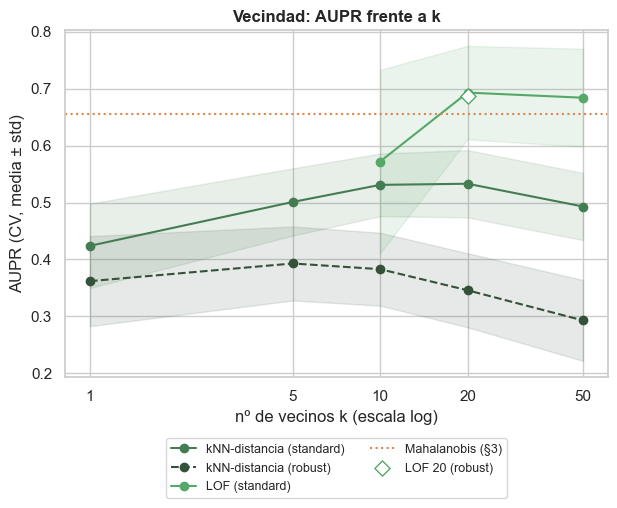

In [43]:
# AUPR media ± std frente al nº de vecinos (referencia: 20.000 normales por fold)
VEC = sns.dark_palette(FAM["vecindad"], n_colors=4)[1:]
curvas = [(KS_V, "kNN {} (standard)", "kNN-distancia (standard)", VEC[1], "-"),
          (KS_V, "kNN {} (robust)", "kNN-distancia (robust)", VEC[0], "--"),
          (KS_LOF, "LOF {} (standard)", "LOF (standard)", VEC[2], "-")]
ax = None
for xs, patron, lab, c, ls in curvas:
    ax = plot_curva(xs, [patron.format(k) for k in xs], "nº de vecinos k (escala log)", "Vecindad: AUPR frente a k", label=lab, ax=ax)
    ax.get_lines()[-1].set(color=c, ls=ls); ax.collections[-1].set(color=c, alpha=.12)
ax.axhline(RES["Mahalanobis"]["media"], c=FAM["densidad"], ls=":", lw=1.5, label="Mahalanobis (§3)")
ax.scatter(20, RES["LOF 20 (robust)"]["media"], marker="D", s=60, color="w", edgecolor=VEC[2], zorder=3, label="LOF 20 (robust)")
ax.set_xscale("log"); ax.set_xticks(KS_V, KS_V)
ax.legend(loc="upper center", bbox_to_anchor=(.5, -.16), ncol=2, fontsize=9);

kNN mejora hasta k = 10–20 (**0,531** y **0,533**) y cae con k = 50, siempre por debajo de Mahalanobis: sigue siendo una distancia euclídea, solo que local. LOF con k = 20 y 50 llega a **0,693** y **0,684**; con k = 10 es inestable (± 0,161). En LOF el escalador casi no importa (0,686 con robust).

**¿Por qué no todos los normales?** La submuestra no es solo por coste. La teoría avisa de un fallo de LOF con duplicados: si un grupo de filas idénticas tiene más copias que `n_neighbors`, su k-distancia es 0, su densidad local es infinita (sklearn avisa: *duplicates > n_neighbors*) y cualquier punto que las tenga de vecinas recibe un LOF enorme. Lo comprobamos con k = 20 y dos referencias completas: **todos** los normales y los normales **deduplicados** (una fila por grupo de X idénticas). Cada ajuste con ~95.000 filas tarda unas 10 veces más que con 20.000.

In [44]:
evaluar("LOF 20 · todos", make_pipe(LOFRef(20, n=None), "standard"), "vecindad")
evaluar("LOF 20 · dedup", make_pipe(LOFRef(20, n=None, dedup=True), "standard"), "vecindad");

LOF 20 · todos: CV AUPR = 0.073 ± 0.037  (39 s)


LOF 20 · dedup: CV AUPR = 0.123 ± 0.066  (38 s)


Con todos los normales, LOF cae a 0,073, y deduplicar solo lo sube a 0,123: muy lejos del 0,693 de la submuestra. Los duplicados no bastan para explicarlo. La otra diferencia entre las referencias es el tamaño del vecindario: 20 vecinos son el 0,1 % de 20.000 filas, pero solo el 0,02 % de ~93.700. Para separar los dos efectos, LOF con los normales deduplicados y luego submuestreados a 20.000, con k = 5 (vecindario del 0,025 %, como el de la referencia completa) y k = 20 (0,1 %):

In [45]:
evaluar("LOF 5 · dedup 20k", make_pipe(LOFRef(5, dedup=True), "standard"), "vecindad")
evaluar("LOF 20 · dedup 20k", make_pipe(LOFRef(20, dedup=True), "standard"), "vecindad");

LOF 5 · dedup 20k: CV AUPR = 0.197 ± 0.085  (4 s)


LOF 20 · dedup 20k: CV AUPR = 0.692 ± 0.086  (4 s)


El mecanismo de los duplicados, en el fold 0: copias de los 15 grupos de normales idénticos más grandes, en la referencia completa y en la submuestra de 20.000 que usa el wrapper.

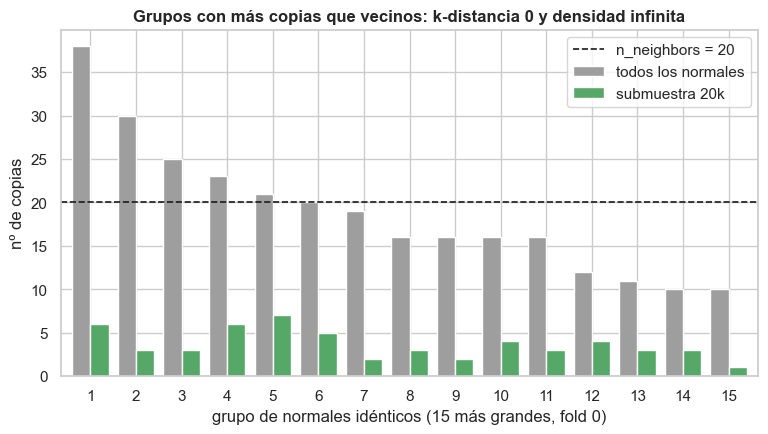

In [46]:
it0 = cv_splits[0][0]
g0 = groups_train.to_numpy()[it0][y_train.to_numpy()[it0] == 0]                  # grupo de cada normal del fold de train, en el orden de fit()
sub0 = g0[np.random.default_rng(SEED).choice(len(g0), 20_000, replace=False)]   # la misma submuestra que LOFRef
cop = pd.DataFrame({"todos los normales": pd.Series(g0).value_counts(), "submuestra 20k": pd.Series(sub0).value_counts()}).fillna(0)
cop = cop.sort_values("todos los normales", ascending=False).head(15).reset_index(drop=True)
ax = cop.plot.bar(color=[C[0], FAM["vecindad"]], width=.8, figsize=(9, 4.5))
ax.axhline(20, ls="--", c="k", lw=1.2, label="n_neighbors = 20")
ax.set(xlabel="grupo de normales idénticos (15 más grandes, fold 0)", ylabel="nº de copias",
       title="Grupos con más copias que vecinos: k-distancia 0 y densidad infinita")
ax.set_xticks(range(15), range(1, 16), rotation=0)
ax.legend();

Resumen de las referencias de LOF. `k / n` es el tamaño del vecindario como fracción de la referencia (fold 0). `LOF > 1.000` cuenta, en los 5 folds de validación, los scores *out-of-fold* degenerados (un LOF sano rara vez pasa de 10).

In [47]:
y_np = y_train.to_numpy()
n_dedup = len(np.unique(X_train.to_numpy(float)[it0][y_np[it0] == 0], axis=0))       # filas distintas entre los normales
REF = {"LOF 20 · todos": ("todos", len(g0), cop.iloc[0, 0], 20), "LOF 20 · dedup": ("dedup", n_dedup, 1, 20),
       "LOF 5 · dedup 20k": ("dedup 20k", 20_000, 1, 5), "LOF 20 · dedup 20k": ("dedup 20k", 20_000, 1, 20),
       "LOF 20 (standard)": ("20k", 20_000, pd.Series(sub0).value_counts().max(), 20)}
t_dup = pd.DataFrame({n: {"referencia": ref, "filas ref.": nr, "copias máx.": int(cm), "k": k, "k / n (%)": round(100 * k / nr, 3),
                          "normales LOF > 1.000": int((OOF[n][y_np == 0] > 1e3).sum()),
                          "fraudes LOF > 1.000": int((OOF[n][y_np == 1] > 1e3).sum()), "AUPR media": round(RES[n]["media"], 3),
                          "std": round(RES[n]["std"], 3), "segundos": round(RES[n]["segundos"])} for n, (ref, nr, cm, k) in REF.items()}).T
t_dup

,referencia,filas ref.,copias máx.,k,k / n (%),normales LOF > 1.000,fraudes LOF > 1.000,AUPR media,std,segundos
LOF 20 · todos,todos,95529,38,20,0.021,83,0,0.073,0.037,39
LOF 20 · dedup,dedup,93668,1,20,0.021,0,0,0.123,0.066,38
LOF 5 · dedup 20k,dedup 20k,20000,1,5,0.025,0,0,0.197,0.085,4
LOF 20 · dedup 20k,dedup 20k,20000,1,20,0.1,0,0,0.692,0.086,4
LOF 20 (standard),20k,20000,7,20,0.1,0,0,0.693,0.082,3


Los dos efectos existen, pero no pesan lo mismo. Con todos los normales, los grupos con más de 20 copias (5 en el fold 0) tienen k-distancia 0 y dan un LOF > 1.000 a **83** normales de validación y a ningún fraude: 83 falsos positivos por delante de todos los fraudes. Deduplicar los elimina. Lo que decide la AUPR es k / n: sin ningún duplicado, LOF da **0,197** con un vecindario del 0,025 % y **0,692** con uno del 0,1 %, lo mismo que la submuestra sin deduplicar (0,693). Nuestra lectura: con un vecindario tan pequeño, cada fraude se compara con unos pocos normales de la cola, igual de dispersos que él, y el cociente de densidades queda cerca de 1. La submuestra arregla las dos cosas a la vez: deja como mucho **7** copias por grupo y ensancha el vecindario, con un coste 10 veces menor.

Esto no toca D-1.1: los folds siguen agrupando duplicados y lo que se puntúa (validación, test, producción) nunca se deduplica. Aquí solo se decide con qué filas se **ajusta** el detector.

**Comparación con la densidad.** Las mejores variantes de kNN y LOF frente a Mahalanobis (§3) y el GMM final (§4), fold a fold.

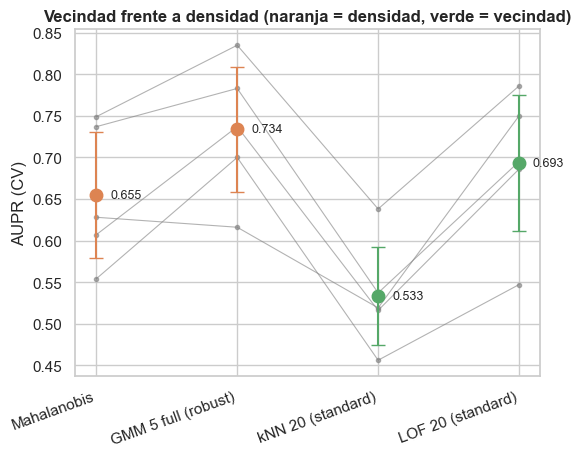

In [48]:
COMP = [n for n in ["Mahalanobis", "GMM 5 full (robust)", "kNN 20 (standard)", "LOF 20 (standard)"] if n in RES]
plot_folds(COMP, title="Vecindad frente a densidad (naranja = densidad, verde = vecindad)");

Los estimadores elegidos quedan sin ajustar en `KNN_FINAL` y `LOF_FINAL` para §10, y sus resultados en `RES` con los nombres de la tabla.

In [49]:
KNN_FINAL = make_pipe(KNNDist(20), "standard")
LOF_FINAL = make_pipe(LOFRef(20), "standard")
tabla_cv(COMP)[["media", "std", "segundos"] + [f"fold{k}" for k in range(5)]]

,media,std,segundos,fold0,fold1,fold2,fold3,fold4
GMM 5 full (robust),0.734,0.075,18.691,0.835,0.616,0.700,0.737,0.783
LOF 20 (standard),0.693,0.082,3.417,0.786,0.750,0.547,0.686,0.695
Mahalanobis,0.655,0.076,3.534,0.749,0.628,0.554,0.607,0.737
kNN 20 (standard),0.533,0.059,2.050,0.638,0.519,0.456,0.516,0.537


> **Conclusión:** Con las 22 variables, la vecindad no bate a la densidad. La mejor kNN-distancia (k = 20, standard) da **0,533 ± 0,059** y pierde con Mahalanobis (0,655) en los 5 folds: sigue siendo una euclídea, solo que local. LOF 20 con una submuestra de 20.000 normales llega a **0,693 ± 0,082**: empata con Mahalanobis (le gana en 3 de 5 folds) y pierde con el GMM 5 full (robust) (0,734) en 4 de 5. Con todos los normales, LOF se hunde a **0,073**, y no por los duplicados (deduplicados, **0,123**): manda el tamaño del vecindario, k / n (**0,692** con un 0,1 % sin ningún duplicado). → **Impacto:** pasan a la Parte II **LOF 20 (standard)** (`LOF_FINAL`) y **kNN 20 (standard)** (`KNN_FINAL`), ajustados con 20.000 normales (k / n = 0,1 %, ≤ 7 copias por grupo, ~3 s por CV). D-1.2 se cierra con **StandardScaler** para la vecindad (robust pierde en kNN en los 5 folds y empata en LOF, 0,686); D-1.1 no cambia. §9 comprobará si la euclídea de kNN mejora con menos variables.

## 6. ¿Aislar o envolver?

**Qué miramos y por qué.** Dos familias que no estiman ninguna densidad. **Isolation Forest** es "de los que están diseñados justo para anomaly detection" [03:00:36]: un punto es anómalo si se aísla con pocos cortes. **One-Class SVM** envuelve a los normales en una frontera con un margen que "depende del usuario" [02:33:07]. Medimos si alguna de las dos llega a la densidad (Mahalanobis, GMM) y, si no, por qué.

**Isolation Forest.** Cada árbol se construye con una submuestra de `max_samples` (ψ) normales, cortando por una variable y un umbral al azar hasta aislar cada punto, con una profundidad máxima de $\log_2 \psi$. El score es la longitud media del camino. Los cortes solo comparan valores de una misma variable, así que IF no cambia con transformaciones monótonas por variable y va **sin escalar**. Barremos ψ (256 es el valor por defecto) y la fracción de variables por árbol (`max_features`), con 300 árboles.

In [50]:
from sklearn.ensemble import IsolationForest

iforest = lambda ms, mf=1.0: IsolationForest(n_estimators=300, max_samples=ms, max_features=mf, random_state=SEED)
nom_if = lambda ms, mf=1.0: f"IF {ms}" + ("" if mf == 1.0 else " (mf 0,5)")
PSI = [256, 2048, 8192, 32768]
for mf in [1.0, 0.5]:
    for ms in PSI:
        evaluar(nom_if(ms, mf), make_pipe(iforest(ms, mf), None), "aislamiento")

IF 256: CV AUPR = 0.276 ± 0.076  (2 s)


IF 2048: CV AUPR = 0.340 ± 0.062  (2 s)


IF 8192: CV AUPR = 0.434 ± 0.094  (3 s)


IF 32768: CV AUPR = 0.504 ± 0.073  (6 s)


IF 256 (mf 0,5): CV AUPR = 0.340 ± 0.093  (6 s)


IF 2048 (mf 0,5): CV AUPR = 0.358 ± 0.086  (6 s)


IF 8192 (mf 0,5): CV AUPR = 0.418 ± 0.078  (7 s)


IF 32768 (mf 0,5): CV AUPR = 0.502 ± 0.076  (8 s)


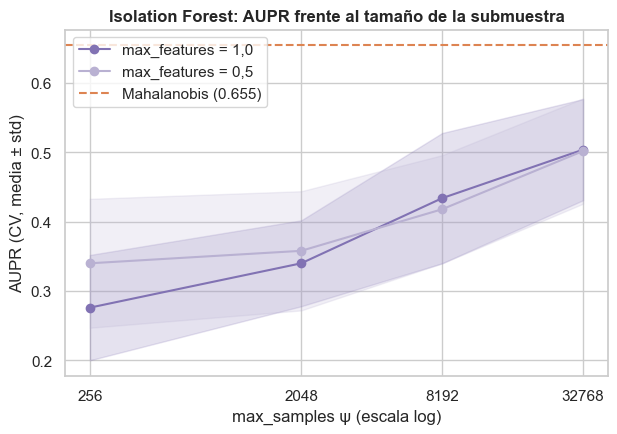

In [51]:
titulo = "Isolation Forest: AUPR frente al tamaño de la submuestra"
ax = plot_curva(PSI, [nom_if(ms) for ms in PSI], "max_samples ψ (escala log)", titulo, label="max_features = 1,0")
plot_curva(PSI, [nom_if(ms, .5) for ms in PSI], "max_samples ψ (escala log)", titulo, label="max_features = 0,5", ax=ax)
for i, col in enumerate([FAM["aislamiento"], sns.light_palette(FAM["aislamiento"], n_colors=3)[1]]):
    ax.get_lines()[i].set_color(col); ax.collections[i].set_color(col)
ax.axhline(RES["Mahalanobis"]["media"], ls="--", c=FAM["densidad"], lw=1.5, label=f"Mahalanobis ({RES['Mahalanobis']['media']:.3f})")
ax.set_xscale("log"); ax.set_xticks(PSI, PSI); ax.minorticks_off()
ax.legend(loc="upper left");

Cuanto mayor es ψ, mejor. Quitar variables por árbol solo ayuda algo con ψ = 256 y nada con ψ grande. Con ψ = 256, cada árbol ve muy pocos normales de las colas: un normal que es extremo en **una** de las 22 variables de colas pesadas se aísla con tan pocos cortes como un fraude. Con más submuestra, las colas de los normales están mejor representadas y los árboles son más profundos. Aun así, el mejor IF (ψ = 32.768) se queda lejos de Mahalanobis.

**¿Por qué tan lejos?** Hipótesis desde §3: el fraude es una **anomalía dependiente**. Sale por la dirección X17 + X12 + X14 + X10 + …, en la que los normales casi no varían, pero cada variable por separado tiene valores que también toman muchos normales. IF corta los ejes de uno en uno y no ve esa dirección. Para comprobarlo, un transformador que da las coordenadas de cada punto en los ejes propios de los normales (los de §3), ajustado dentro de cada fold:

In [52]:
from sklearn.base import TransformerMixin

class EjesPropios(TransformerMixin, BaseEstimator):
    """Coordenadas en los k ejes de menor varianza de los normales estandarizados (k=1: el eje menor de §3).
    con_originales=True: las añade a las variables originales."""
    def __init__(self, k=1, con_originales=False):
        self.k, self.con_originales = k, con_originales
    def fit(self, X, y=None):
        self.sc_ = StandardScaler().fit(X)
        self.V_ = np.linalg.eigh(np.cov(self.sc_.transform(X).T))[1][:, :self.k]    # autovalores en orden creciente
        return self
    def transform(self, X):
        Z = self.sc_.transform(X) @ self.V_
        return np.c_[X, Z] if self.con_originales else Z

Tres variantes del mejor IF: sobre los **22 ejes propios** (los mismos datos, rotados; como IF no cambia con escalados por eje, equivale a blanquearlos), sobre las 22 variables **más el eje menor**, y **solo con el eje menor**.

In [53]:
PSI_FINAL = 32768
evaluar("IF (22 ejes propios)", make_pipeline(EjesPropios(22), iforest(PSI_FINAL)), "aislamiento")
evaluar("IF + eje menor", make_pipeline(EjesPropios(1, con_originales=True), iforest(PSI_FINAL)), "aislamiento")
evaluar("IF (solo eje menor)", make_pipeline(EjesPropios(1), iforest(PSI_FINAL)), "aislamiento");

IF (22 ejes propios): CV AUPR = 0.148 ± 0.033  (6 s)


IF + eje menor: CV AUPR = 0.600 ± 0.072  (6 s)


IF (solo eje menor): CV AUPR = 0.738 ± 0.045  (4 s)


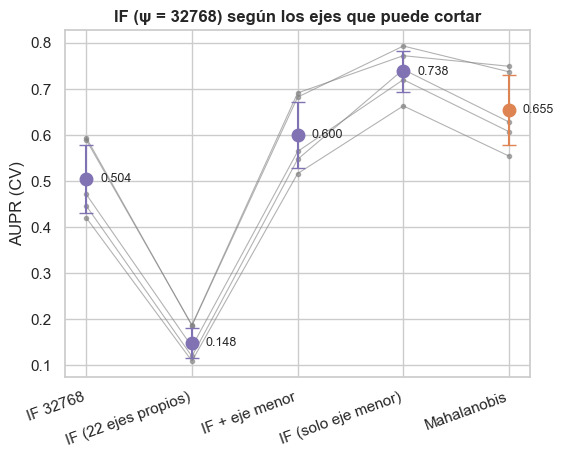

In [54]:
plot_folds([nom_if(PSI_FINAL), "IF (22 ejes propios)", "IF + eje menor", "IF (solo eje menor)", "Mahalanobis"],
           title=f"IF (ψ = {PSI_FINAL}) según los ejes que puede cortar");

Rotar los datos a los ejes propios hunde a IF: la rotación reparte las colas pesadas de los normales entre los 22 ejes nuevos, y la señal del fraude queda en uno solo. Pero si IF puede cortar **directamente por el eje menor**, una sola variable le basta para superar a Mahalanobis en los 5 folds. Añadido a las 22 variables ayuda menos, porque cada árbol lo elige solo en 1 de cada 23 cortes. La información está en la combinación, no en ninguna variable aislada.

**One-Class SVM.** La versión exacta con kernel RBF, `gamma="scale"` ($1/(d \cdot \mathrm{Var}\,X) = 1/22$ tras estandarizar) y `nu=0.01` (cota del % de normales de train que quedan fuera de la frontera). Un prototipo en 2 folds dio lo mismo o menos con `nu=0.005` o un `gamma` tres veces menor, y con `nu=0.03` o un `gamma` tres veces mayor tardó más de 10 minutos por fold (muchos más vectores soporte). El RBF depende de la escala: probamos standard y robust.

In [55]:
from sklearn.svm import OneClassSVM

for sc in ["standard", "robust"]:
    evaluar(f"OCSVM rbf ({sc})", make_pipe(OneClassSVM(kernel="rbf", gamma="scale", nu=0.01, cache_size=1000), sc), "una clase")

OCSVM rbf (standard): CV AUPR = 0.509 ± 0.072  (20 s)


OCSVM rbf (robust): CV AUPR = 0.426 ± 0.076  (15 s)


La alternativa escalable de la teoría: aproximar el kernel con 300 componentes de `Nystroem` y resolver la OCSVM lineal con `SGDOneClassSVM` (coste lineal en n). Con 1.000 componentes, el prototipo tardaba más de 2 minutos por fold sin mejorar.

In [56]:
from sklearn.kernel_approximation import Nystroem
from sklearn.linear_model import SGDOneClassSVM

evaluar("OCSVM Nystroem 300 (standard)", make_pipeline(StandardScaler(), Nystroem(gamma=1 / len(FEATURES), n_components=300, random_state=SEED),
                                                        SGDOneClassSVM(nu=0.01, random_state=SEED)), "una clase");

OCSVM Nystroem 300 (standard): CV AUPR = 0.392 ± 0.068  (3 s)


Los elegidos de cada familia, frente a la densidad:

In [57]:
AISL = [nom_if(PSI_FINAL), "IF (solo eje menor)", "OCSVM rbf (standard)", "OCSVM rbf (robust)", "OCSVM Nystroem 300 (standard)", "Mahalanobis", "GMM 5 full (robust)"]
AISL = [n for n in AISL if n in RES]
tabla_cv(AISL)[["familia", "media", "std", "segundos"] + [f"fold{k}" for k in range(5)]]

,familia,media,std,segundos,fold0,fold1,fold2,fold3,fold4
IF (solo eje menor),aislamiento,0.738,0.045,4.213,0.772,0.742,0.663,0.720,0.793
GMM 5 full (robust),densidad,0.734,0.075,18.691,0.835,0.616,0.700,0.737,0.783
Mahalanobis,densidad,0.655,0.076,3.534,0.749,0.628,0.554,0.607,0.737
OCSVM rbf (standard),una clase,0.509,0.072,20.044,0.626,0.512,0.431,0.438,0.537
IF 32768,aislamiento,0.504,0.073,5.633,0.589,0.446,0.420,0.471,0.594
OCSVM rbf (robust),una clase,0.426,0.076,15.376,0.544,0.398,0.357,0.349,0.485
OCSVM Nystroem 300 (standard),una clase,0.392,0.068,3.472,0.481,0.335,0.324,0.354,0.467


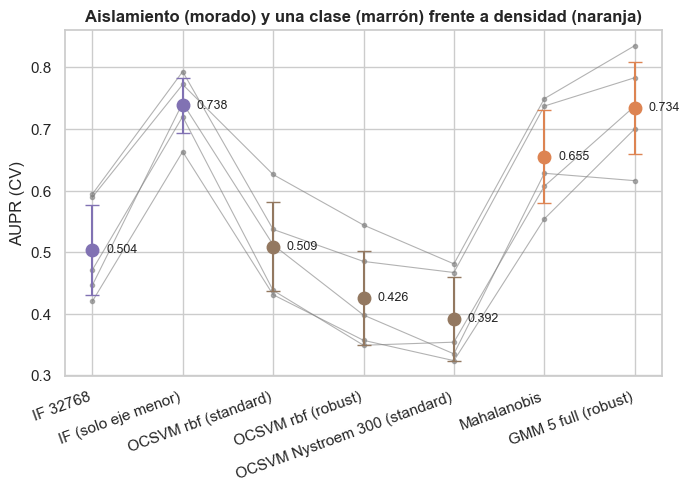

In [58]:
plot_folds(AISL, title="Aislamiento (morado) y una clase (marrón) frente a densidad (naranja)");

Los estimadores elegidos quedan sin ajustar para §10: IF puro con ψ = 32.768 y la OCSVM exacta con standard.

In [59]:
IF_FINAL = make_pipe(iforest(PSI_FINAL), None)
OCSVM_FINAL = make_pipe(OneClassSVM(kernel="rbf", gamma="scale", nu=0.01, cache_size=1000), "standard")

> **Conclusión:** Isolation Forest mejora con la submuestra, de **0,276** (ψ = 256, el valor por defecto) a **0,504 ± 0,073** (ψ = 32.768), pero queda lejos de Mahalanobis (0,655). La OCSVM exacta (RBF, `nu` = 0,01, ~14 s por CV) da **0,509 ± 0,072**, empatada con IF (gana en 3 de 5 folds); con robust cae a **0,426** (pierde en los 5, al revés que el GMM de §4) y con Nystroem a **0,392**. Ninguno de los dos ve la dirección de §3: IF corta variable a variable, y el RBF es una función de la euclídea. La prueba: rotado a los 22 ejes propios, IF cae a **0,148**, pero con **solo el eje menor** sube a **0,738 ± 0,045**, gana a Mahalanobis en los 5 folds y empata con el GMM 5 full (robust) (0,734). → **Impacto:** con las 22 variables, ni aislar ni envolver llega a la densidad. `IF_FINAL` (IF 32768) y `OCSVM_FINAL` (OCSVM rbf (standard)) quedan como referencia para §10. El eje menor es una **variable candidata** para §9 y el 04: un solo número con el que IF separa como el GMM completo.

## 7. ¿Se puede reconstruir lo normal?

**Qué miramos y por qué.** "Mayor error de predicción, más anómalo" (slide p34): se comprime lo normal en pocas dimensiones y se mide lo que se pierde al reconstruir cada fila. Probamos la versión lineal (**PCA**) y la no lineal (**autoencoder**), la que recomienda el profesor: "yo lo que miraría si fuera vosotros es el de autoencoder" [04:20:53]. Por §3 sabemos que los fraudes salen por la dirección en la que los normales casi no varían: un modelo que conserva las direcciones grandes y descarta las pequeñas debería dejarlos en el error.

**PCA.** Se ajusta con los normales del fold y reconstruye cada fila con sus $k$ primeras componentes. El score es el error cuadrático $\|x-\hat x\|^2$, que es la suma de cuadrados de las componentes **descartadas** (no `PCA.score_samples`, que es la log-verosimilitud del PCA probabilístico).

In [60]:
from sklearn.decomposition import PCA

class PCARecon(OutlierMixin, BaseEstimator):
    """Reconstrucción con las k primeras componentes de los normales: score_samples = −‖x − x̂‖² (mayor = más normal)."""
    def __init__(self, k=10):
        self.k = k
    def fit(self, X, y=None):
        self.pca_ = PCA(self.k, random_state=SEED).fit(X)
        return self
    def score_samples(self, X):
        return -((X - self.pca_.inverse_transform(self.pca_.transform(X))) ** 2).sum(axis=1)

Barrido de $k$ con los dos escaladores. Los extremos ya los conocemos: con $k = 0$ el error es la distancia euclídea al centro (§3, 0,316), y con $k = 22$ la reconstrucción es perfecta y el error vale 0 para todos. Con $k = 21$ solo se descarta la última componente, el eje menor de §3.

In [61]:
KS_PCA = [2, 4, 8, 12, 16, 18, 20, 21]
for sc in ["standard", "robust"]:
    for k in KS_PCA:
        evaluar(f"PCA {k} ({sc})", make_pipe(PCARecon(k), sc), "reconstrucción")

PCA 2 (standard): CV AUPR = 0.326 ± 0.060  (0 s)


PCA 4 (standard): CV AUPR = 0.339 ± 0.063  (0 s)


PCA 8 (standard): CV AUPR = 0.390 ± 0.050  (0 s)


PCA 12 (standard): CV AUPR = 0.430 ± 0.063  (0 s)


PCA 16 (standard): CV AUPR = 0.490 ± 0.056  (0 s)


...

PCA 12 (robust): CV AUPR = 0.644 ± 0.072  (0 s)


PCA 16 (robust): CV AUPR = 0.721 ± 0.068  (1 s)


PCA 18 (robust): CV AUPR = 0.741 ± 0.067  (0 s)


PCA 20 (robust): CV AUPR = 0.736 ± 0.068  (0 s)


PCA 21 (robust): CV AUPR = 0.743 ± 0.062  (1 s)


**Autoencoder.** La receta de la teoría: red densa 22 → 16 → código → 16 → 22 con ReLU y código lineal, MSE, Adam (1e-3), lotes de 256. Se entrena solo con los normales del fold (`fit()`), escalados con robust (§4), y con *early stopping* sobre un 10 % de esos normales. El score es el MSE de cada fila. Para caber en el presupuesto de tiempo se entrena con una **submuestra de 40.000 normales** por fold (de unos 95.000) y hasta 60 épocas.

In [62]:
import copy
import torch
from torch import nn

class Autoencoder(OutlierMixin, BaseEstimator):
    """AE denso d → 16 → code → 16 → d: score_samples = −MSE de reconstrucción por fila (mayor = más normal)."""
    def __init__(self, code=8, epochs=60, lr=1e-3, batch=256, patience=5, n_max=40_000, random_state=SEED):
        self.code, self.epochs, self.lr, self.batch = code, epochs, lr, batch
        self.patience, self.n_max, self.random_state = patience, n_max, random_state

    def fit(self, X, y=None):
        torch.manual_seed(self.random_state); torch.set_num_threads(2)       # determinista y sin saturar los núcleos
        X = np.asarray(X, np.float32)[np.random.default_rng(self.random_state).permutation(len(X))[:self.n_max]]
        nv = len(X) // 10
        Xv, Xe = torch.from_numpy(X[:nv]), torch.from_numpy(X[nv:])         # 10 % de normales para early stopping
        d = X.shape[1]
        self.net_ = nn.Sequential(nn.Linear(d, 16), nn.ReLU(), nn.Linear(16, self.code),
                                  nn.Linear(self.code, 16), nn.ReLU(), nn.Linear(16, d))
        opt = torch.optim.Adam(self.net_.parameters(), lr=self.lr)
        mejor, paciencia = np.inf, 0
        for ep in range(self.epochs):
            for b in torch.randperm(len(Xe)).split(self.batch):
                loss = ((self.net_(Xe[b]) - Xe[b]) ** 2).mean()
                opt.zero_grad(); loss.backward(); opt.step()
            with torch.no_grad():
                val = ((self.net_(Xv) - Xv) ** 2).mean().item()
            if val < mejor:
                mejor, paciencia, pesos = val, 0, copy.deepcopy(self.net_.state_dict())
            elif (paciencia := paciencia + 1) >= self.patience:
                break
        self.net_.load_state_dict(pesos)
        self.epocas_ = ep + 1
        return self

    def reconstruir(self, X):
        with torch.no_grad():
            return self.net_(torch.from_numpy(np.asarray(X, np.float32))).numpy().astype(float)

    def score_samples(self, X):
        return -((np.asarray(X, float) - self.reconstruir(X)) ** 2).mean(axis=1)

Barrido del cuello de botella: códigos de 4, 8 y 12 dimensiones, con la semilla común (una sola semilla por código, por el presupuesto de tiempo).

In [63]:
CODES = [4, 8, 12]
warnings.filterwarnings("ignore", message="A worker stopped")      # aviso inofensivo de joblib al reciclar procesos
for c in CODES:
    evaluar(f"AE {c} (robust)", make_pipe(Autoencoder(c), "robust"), "reconstrucción")

AE 4 (robust): CV AUPR = 0.674 ± 0.076  (36 s)


AE 8 (robust): CV AUPR = 0.678 ± 0.096  (17 s)


AE 12 (robust): CV AUPR = 0.707 ± 0.062  (16 s)


Las dos familias en la misma figura: AUPR frente a la dimensión que se conserva ($k$ componentes en PCA, tamaño del código en el AE). Si el AE no supera a PCA con la misma dimensión, la no linealidad no aporta.

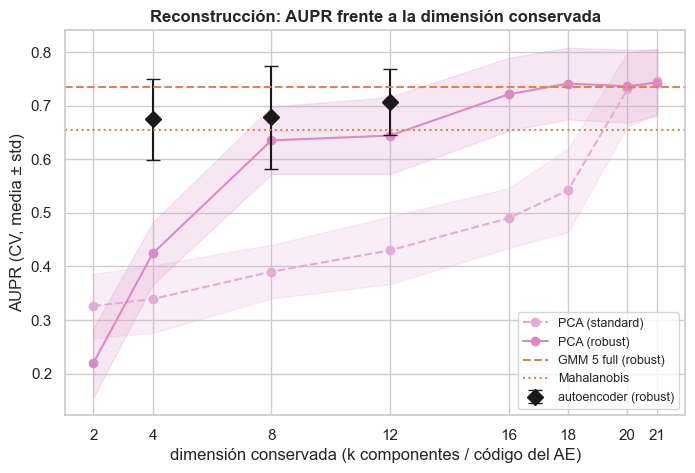

In [64]:
TONO = dict(zip(["standard", "robust"], sns.light_palette(FAM["reconstrucción"], n_colors=4)[2:]))
fig, ax = plt.subplots(figsize=(8, 5))
for sc in TONO:
    plot_curva(KS_PCA, [f"PCA {k} ({sc})" for k in KS_PCA], "dimensión conservada (k componentes / código del AE)",
               "Reconstrucción: AUPR frente a la dimensión conservada", label=f"PCA ({sc})", ax=ax)
    ax.get_lines()[-1].set(color=TONO[sc], ls="--" if sc == "standard" else "-"); ax.collections[-1].set_color(TONO[sc])
t_ae = tabla_cv([f"AE {c} (robust)" for c in CODES]).loc[[f"AE {c} (robust)" for c in CODES]]
ax.errorbar(CODES, t_ae["media"], yerr=t_ae["std"], fmt="D", ms=8, capsize=5, c="k", label="autoencoder (robust)")
for n, ls in [("GMM 5 full (robust)", "--"), ("Mahalanobis", ":")]:
    if n in RES: ax.axhline(RES[n]["media"], c=FAM["densidad"], ls=ls, lw=1.5, label=n)
ax.set_xticks(KS_PCA)
ax.legend(loc="lower right", fontsize=9);

Con standard, PCA solo despega al descartar las últimas componentes (**0,730** con k = 20, **0,745** con k = 21). Con robust sube antes (**0,741** con k = 18) y se estanca. El AE queda por encima de PCA con su misma dimensión, pero por debajo de PCA 21.

¿Reconstruye mejor el AE más grande? La pérdida en los normales de validación (MSE medio de los scores *out-of-fold*) frente a la AUPR, al lado de PCA con la misma dimensión y escalador:

In [65]:
y_np = y_train.to_numpy()
pd.DataFrame({c: {"AUPR AE": RES[f"AE {c} (robust)"]["media"], "MSE normales val (AE)": OOF[f"AE {c} (robust)"][y_np == 0].mean(),
                  "AUPR PCA": RES[f"PCA {c} (robust)"]["media"], "MSE normales val (PCA)": OOF[f"PCA {c} (robust)"][y_np == 0].mean() / len(FEATURES)}
              for c in CODES}).T.rename_axis("dimensión").round(3)

,AUPR AE,MSE normales val (AE),AUPR PCA,MSE normales val (PCA)
dimensión,,,,
4,0.674,0.398,0.424,0.627
8,0.678,0.252,0.635,0.416
12,0.707,0.168,0.644,0.254


Con la misma dimensión, el AE reconstruye mejor a los normales que PCA y también detecta mejor. Pero ningún AE llega a PCA 21, que lo reconstruye casi todo y pierde una sola dirección: lo que importa no es cuánto se pierde, sino **qué** se pierde.

¿Qué variables no sabe reconstruir el AE? Error cuadrático medio por variable (en la escala robust) de fraudes y normales del fold 0 de validación, con el AE de código 12 ajustado en los normales del fold 0 de train. Es solo un diagnóstico (no se elige nada con él), y la explicación que retoma §13.

In [66]:
it, iv = cv_splits[0]
ae0 = fit(make_pipe(Autoencoder(12), "robust"), X_train.to_numpy(float)[it], y_np[it])
Z = ae0[:-1].transform(X_train.to_numpy(float)[iv])
R = pd.DataFrame((Z - ae0[-1].reconstruir(Z)) ** 2, columns=FEATURES)
err = R.groupby(y_np[iv]).mean().T.set_axis(["normal", "fraude"], axis=1)
err = err.assign(ratio=err.fraude / err.normal).sort_values("ratio")

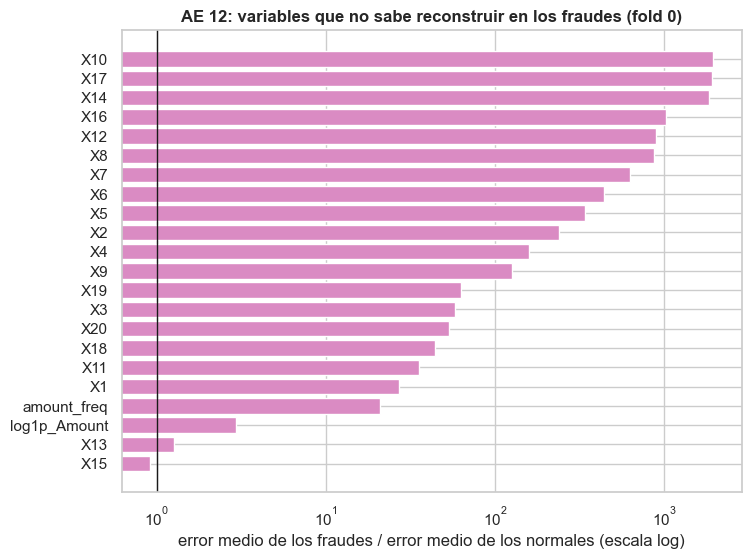

In [67]:
fig, ax = plt.subplots(figsize=(8, 6))
ax.barh(err.index, err.ratio, color=FAM["reconstrucción"])
ax.axvline(1, c="k", lw=1)
ax.set(xscale="log", xlabel="error medio de los fraudes / error medio de los normales (escala log)",
       title="AE 12: variables que no sabe reconstruir en los fraudes (fold 0)");

Los mejores de cada versión frente a las referencias de densidad, fold a fold:

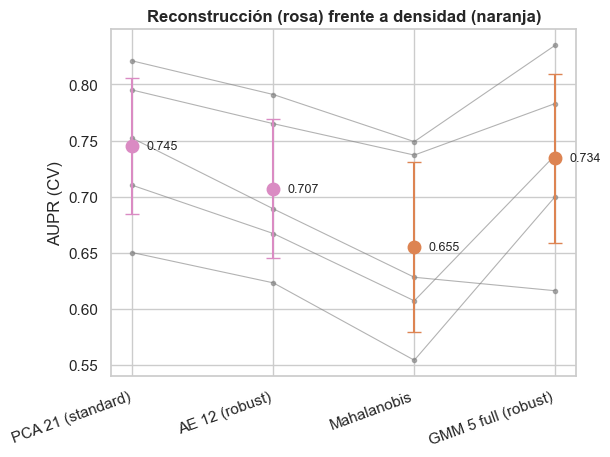

In [68]:
REC = [n for n in ["PCA 21 (standard)", "AE 12 (robust)", "Mahalanobis", "GMM 5 full (robust)"] if n in RES]
plot_folds(REC, title="Reconstrucción (rosa) frente a densidad (naranja)");

Comparación por pares: en cuántos de los 5 folds gana cada detector de reconstrucción a los demás.

In [69]:
por_fold = lambda n: np.array([RES[n][f"fold{k}"] for k in range(5)])
pd.DataFrame({b: [int((por_fold(a) > por_fold(b)).sum()) if a != b else pd.NA for a in REC[:2]] for b in REC[1:]},
             index=pd.Index(REC[:2], name="folds ganados (de 5) a →"), dtype="Int64")

,AE 12 (robust),Mahalanobis,GMM 5 full (robust)
folds ganados (de 5) a →,,,
PCA 21 (standard),5,5,2
AE 12 (robust),<NA>,5,1


Los estimadores elegidos quedan sin ajustar para §9 y la Parte II.

In [70]:
PCA_FINAL = make_pipe(PCARecon(21), "standard")
AE_FINAL = make_pipe(Autoencoder(12), "robust")
tabla_cv(["PCA 21 (standard)", "AE 12 (robust)"])[["media", "std", "segundos"] + [f"fold{k}" for k in range(5)]]

,media,std,segundos,fold0,fold1,fold2,fold3,fold4
PCA 21 (standard),0.745,0.061,0.378,0.821,0.752,0.650,0.710,0.795
AE 12 (robust),0.707,0.062,16.204,0.791,0.689,0.623,0.667,0.765


> **Conclusión:** La reconstrucción detecta bien solo cuando lo que descarta es el eje menor de §3. Con PCA y standard, la AUPR sube de **0,326** (k = 2) a **0,745 ± 0,061** con k = 21: el error es entonces el cuadrado de esa última componente, el término que más pesa en Mahalanobis, sin el ruido de las colas de las otras 21 direcciones. Por eso PCA 21 gana a Mahalanobis (**0,655**) en los **5** folds y empata con el GMM 5 full (robust) (0,734; le gana en 2 de 5). El autoencoder reconstruye y detecta mejor que PCA con la misma dimensión (**0,707** frente a **0,644** con código 12), pero pierde con PCA 21 en los **5** folds. Lo que no sabe reconstruir en los fraudes son X10, X17, X14, X16 y X12, las variables del eje menor. → **Impacto:** a la Parte II pasa **PCA 21 (standard)** (`PCA_FINAL`): tan bueno como el GMM, casi gratis y explicable con una sola dirección. **AE 12 (robust)** (`AE_FINAL`) pasa solo como candidato por diversidad, a confirmar en §11: como detector no compensa su coste. Su uso natural es el del profesor, "coges la parte latente y luego utilizas las cosas sencillas" [04:21:15], en el híbrido del 04.

## 8. ¿Basta con mirar variable a variable?

**Qué miramos y por qué.** Los detectores más baratos puntúan cada variable por separado y suman: **HBOS** (histograma por variable) y **ECOD** (colas empíricas por variable). En ADBench están entre los mejores no supervisados (medianas de AUCROC ~71 y ~73), y allí "none of the unsupervised methods is statistically better than the others". Su supuesto es la **independencia** entre variables, y el fraude del 01 es una anomalía dependiente (correlación media **0,415** en fraude frente a **0,036** en normales, §7 del 01). Aquí medimos cuánto cuesta ese supuesto con las 22 variables, y dónde se pierde la señal.

PyOD no está instalado y el notebook debe ser autocontenido, así que los dos detectores se implementan con numpy en unas líneas. Van **sin escalar**: ECOD no cambia con ninguna transformación monótona por variable, y HBOS (bins de anchura fija) con ninguna lineal.

**HBOS** suma, variable a variable, el $-\log$ de la densidad del histograma de los normales. Un valor fuera del rango de train recibe la densidad del bin más vacío.

In [71]:
class HBOS(OutlierMixin, BaseEstimator):
    """Histogram-Based Outlier Score: score_samples = Σ_j log densidad del histograma de la variable j (mayor = más normal)."""
    def __init__(self, n_bins=10):
        self.n_bins = n_bins
    def fit(self, X, y=None):
        self.bordes_, self.logd_ = [], []
        for x in X.T:
            n, b = np.histogram(x, bins=self.n_bins)
            self.bordes_.append(b)
            self.logd_.append(np.log((n + 1) / (len(x) + self.n_bins) / np.diff(b)))   # +1: ningún bin con densidad 0
        return self
    def score_samples(self, X):
        ld = np.empty(X.shape)
        for j, (b, l) in enumerate(zip(self.bordes_, self.logd_)):
            k = np.clip(np.searchsorted(b, X[:, j], side="right") - 1, 0, len(l) - 1)
            ld[:, j] = np.where((X[:, j] < b[0]) | (X[:, j] > b[-1]), l.min(), l[k])     # fuera de rango: el bin más vacío
        return ld.sum(1)

**ECOD** (Li et al., 2022) no tiene hiperparámetros: para cada variable, la probabilidad de cola empírica de los normales a la izquierda, $P(X_j \le x_j)$, y a la derecha, $P(X_j \ge x_j)$. Suma los $-\log$ de todas las variables y se queda con el máximo de tres versiones: solo colas izquierdas, solo derechas, o la cola que indica la asimetría de cada variable.

In [72]:
class ECOD(OutlierMixin, BaseEstimator):
    """Empirical-CDF Outlier Detection: score_samples = −max(Σ cola izq., Σ cola der., Σ cola por asimetría) (mayor = más normal)."""
    def fit(self, X, y=None):
        self.orden_, self.asim_ = np.sort(X, axis=0), stats.skew(X, axis=0)
        return self
    def colas(self, X):
        """−log P(X_j ≤ x_j) y −log P(X_j ≥ x_j) con la ECDF de los normales (+1: ningún log 0 fuera de rango)."""
        n = len(self.orden_)
        izq = np.column_stack([np.searchsorted(o, x, side="right") for o, x in zip(self.orden_.T, X.T)])
        der = n - np.column_stack([np.searchsorted(o, x, side="left") for o, x in zip(self.orden_.T, X.T)])
        return -np.log((izq + 1) / (n + 1)), -np.log((der + 1) / (n + 1))
    def score_samples(self, X):
        izq, der = self.colas(X)
        auto = np.where(self.asim_ < 0, izq, der)                # cola izquierda si la variable es asimétrica a la izquierda
        return -np.maximum.reduce([izq.sum(1), der.sum(1), auto.sum(1)])

ECOD y HBOS con 5 a 100 bins, sobre `FEATURES`:

In [73]:
evaluar("ECOD", ECOD(), "marginal")
for nb in [5, 10, 20, 50, 100]:
    evaluar(f"HBOS {nb}", HBOS(nb), "marginal")
tabla_cv(["ECOD"] + [f"HBOS {nb}" for nb in [5, 10, 20, 50, 100]])[["media", "std", "segundos"] + [f"fold{k}" for k in range(5)]]

ECOD: CV AUPR = 0.583 ± 0.076  (1 s)


HBOS 5: CV AUPR = 0.450 ± 0.072  (0 s)


HBOS 10: CV AUPR = 0.475 ± 0.069  (0 s)


HBOS 20: CV AUPR = 0.460 ± 0.067  (0 s)


HBOS 50: CV AUPR = 0.454 ± 0.061  (0 s)


HBOS 100: CV AUPR = 0.436 ± 0.069  (0 s)


,media,std,segundos,fold0,fold1,fold2,fold3,fold4
ECOD,0.583,0.076,1.175,0.677,0.562,0.466,0.555,0.655
HBOS 10,0.475,0.069,0.363,0.531,0.415,0.408,0.440,0.582
HBOS 20,0.460,0.067,0.388,0.507,0.407,0.385,0.435,0.567
HBOS 50,0.454,0.061,0.386,0.525,0.409,0.381,0.427,0.528
HBOS 5,0.450,0.072,0.399,0.476,0.389,0.380,0.426,0.577
HBOS 100,0.436,0.069,0.377,0.517,0.368,0.365,0.412,0.517


ECOD gana a todos los HBOS en los 5 folds. En HBOS, el mejor es 10 bins (gana a 20 en los 5 folds): con menos, el histograma no separa la cola del centro; con más, la cola se trocea en celdas casi vacías y su densidad es ruido. Nos quedamos con 10 (el valor por defecto de PyOD).

**¿Dónde se pierde la señal?** ECOD es una suma de rarezas por variable, así que se puede abrir. En el fold 0, la AUPR de la rareza de **cada variable por separado** ($-\log$ de su cola más pequeña, izquierda o derecha) y la del **eje menor** de §3 (`EjesPropios`, §6), calculada igual. Es solo un diagnóstico: elegir variables así, mirando la validación, sería fuga (la selección honesta es la de §9).

In [74]:
it, iv = cv_splits[0]
X0f, Xv, yv = X_train.iloc[it][y_train.iloc[it] == 0].to_numpy(float), X_train.iloc[iv].to_numpy(float), y_train.iloc[iv].to_numpy()
ec, eje = ECOD().fit(X0f), EjesPropios(1).fit(X0f)
ec1 = ECOD().fit(eje.transform(X0f))
rareza = lambda e, X: np.maximum(*e.colas(X))                              # −log de la cola más pequeña, por variable
r_var = pd.DataFrame(np.c_[rareza(ec, Xv), rareza(ec1, eje.transform(Xv))], columns=FEATURES + ["eje menor (§3)"])
ap_var = r_var.apply(lambda c: average_precision_score(yv, c)).sort_values(ascending=False)
ap_ecod0 = average_precision_score(yv, -ec.score_samples(Xv))              # ECOD con las 22 (fold 0)

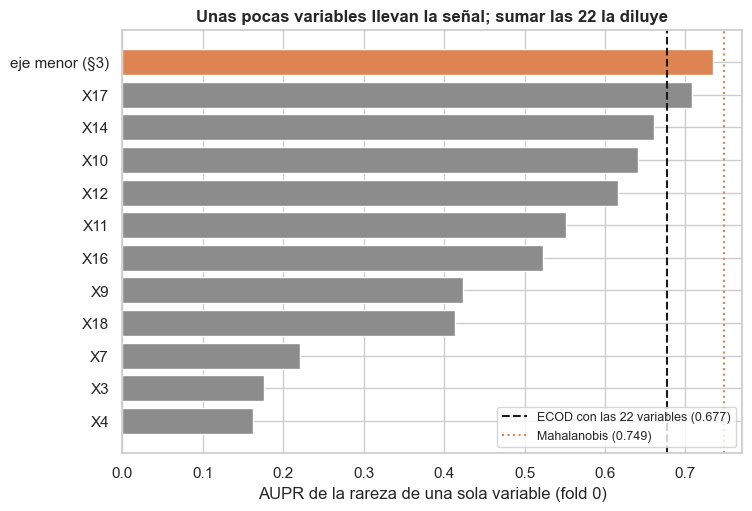

In [75]:
top = ap_var.index[:12][::-1]
fig, ax = plt.subplots(figsize=(8, 5.5))
ax.barh(top, ap_var[top], color=[FAM["densidad"] if n.startswith("eje") else FAM["marginal"] for n in top])
ax.axvline(ap_ecod0, c="k", ls="--", lw=1.5, label=f"ECOD con las 22 variables ({ap_ecod0:.3f})")
ax.axvline(RES["Mahalanobis"]["fold0"], c=FAM["densidad"], ls=":", lw=1.5, label=f"Mahalanobis ({RES['Mahalanobis']['fold0']:.3f})")
ax.set(xlabel="AUPR de la rareza de una sola variable (fold 0)", title="Unas pocas variables llevan la señal; sumar las 22 la diluye")
ax.legend(loc="lower right", fontsize=9);

No falta señal marginal: X17 **sola** supera a ECOD con las 22 variables, y X14, X10, X12, X11 y X16 quedan cerca; en cambio, 10 de las 22 variables no llegan a 0,1. ¿Por qué no se suman bien? Porque esas seis no son independientes, y su dependencia cambia entre clases. Correlación media en valor absoluto entre ellas:

In [76]:
SEIS = ["X17", "X14", "X10", "X12", "X11", "X16"]
corr_abs = lambda k: (X_train[y_train == k][SEIS].corr().abs().to_numpy()[np.triu_indices(6, 1)]).mean()
pd.Series({LBL[k]: corr_abs(k) for k in (0, 1)}, name="|correlación| media entre las 6").round(3).to_frame().T

,normal,fraude
|correlación| media entre las 6,0.103,0.774


En los normales, las seis apenas se relacionan (correlaciones entre −0,17 y 0,09, 10 de las 15 negativas: se compensan), y por eso su combinación, el eje menor, casi no varía. En los fraudes se mueven juntas. ECOD no ve esta diferencia: trata la cola de X14 de un normal igual que la de un fraude, aunque en el normal la compensen las otras cinco, y añade el ruido de las otras 16 variables. Si el eje menor resume la anomalía, ECOD con esa única variable debería superar al ECOD de las 22:

In [77]:
evaluar("ECOD (solo eje menor)", make_pipeline(EjesPropios(1), ECOD()), "marginal");

ECOD (solo eje menor): CV AUPR = 0.661 ± 0.061  (0 s)


Los marginales frente a la densidad:

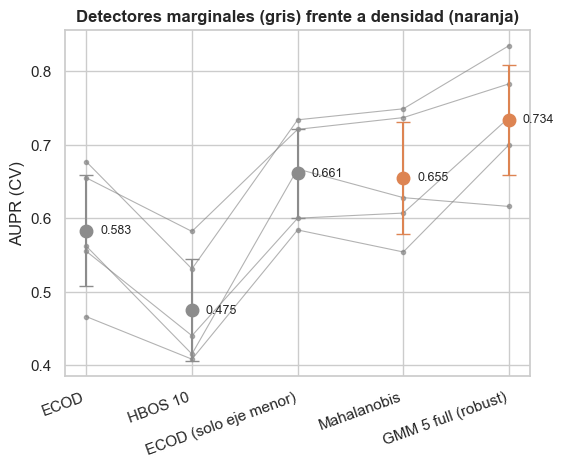

In [78]:
MARG = [n for n in ["ECOD", "HBOS 10", "ECOD (solo eje menor)", "Mahalanobis", "GMM 5 full (robust)"] if n in RES]
plot_folds(MARG, title="Detectores marginales (gris) frente a densidad (naranja)");

Los estimadores elegidos quedan sin ajustar para §10 (con las 22 variables, sin el eje menor). Resultados fold a fold:

In [79]:
ECOD_FINAL, HBOS_FINAL = ECOD(), HBOS(10)
tabla_cv(MARG)[["media", "std", "segundos"] + [f"fold{k}" for k in range(5)]]

,media,std,segundos,fold0,fold1,fold2,fold3,fold4
GMM 5 full (robust),0.734,0.075,18.691,0.835,0.616,0.700,0.737,0.783
ECOD (solo eje menor),0.661,0.061,0.435,0.734,0.667,0.584,0.600,0.721
Mahalanobis,0.655,0.076,3.534,0.749,0.628,0.554,0.607,0.737
ECOD,0.583,0.076,1.175,0.677,0.562,0.466,0.555,0.655
HBOS 10,0.475,0.069,0.363,0.531,0.415,0.408,0.440,0.582


> **Conclusión:** Con las 22 variables, ECOD da **0,583 ± 0,076** y HBOS (10 bins) **0,475 ± 0,069**, en ~1 s cada uno; Mahalanobis (0,655) gana a ECOD en los 5 folds. No falta señal marginal: en el fold 0, X17 sola da **0,708**, más que ECOD con las 22 (**0,677**). Lo que falla es la suma: 10 de las 22 variables no llegan a 0,1 y solo aportan colas de normales, y las seis con señal se mueven juntas en los fraudes (|correlación| media **0,774**, frente a **0,103** en normales), algo que una suma por variable no distingue. Con solo el eje menor, que resume esa combinación, ECOD sube a **0,661 ± 0,061** y gana en los 5 folds. → **Impacto:** con las 22 variables, mirar variable a variable cuesta ~0,07 de AUPR frente a una sola gaussiana, en línea con ADBench (ningún no supervisado gana siempre; depende del tipo de anomalía). El fallo es más de representación que de detector: §9 comprueba si quitar las variables sin señal recupera a ECOD y HBOS. `ECOD_FINAL` (ECOD) y `HBOS_FINAL` (HBOS 10) quedan para §10 como detectores baratos.

## 9. ¿Todas las variables o las mejores?

**Qué miramos y por qué.** Con muchas variables irrelevantes, "los métodos de distancia fallan mucho" [03:48:07], y también los de probabilidad. El EDA (§5 del 01) concentró la señal en X17, X14, X12 y X10 (AUPR univariante 0,60–0,66), y la Parte I la ha situado en una dirección conjunta: el eje menor de los normales (§3, §6–§8). Probamos dos formas de quedarse con "las mejores": las **top-k por AUPR univariante**, que usan etiquetas, y los **m ejes de menor varianza** de los normales, que no las usan. Se aplican a los detectores baratos de cada familia (el AE y la OCSVM quedan fuera por coste, y PCA 21 ya es un detector sobre el eje menor).

**(a) Selección supervisada.** El ranking del 01 se calculó con las etiquetas de todo train, folds de validación incluidos. Usarlo tal cual en la CV sería una fuga. La comprobación honesta: recalcular la AUPR univariante orientada, $\max(\mathrm{AUPR}(x), \mathrm{AUPR}(-x))$ como `uni_scores` del 01, **solo con el fold de train** de cada partición. Rango de las 10 primeras variables en cada fold:

In [80]:
# AUPR univariante orientada con las etiquetas del fold de train (la de validación no se mira)
aupr_uni = lambda X, y: pd.Series({c: max(average_precision_score(y, X[c]), average_precision_score(y, -X[c])) for c in X})
uni = pd.DataFrame({f"fold {k}": aupr_uni(X_train.iloc[it], y_train.iloc[it]) for k, (it, _) in enumerate(cv_splits)})
uni["todo train (01)"] = aupr_uni(X_train, y_train)
rangos = uni.rank(ascending=False).astype(int).sort_values("todo train (01)")
TOP = rangos.index.tolist()                                  # orden del 01
rangos.head(10).T

,X17,X14,X12,X10,X11,X16,X9,X18,X3,X7
fold 0,1,2,3,4,5,6,7,8,9,11
fold 1,1,2,4,3,5,6,7,8,9,11
fold 2,1,2,3,4,5,6,8,7,9,10
fold 3,1,2,3,4,5,6,8,7,9,10
fold 4,2,1,3,4,5,6,7,8,9,11
todo train (01),1,2,3,4,5,6,7,8,9,10


El orden cambia un poco (X17 y X14, X12 y X10, X9 y X18 se intercambian), pero ¿cambia el **conjunto**? Para cada k, en cuántos folds las k mejores variables del fold de train son las mismas que las del 01:

In [81]:
mismo = lambda k, f: set(rangos.index[rangos[f"fold {f}"] <= k]) == set(TOP[:k])
pd.DataFrame({k: {"top-k del 01": ", ".join(TOP[:k]), "folds con el mismo conjunto": sum(mismo(k, f) for f in range(5))}
              for k in [4, 6, 8]}).T.rename_axis("k")

,top-k del 01,folds con el mismo conjunto
k,,
4,"X17, X14, X12, X10",5
6,"X17, X14, X12, X10, X11, X16",5
8,"X17, X14, X12, X10, X11, X16, X9, X18",5


Con k = 4, 6 y 8, la selección hecha dentro de cada fold elige **exactamente** las mismas variables que el 01. Evaluar el top-k fijo da, por tanto, el mismo resultado que seleccionar dentro del fold: aquí no hay fuga y no hace falta un bucle propio. `log1p_Amount` y `amount_freq` quedan en los puestos 19–20 (AUPR ≈ aleatorio: el importe no es monótono con el fraude, §6 del 01), pero en §2 ayudaron al GMM. Por eso se evalúan k = 4 y k = 6, **con y sin** las dos variables de importe (en un prototipo, k = 8 empataba o bajaba frente a k = 6 con todos los detectores). Cada detector es su `*_FINAL`, con el mismo escalador e hiperparámetros:

In [82]:
IMPORTE = ["log1p_Amount", "amount_freq"]
CONJ = {"todas": FEATURES} | {f"top {k}{i}": TOP[:k] + imp for k in [4, 6] for i, imp in [("", []), (" + importe", IMPORTE)]}
DET = {"Mahalanobis": ("Mahalanobis", make_pipe(Mahalanobis())), "GMM 5": ("GMM 5 full (robust)", GMM_FINAL),
       "LOF 20": ("LOF 20 (standard)", LOF_FINAL), "kNN 20": ("kNN 20 (standard)", KNN_FINAL), "IF 32768": ("IF 32768", IF_FINAL),
       "ECOD": ("ECOD", ECOD_FINAL), "HBOS 10": ("HBOS 10", HBOS_FINAL)}       # nombre corto → (nombre en RES con las 22, estimador)
nom_sel = lambda d, c: f"{d} · {c}"

In [83]:
# 4 conjuntos × 7 detectores: el detalle va a la matriz de abajo, no al log
import contextlib, io
with contextlib.redirect_stdout(io.StringIO()):
    for d, (ref, est) in DET.items():
        for c in list(CONJ)[1:]:
            evaluar(nom_sel(d, c), est, RES[ref]["familia"], feats=CONJ[c])

**(b) Selección no supervisada.** Las coordenadas en los **m ejes de menor varianza** de los normales (`EjesPropios(m)`, §6), calculados con los normales del fold de train dentro del pipeline. No miran ninguna etiqueta, así que no pueden tener fuga. Con m = 1 es el eje menor de §3: Mahalanobis sobre él es exactamente PCA 21 (§7), y para IF y ECOD repite las variantes "solo eje menor" de §6 y §8.

In [84]:
EJES = {"1 eje menor": 1, "2 ejes menores": 2, "4 ejes menores": 4, "8 ejes menores": 8}
with contextlib.redirect_stdout(io.StringIO()):
    for d, (ref, est) in DET.items():
        for c, m in EJES.items():
            evaluar(nom_sel(d, c), make_pipeline(EjesPropios(m), clone(est)), RES[ref]["familia"])

Todos los resultados en una matriz detector × conjunto de variables. Para cada detector elegimos un conjunto con una regla fija: el de mayor AUPR media, salvo que uno de ejes menores (sin etiquetas, sin fuga posible) quede a menos de 0,01; entonces se prefiere ese.

In [85]:
cols = list(CONJ) + list(EJES)
celda = lambda d, c, campo: RES[DET[d][0] if c == "todas" else nom_sel(d, c)][campo]
media_sel, std_sel = [pd.DataFrame({c: [celda(d, c, campo) for d in DET] for c in cols}, index=list(DET)) for campo in ("media", "std")]
def elegir(d):
    m = media_sel.loc[d].drop("todas")
    return m[list(EJES)].idxmax() if m[list(EJES)].max() >= m.max() - .01 else m.idxmax()
SEL = {d: elegir(d) for d in DET}

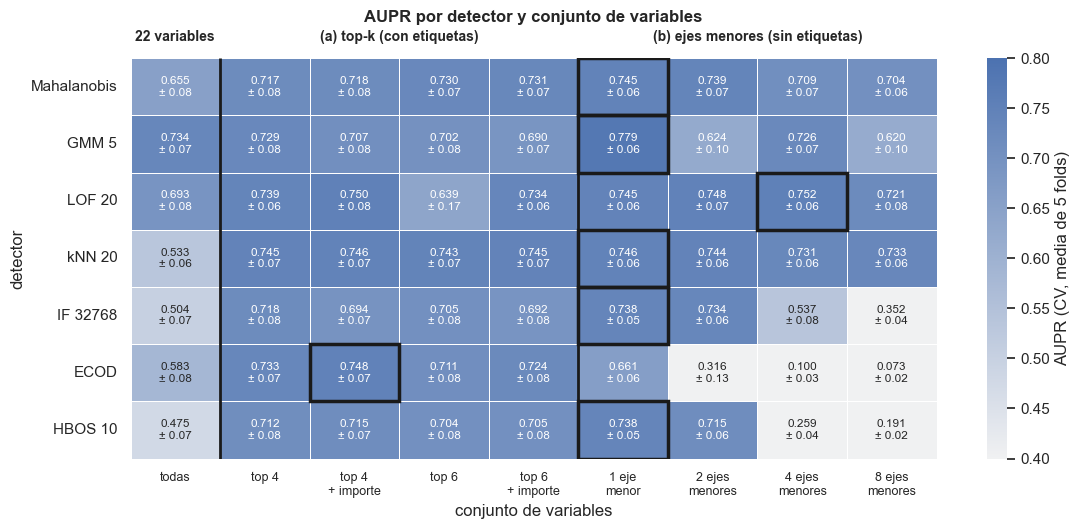

In [86]:
# recuadro = conjunto elegido para cada detector
fig, ax = plt.subplots(figsize=(13, 5.2))
anot = media_sel.apply(lambda c: c.map("{:.3f}".format)) + "\n± " + std_sel.apply(lambda c: c.map("{:.2f}".format))
sns.heatmap(media_sel, annot=anot, fmt="", cmap=sns.light_palette(FAM["distancia"], as_cmap=True), vmin=.4, vmax=.8, linewidths=.5,
            annot_kws={"fontsize": 8.5}, cbar_kws={"label": "AUPR (CV, media de 5 folds)"}, ax=ax)
for i, d in enumerate(DET):
    ax.add_patch(plt.Rectangle((cols.index(SEL[d]), i), 1, 1, fill=False, ec="k", lw=2.5))
ax.vlines([1, 1 + len(CONJ) - 1], 0, len(DET), colors="k", lw=2)
for x, txt in [(.5, "22 variables"), ((1 + len(CONJ)) / 2, "(a) top-k (con etiquetas)"), (len(CONJ) + len(EJES) / 2, "(b) ejes menores (sin etiquetas)")]:
    ax.text(x, -.25, txt, ha="center", va="bottom", fontsize=10, weight="bold")
ax.set_xticklabels([c.replace(" + ", "\n+ ").replace(" menor", "\nmenor") for c in cols], rotation=0, fontsize=9)
ax.set(xlabel="conjunto de variables", ylabel="detector")
ax.set_title("AUPR por detector y conjunto de variables", pad=26);

Quitar variables mejora a **todos** los detectores, y más a los que peor iban. kNN pasa de 0,533 a 0,745 solo con las top 4: con 18 variables menos, su euclídea deja de sumar el ruido de las colas, el fallo que anunciaba el profesor. ECOD llega a 0,733 con las mismas cuatro: lo que le hundía en §8 era sumar las variables sin señal, más que suponer independencia. Entre las top-k, k = 4 gana en media a k = 6 en 6 de los 7 detectores (todos menos Mahalanobis). El importe no tiene un efecto común: estabiliza a LOF (de 0,639 ± 0,167 a 0,734 con las top 6) y ayuda a ECOD, resta al GMM y a IF y casi no cambia el resto.

Con los ejes menores, Mahalanobis, kNN y LOF aguantan hasta 8 ejes (≥ 0,70); el GMM es irregular (0,624 con 2 ejes). Los que miran variable a variable se hunden a partir de 4 ejes (ECOD ya con 2): cada eje nuevo solo trae colas de los normales, como el IF de §6 con los 22 ejes.

Dos rarezas de la matriz las explica la forma de los normales en el eje menor: el GMM gana con un solo eje, y ECOD es el único que con él no llega a ~0,74. En el fold 0, con el eje orientado hacia el lado del fraude: asimetría y curtosis de los normales, y qué parte de los fraudes sale por ese lado y más allá del normal más extremo de train. Como en §8, mira las etiquetas de validación solo para diagnosticar, no para elegir.

In [87]:
it, iv = cv_splits[0]
Xn, yv = X_train.to_numpy(float)[it][y_train.to_numpy()[it] == 0], y_train.to_numpy()[iv]
eje0 = EjesPropios(1).fit(Xn)
z0, zf = eje0.transform(Xn).ravel(), eje0.transform(X_train.to_numpy(float)[iv][yv == 1]).ravel()
lado = np.sign(np.median(zf))                                  # el signo de un autovector es arbitrario: positivo = lado del fraude
z0, zf = lado * z0, lado * zf
pd.Series({"asimetría (normales)": stats.skew(z0), "curtosis (normales)": stats.kurtosis(z0), "% fraudes con z > 0": 100 * (zf > 0).mean(),
           "% fraudes más allá del normal más extremo": 100 * (zf > z0.max()).mean()}, name="eje menor, fold 0").round(1).to_frame().T

,asimetría (normales),curtosis (normales),% fraudes con z > 0,% fraudes más allá del normal más extremo
"eje menor, fold 0",86.3,8106.9,100.0,31.7


En el eje menor los normales están muy lejos de una gaussiana (asimetría **86** y curtosis **8.107**: una cola larga hacia el lado del fraude), y todos los fraudes salen por el mismo lado. Mahalanobis (= PCA 21) puntúa con $z^2$: simétrico, como si los normales fueran gaussianos. Un GMM de 5 componentes en esa única dimensión aprende la forma real, y da el mejor resultado de la matriz. ECOD, en cambio, se satura: el **31,7 %** de los fraudes cae más allá de todos los normales de train, y para la ECDF todos ellos son igual de raros (empatan en el máximo). Por eso, con el eje menor, ECOD se queda en 0,661, por debajo de los demás (~0,74), y su mejor conjunto es el top 4 + importe.

**Elección por detector.** El conjunto elegido frente a las 22 variables, y en cuántos folds gana (comparación por pares):

In [88]:
por_fold = lambda n: np.array([RES[n][f"fold{k}"] for k in range(5)])
t_sel = pd.DataFrame({d: {"conjunto elegido": c, "AUPR 22 variables": media_sel.loc[d, "todas"], "AUPR elegido": media_sel.loc[d, c],
                          "std elegido": std_sel.loc[d, c], "folds ganados (de 5)": int((por_fold(nom_sel(d, c)) > por_fold(DET[d][0])).sum())}
                      for d, c in SEL.items()}).T
t_sel.astype({c: float for c in t_sel.columns[1:4]}).round(3).sort_values("AUPR elegido", ascending=False)

,conjunto elegido,AUPR 22 variables,AUPR elegido,std elegido,folds ganados (de 5)
GMM 5,1 eje menor,0.734,0.779,0.060,4
LOF 20,4 ejes menores,0.693,0.752,0.063,5
ECOD,top 4 + importe,0.583,0.748,0.072,5
kNN 20,1 eje menor,0.533,0.746,0.061,5
Mahalanobis,1 eje menor,0.655,0.745,0.061,5
IF 32768,1 eje menor,0.504,0.738,0.045,5
HBOS 10,1 eje menor,0.475,0.738,0.055,5


Con su conjunto, todos los detectores ganan a su versión con las 22 variables en los 5 folds, salvo el GMM (4 de 5), que ya era el mejor: kNN pasa de **0,533** a **0,746**, ECOD de **0,583** a **0,748**, IF de **0,504** a **0,738**, HBOS de **0,475** a **0,738** y LOF de **0,693** a **0,752**.

El nuevo mejor es el GMM 5 sobre el eje menor. Como el GMM depende de la inicialización (§4), lo repetimos con las otras dos semillas:

In [89]:
for rs in SEMILLAS[1:]:
    evaluar(f"GMM 5 · 1 eje menor · s{rs}", make_pipeline(EjesPropios(1), make_pipe(GaussianMixture(5, random_state=rs), "robust")), "densidad")

GMM 5 · 1 eje menor · s43: CV AUPR = 0.784 ± 0.058  (1 s)


GMM 5 · 1 eje menor · s44: CV AUPR = 0.787 ± 0.057  (1 s)


Los conjuntos elegidos fold a fold, frente a los dos mejores detectores con las 22 variables (PCA 21, idéntico a Mahalanobis sobre el eje menor, y GMM 5 full):

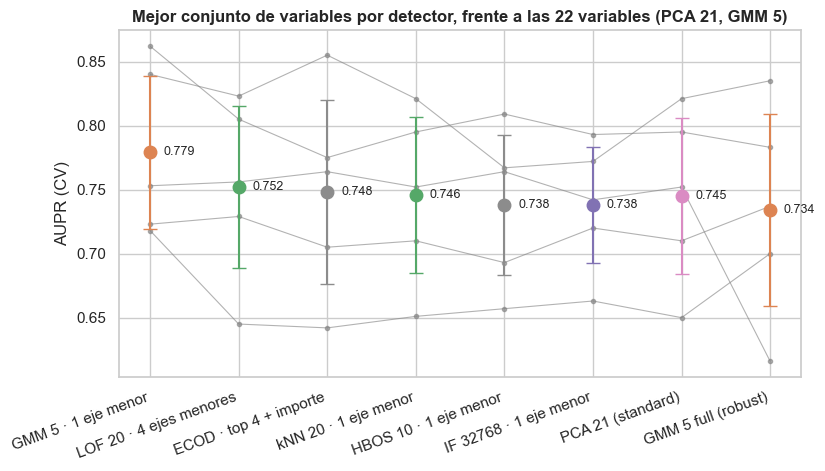

In [90]:
# Mahalanobis · 1 eje menor no se repite: es PCA 21
MEJORES = tabla_cv([nom_sel(d, SEL[d]) for d in DET if d != "Mahalanobis"]).index.tolist() + ["PCA 21 (standard)", "GMM 5 full (robust)"]
plot_folds(MEJORES, title="Mejor conjunto de variables por detector, frente a las 22 variables (PCA 21, GMM 5)");

In [91]:
# en cuántos folds gana el GMM sobre el eje menor a cada uno de los demás
g = nom_sel("GMM 5", SEL["GMM 5"])
pd.Series({n: int((por_fold(g) > por_fold(n)).sum()) for n in MEJORES if n != g}, name=f"folds que gana {g} (de 5)").to_frame().T

,LOF 20 · 4 ejes menores,ECOD · top 4 + importe,kNN 20 · 1 eje menor,HBOS 10 · 1 eje menor,IF 32768 · 1 eje menor,PCA 21 (standard),GMM 5 full (robust)
folds que gana GMM 5 · 1 eje menor (de 5),3,3,5,4,5,5,4


Los detectores que mejoran con su conjunto quedan sin ajustar en `<NOMBRE>_FINAL_SEL`, con la lista de columnas que reciben en `FEATS_<NOMBRE>`. Con los ejes menores, el pipeline recibe las 22 variables y calcula los ejes dentro. Los `*_FINAL` no cambian. Mahalanobis no tiene `*_SEL`: su mejor conjunto (1 eje menor) es `PCA_FINAL`.

In [92]:
FINAL_SEL = {d: (make_pipeline(EjesPropios(EJES[c]), clone(DET[d][1])), FEATURES) if c in EJES else (clone(DET[d][1]), CONJ[c])
             for d, c in SEL.items() if d != "Mahalanobis"}
GMM_FINAL_SEL, FEATS_GMM = FINAL_SEL["GMM 5"]
LOF_FINAL_SEL, FEATS_LOF = FINAL_SEL["LOF 20"]
KNN_FINAL_SEL, FEATS_KNN = FINAL_SEL["kNN 20"]
IF_FINAL_SEL, FEATS_IF = FINAL_SEL["IF 32768"]
ECOD_FINAL_SEL, FEATS_ECOD = FINAL_SEL["ECOD"]
HBOS_FINAL_SEL, FEATS_HBOS = FINAL_SEL["HBOS 10"]
entrada = lambda c: f"las 22 → {c}" if c in EJES else f"{c} ({', '.join(CONJ[c])})"
pd.DataFrame({d: {"nombre en RES": nom_sel(d, SEL[d]), "entrada": entrada(SEL[d]), "AUPR (CV)": round(media_sel.loc[d, SEL[d]], 3)}
              for d in FINAL_SEL}).T

,nombre en RES,entrada,AUPR (CV)
GMM 5,GMM 5 · 1 eje menor,las 22 → 1 eje menor,0.779
LOF 20,LOF 20 · 4 ejes menores,las 22 → 4 ejes menores,0.752
kNN 20,kNN 20 · 1 eje menor,las 22 → 1 eje menor,0.746
IF 32768,IF 32768 · 1 eje menor,las 22 → 1 eje menor,0.738
ECOD,ECOD · top 4 + importe,"top 4 + importe (X17, X14, X12, X10, log1p_Amo...",0.748
HBOS 10,HBOS 10 · 1 eje menor,las 22 → 1 eje menor,0.738


> **Conclusión:** El top-k por AUPR univariante calculado dentro de cada fold coincide con el del 01 en los **5 folds** (k = 4, 6 y 8), así que el top-k fijo no tiene fuga. Con su mejor conjunto, todos los detectores mejoran, y seis de los siete quedan en **0,738–0,752** (kNN pasa de **0,533** a **0,746**; ECOD, de **0,583** a **0,748**): la representación importa más que el detector. Todos menos ECOD (top 4 + importe) eligen ejes menores, que no usan etiquetas. El mejor es el **GMM 5 sobre el eje menor**, **0,779 ± 0,060** (**0,784** y **0,787** con otras dos semillas): gana a PCA 21 (0,745) en los **5 folds** y al GMM 5 full con las 22 en **4 de 5**, pero a LOF (4 ejes menores) y a ECOD (top 4 + importe) solo en **3 de 5**, así que frente a ellos no es concluyente. Se ha elegido entre 8 conjuntos con la misma CV: estas cifras son algo optimistas. → **Impacto:** en la Parte II cada detector barato entra con su conjunto (`*_FINAL_SEL` + `FEATS_*`); PCA, AE y OCSVM siguen con las 22. La referencia que tiene que batir el 03 es **GMM 5 · 1 eje menor** (`GMM_FINAL_SEL`), a confirmar en el test de §12, y el eje menor es la variable candidata para el 04.

---
# PARTE II · COMPARACIÓN Y ENTREGA

La Parte I ha elegido, familia a familia, la mejor configuración con la CV. Ahora se comparan entre sí (§10), se mira si aportan información distinta (§11), se confirman **una sola vez** en el test (§12), se explica qué ven (§13) y se exportan sus scores para el 04 (§14).

Los **finalistas**: el mejor de cada familia con su conjunto de variables (§9), más el GMM con las 22 variables (§4), y dos referencias: Mahalanobis (§3) y el GMM del profesor (§2). Cada uno es un estimador sin ajustar y la lista de columnas que usa.

In [93]:
FINALISTAS = {
    "GMM 5 · 1 eje menor":     (GMM_FINAL_SEL, FEATS_GMM),
    "LOF 20 · 4 ejes menores": (LOF_FINAL_SEL, FEATS_LOF),
    "ECOD · top 4 + importe":  (ECOD_FINAL_SEL, FEATS_ECOD),
    "kNN 20 · 1 eje menor":    (KNN_FINAL_SEL, FEATS_KNN),
    "PCA 21 (standard)":       (PCA_FINAL, FEATURES),
    "IF 32768 · 1 eje menor":  (IF_FINAL_SEL, FEATS_IF),
    "HBOS 10 · 1 eje menor":   (HBOS_FINAL_SEL, FEATS_HBOS),
    "GMM 5 full (robust)":     (GMM_FINAL, FEATURES),
    "AE 12 (robust)":          (AE_FINAL, FEATURES),
}
REFERENCIAS = {
    "Mahalanobis":   (make_pipe(Mahalanobis()), FEATURES),
    "GMM 5 (crudo)": (GaussianMixture(5, random_state=SEED), FEAT_RAW),   # partida del profesor
}
assert all(n in RES for n in [*FINALISTAS, *REFERENCIAS]), "falta algún finalista en RES"
tabla_cv([*FINALISTAS, *REFERENCIAS])[["familia", "n_feats", "media", "std"]]

,familia,n_feats,media,std
GMM 5 · 1 eje menor,densidad,22.0,0.779,0.060
LOF 20 · 4 ejes menores,vecindad,22.0,0.752,0.063
ECOD · top 4 + importe,marginal,6.0,0.748,0.072
kNN 20 · 1 eje menor,vecindad,22.0,0.746,0.061
PCA 21 (standard),reconstrucción,22.0,0.745,0.061
HBOS 10 · 1 eje menor,marginal,22.0,0.738,0.055
IF 32768 · 1 eje menor,aislamiento,22.0,0.738,0.045
GMM 5 full (robust),densidad,22.0,0.734,0.075
AE 12 (robust),reconstrucción,22.0,0.707,0.062
Mahalanobis,densidad,22.0,0.655,0.076


## 10. ¿Qué detector gana en CV?

**Qué miramos y por qué.** Los nueve finalistas y las dos referencias, medidos con el mismo protocolo (§1), en una sola comparación. La teoría pide comparar **de forma pareada**, mismo fold contra mismo fold (teoria/03, §20). El test de Wilcoxon que usan los papers no sirve aquí: con 5 folds su p bilateral nunca baja de 2/32 ≈ 0,06. Por eso aplicamos la regla de §1: una diferencia de medias menor que ~1 std **no es concluyente**, salvo que se repita en al menos 4 de los 5 folds.

In [94]:
TODOS = tabla_cv([*FINALISTAS, *REFERENCIAS]).index.tolist()       # ordenados por AUPR media
tabla_cv(TODOS)[["familia", "n_feats", "media", "std", "segundos"]]

,familia,n_feats,media,std,segundos
GMM 5 · 1 eje menor,densidad,22.0,0.779,0.060,2.047
LOF 20 · 4 ejes menores,vecindad,22.0,0.752,0.063,2.355
ECOD · top 4 + importe,marginal,6.0,0.748,0.072,0.319
kNN 20 · 1 eje menor,vecindad,22.0,0.746,0.061,0.461
PCA 21 (standard),reconstrucción,22.0,0.745,0.061,0.378
HBOS 10 · 1 eje menor,marginal,22.0,0.738,0.055,0.428
IF 32768 · 1 eje menor,aislamiento,22.0,0.738,0.045,4.664
GMM 5 full (robust),densidad,22.0,0.734,0.075,18.691
AE 12 (robust),reconstrucción,22.0,0.707,0.062,16.204
Mahalanobis,densidad,22.0,0.655,0.076,3.534


`n_feats` son las columnas de entrada: los "· m ejes menores" reciben las 22 y las proyectan dentro del pipeline sobre m ejes (§9). `segundos` es el tiempo de pared de la CV completa (5 folds en paralelo). Fold a fold:

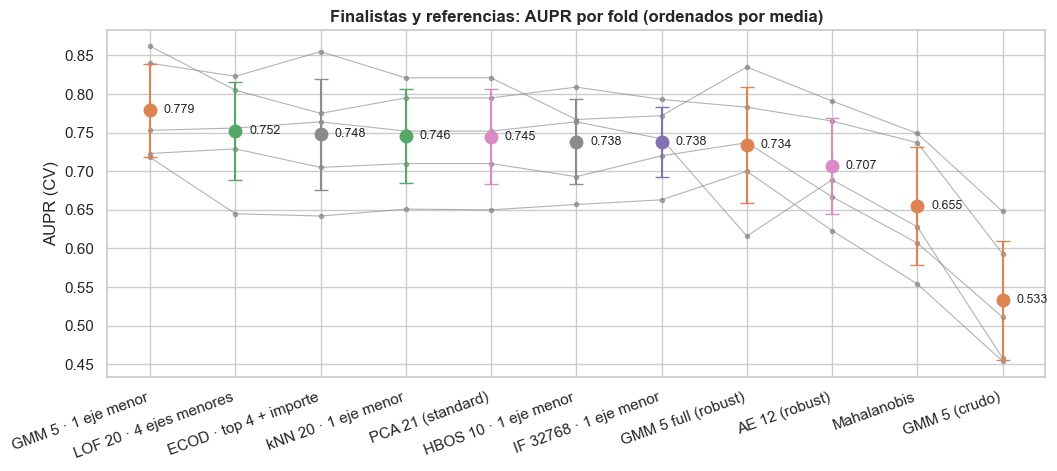

In [95]:
plot_folds(TODOS, title="Finalistas y referencias: AUPR por fold (ordenados por media)");

**Matriz de victorias por pares.** Cada celda dice en cuántos de los 5 folds el detector de la fila supera al de la columna. Un recuadro marca las diferencias **concluyentes** según la regla de §1: la fila gana en ≥ 4 folds, o su media supera a la de la columna en más de una std (la media de las dos).

In [96]:
fold_mat = np.array([por_fold(n) for n in TODOS])                    # detectores × folds
VICT = pd.DataFrame((fold_mat[:, None, :] > fold_mat[None, :, :]).sum(axis=2), index=TODOS, columns=TODOS)
med, sd = (np.array([RES[n][c] for n in TODOS]) for c in ("media", "std"))
CONCL = (VICT >= 4) | pd.DataFrame(med[:, None] - med[None, :] > (sd[:, None] + sd[None, :]) / 2, index=TODOS, columns=TODOS)

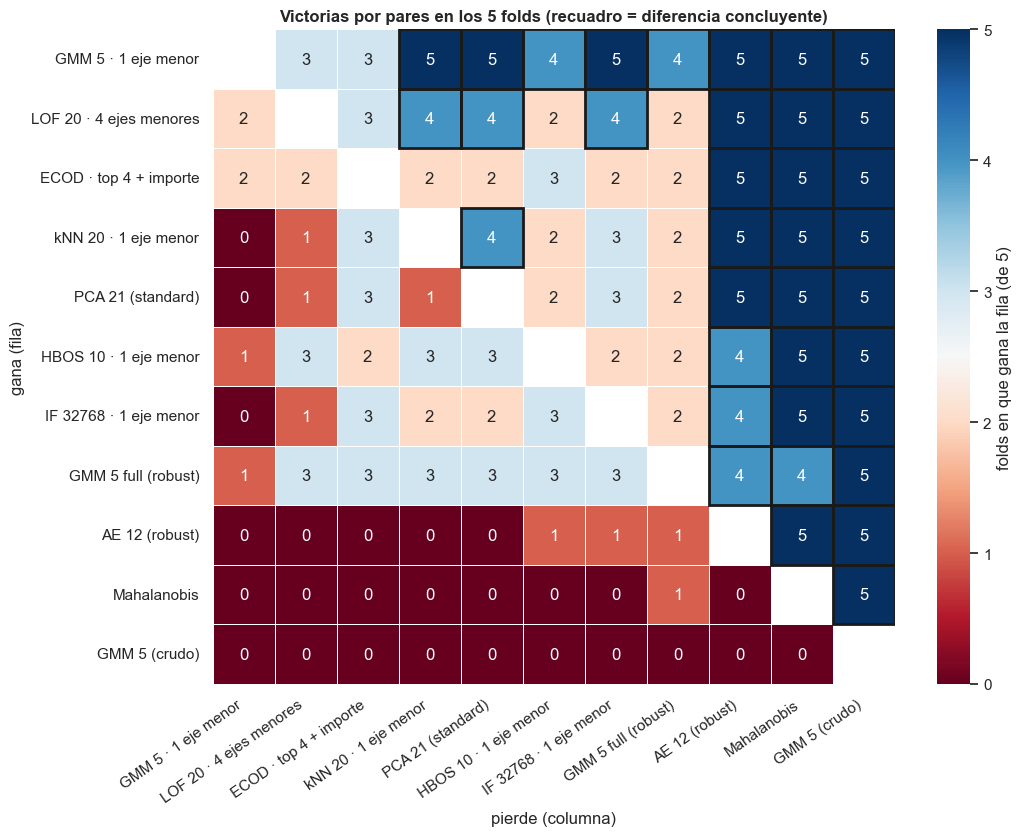

In [97]:
fig, ax = plt.subplots(figsize=(11, 8.5))
sns.heatmap(VICT, mask=np.eye(len(TODOS), dtype=bool), annot=True, cmap="RdBu", center=2.5, vmin=0, vmax=5, linewidths=.5,
            cbar_kws={"label": "folds en que gana la fila (de 5)", "ticks": range(6)}, ax=ax)
for i, j in zip(*np.where(CONCL.to_numpy())):
    ax.add_patch(plt.Rectangle((j, i), 1, 1, fill=False, ec="k", lw=2))
ax.set_xticklabels(TODOS, rotation=35, ha="right")
ax.grid(False)
ax.set(xlabel="pierde (columna)", ylabel="gana (fila)", title="Victorias por pares en los 5 folds (recuadro = diferencia concluyente)");

Para cada detector, a cuántos gana de forma concluyente y cuántos le ganan a él. El **grupo de cabeza** son los detectores a los que nadie gana de forma concluyente:

In [98]:
pd.DataFrame({"media": med, "diferencia con el mejor": med[0] - med, "gana a (concluyente)": CONCL.sum(axis=1), "le ganan (concluyente)": CONCL.sum(axis=0),
              "le gana el mejor (folds de 5)": VICT.iloc[0]}, index=TODOS).round(3)

,media,diferencia con el mejor,gana a (concluyente),le ganan (concluyente),le gana el mejor (folds de 5)
GMM 5 · 1 eje menor,0.779,0.000,8,0,0
LOF 20 · 4 ejes menores,0.752,0.028,6,0,3
ECOD · top 4 + importe,0.748,0.031,3,0,3
kNN 20 · 1 eje menor,0.746,0.033,4,2,5
PCA 21 (standard),0.745,0.034,3,3,5
HBOS 10 · 1 eje menor,0.738,0.041,3,1,4
IF 32768 · 1 eje menor,0.738,0.041,3,2,5
GMM 5 full (robust),0.734,0.045,3,1,4
AE 12 (robust),0.707,0.073,2,8,5
Mahalanobis,0.655,0.125,1,9,5


El GMM 5 · 1 eje menor gana en los 5 folds a kNN, PCA 21 e IF, y en 4 de 5 a HBOS y al GMM 5 full. A LOF y a ECOD solo les gana en 3 de 5, con diferencias de 0,028 y 0,031, menos de media std. La diferencia con kNN es parecida (0,033), pero sí es concluyente: los dos miran el mismo eje y sus folds suben y bajan juntos, así que el emparejamiento detecta diferencias más pequeñas. Todos los finalistas ganan a las dos referencias en al menos 4 folds.

> **Conclusión:** El mejor en media es **GMM 5 · 1 eje menor**, **0,779 ± 0,060**, y además es barato (**~2 s** la CV completa, frente a **16–19 s** del AE y del GMM 5 full). Gana de forma concluyente a **8** de los otros 10, pero a **LOF 20 · 4 ejes menores** (**0,752**) y a **ECOD · top 4 + importe** (**0,748**) solo en **3 de 5** folds. El GMM del profesor (**0,533**) pierde en los 5 folds contra todos. → **Impacto:** no hay un ganador claro, sino un **grupo de cabeza** de tres detectores de tres familias distintas (densidad, vecindad y marginal) a los que nadie gana de forma concluyente. La referencia no supervisada para el 03 es **GMM 5 · 1 eje menor** (**0,779** en CV): es el mejor en media y cuesta poco. §11 mira si los tres ven lo mismo o se pueden combinar.

## 11. ¿Se parecen entre sí?

**Qué miramos y por qué.** Dos detectores con AUPR parecida pueden ver los mismos fraudes o fraudes distintos, y solo en el segundo caso ayuda combinarlos: "ningún método gana siempre" (*no free lunch*, teoria/03, §22). Lo mismo decide qué scores pasan al 04 como variables, al estilo XGBOD (teoria/03, §22): si la correlación de rangos entre dos scores es baja y los dos tienen una AUPR razonable, el segundo aporta aunque por sí solo no gane (teoria/02, Aplicación B). Todo se calcula con los scores *out-of-fold* de la CV: no se reajusta ningún modelo.

**Correlación de rangos (Spearman)** entre los scores OOF de los nueve finalistas, en todas las filas de train y solo entre los fraudes. La AUPR solo depende del orden, así que importa la correlación de rangos, no la de los valores.

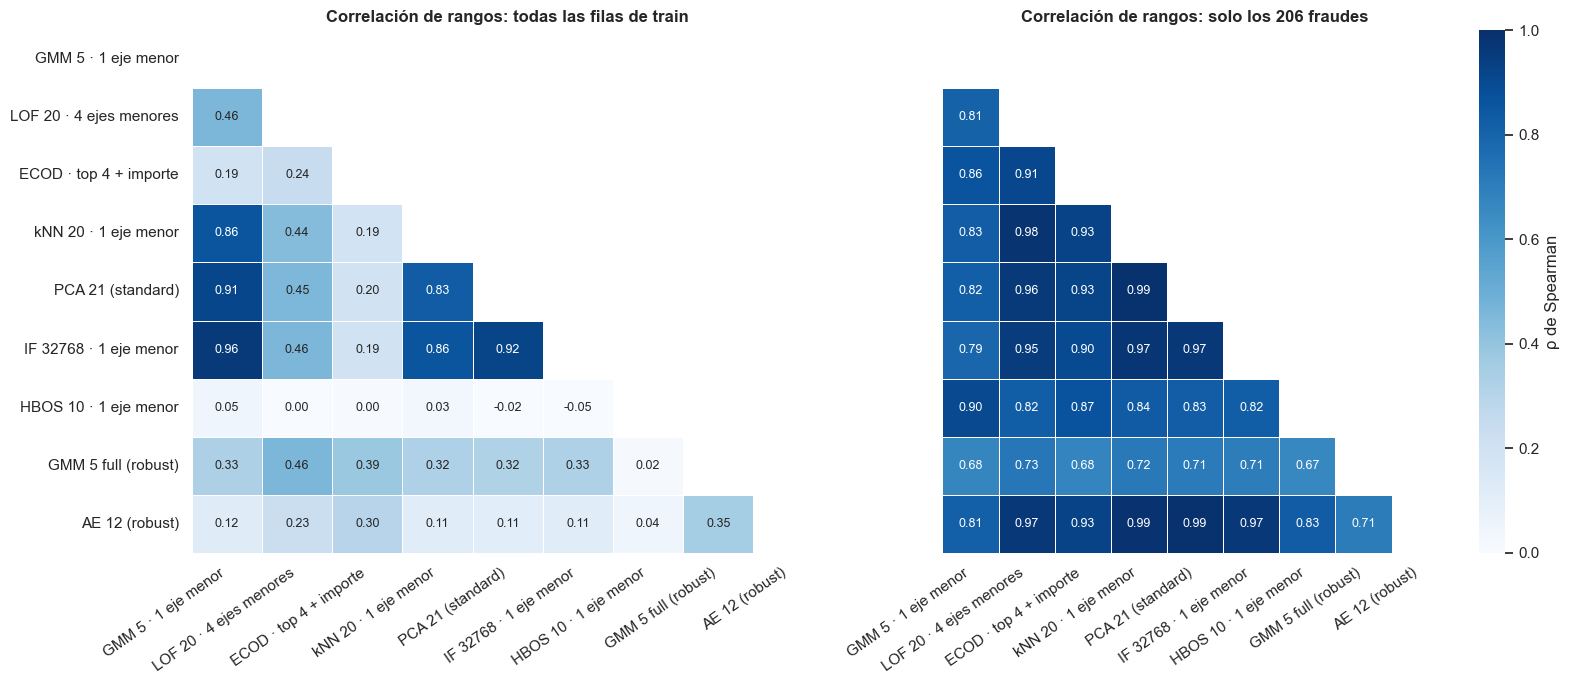

In [99]:
SC = pd.DataFrame({n: OOF[n] for n in FINALISTAS})
RHO = {"todas las filas de train": SC.corr("spearman"), "solo los 206 fraudes": SC[y_train.to_numpy() == 1].corr("spearman")}
fig, axs = plt.subplots(1, 2, figsize=(16, 7), sharey=True)
for ax, (tit, r) in zip(axs, RHO.items()):
    sns.heatmap(r, mask=np.triu(np.ones_like(r, bool)), annot=True, fmt=".2f", cmap="Blues", vmin=0, vmax=1, linewidths=.5,
                cbar=ax is axs[1], cbar_kws={"label": "ρ de Spearman"}, annot_kws={"fontsize": 9}, ax=ax)
    ax.set_xticklabels(ax.get_xticklabels(), rotation=35, ha="right")
    ax.grid(False)
    ax.set(title=f"Correlación de rangos: {tit}")
fig.tight_layout();

Los empates también cuentan: un score con pocos valores distintos deja a muchas filas en el mismo rango.

In [100]:
SC.nunique().rename("valores distintos del score OOF (train)").to_frame()

,valores distintos del score OOF (train)
GMM 5 · 1 eje menor,117288
LOF 20 · 4 ejes menores,117231
ECOD · top 4 + importe,117249
kNN 20 · 1 eje menor,110215
PCA 21 (standard),117288
IF 32768 · 1 eje menor,88317
HBOS 10 · 1 eje menor,38
GMM 5 full (robust),117287
AE 12 (robust),117287


En todas las filas, la ρ la decide sobre todo el orden de los ~117.000 normales, que apenas afecta a la AUPR. Ahí hay un bloque claro: los cuatro detectores sobre el eje menor (GMM, kNN, PCA 21 e IF) tienen ρ = 0,83–0,96 entre sí; en el resto de pares, ρ ≤ 0,46. HBOS sale con ρ ≈ 0 frente a todos porque su score solo toma **38** valores distintos: casi todos los normales empatan.

Entre los fraudes, en cambio, casi todos los ordenan igual (ρ = 0,79–0,99): coinciden en qué fraudes son más extremos, y el que más se aparta es el GMM 5 full (0,67–0,73). Para la AUPR lo que cuenta es la frontera entre las dos clases: **qué fraudes ve cada uno** por encima de los normales. Para medirlo, un corte por fold: un fraude se "ve" si su score supera el p99 de los normales de su fold de validación (un 1 % de falsas alarmas, ~234 por fold).

In [101]:
y_np = y_train.to_numpy()
def captura(n):
    """Fraudes de train cuyo score OOF supera el p99 de los normales de su fold de validación."""
    c = np.zeros(len(y_np), bool)
    for _, iv in cv_splits:
        s = OOF[n][iv]
        c[iv] = s > np.quantile(s[y_np[iv] == 0], .99)
    return c[y_np == 1]
CAPT = pd.DataFrame({n: captura(n) for n in FINALISTAS})
MEJOR = "GMM 5 · 1 eje menor"

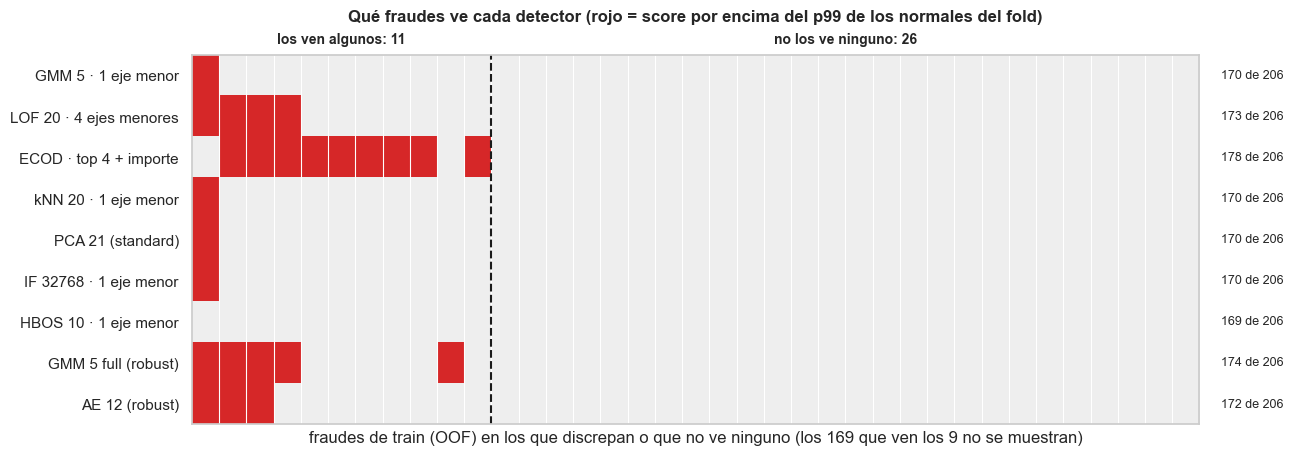

In [102]:
# solo los fraudes en los que discrepan o que no ve nadie (cada columna es un fraude)
n_ven = CAPT.sum(axis=1)
todos, ninguno = int((n_ven == CAPT.shape[1]).sum()), int((n_ven == 0).sum())
sub = CAPT[n_ven < CAPT.shape[1]].assign(n=n_ven, g=CAPT[MEJOR]).sort_values(["n", "g"], ascending=False).drop(columns=["n", "g"])
fig, ax = plt.subplots(figsize=(13, 4.8))
ax.imshow(sub.T.to_numpy(int), aspect="auto", interpolation="nearest", cmap=plt.matplotlib.colors.ListedColormap(["#eeeeee", C[1]]))
ax.vlines(np.arange(len(sub)) + .5, -.5, CAPT.shape[1] - .5, colors="white", lw=.8)
ax.axvline(len(sub) - ninguno - .5, c="k", lw=1.5, ls="--")
for x, txt in [((len(sub) - ninguno) / 2 - .5, f"los ven algunos: {len(sub) - ninguno}"), (len(sub) - ninguno / 2 - .5, f"no los ve ninguno: {ninguno}")]:
    ax.text(x, -.7, txt, ha="center", va="bottom", fontsize=10, weight="bold")
for i, n in enumerate(CAPT):
    ax.text(len(sub) + .3, i, f"{CAPT[n].sum()} de {len(CAPT)}", va="center", fontsize=9)
ax.set_yticks(range(CAPT.shape[1]), CAPT.columns)
ax.set_xticks([])
ax.set_xlabel(f"fraudes de train (OOF) en los que discrepan o que no ve ninguno (los {todos} que ven los 9 no se muestran)")
ax.set_title("Qué fraudes ve cada detector (rojo = score por encima del p99 de los normales del fold)", pad=24)
ax.grid(False);

Lo que añade cada uno al mejor individual: cuántos fraudes ve que el GMM 5 · 1 eje menor no ve, y cuántos de los suyos pierde.

In [103]:
g = CAPT[MEJOR]
t_capt = pd.DataFrame({"fraudes vistos": CAPT.sum(), "% de 206": 100 * CAPT.mean(),
                       f"añade al {MEJOR}": (CAPT & ~g.to_numpy()[:, None]).sum(),
                       f"no ve de los del {MEJOR}": (~CAPT & g.to_numpy()[:, None]).sum()})
t_capt.loc["cualquiera de los 9"] = [CAPT.any(axis=1).sum(), 100 * CAPT.any(axis=1).mean(), CAPT.any(axis=1).sum() - g.sum(), 0]
t_capt.round(1).astype({c: int for c in t_capt.columns if c != "% de 206"})

,fraudes vistos,% de 206,añade al GMM 5 · 1 eje menor,no ve de los del GMM 5 · 1 eje menor
GMM 5 · 1 eje menor,170,82.5,0,0
LOF 20 · 4 ejes menores,173,84.0,3,0
ECOD · top 4 + importe,178,86.4,9,1
kNN 20 · 1 eje menor,170,82.5,0,0
PCA 21 (standard),170,82.5,0,0
IF 32768 · 1 eje menor,170,82.5,0,0
HBOS 10 · 1 eje menor,169,82.0,0,1
GMM 5 full (robust),174,84.5,4,0
AE 12 (robust),172,83.5,2,0
cualquiera de los 9,180,87.4,10,0


El GMM 5 · 1 eje menor ve 170 fraudes y deja fuera 36 (el ~1/6 "dentro de la nube" de §2). kNN, PCA 21 e IF ven exactamente los mismos 170, y HBOS 169 de ellos. ECOD es el que más añade (9), y entre los nueve llegan a 180.

**Combinaciones por rangos.** Las escalas de los scores no son comparables, así que se promedian **rangos** (teoria/03, §19). El rango se calcula **dentro de cada fold de validación**, para que todos los folds estén en la misma escala. Probamos pocas combinaciones, elegidas por la diversidad de arriba y no por su AUPR:

1. el mejor con el otro detector de cabeza de distinta familia: **LOF 20 · 4 ejes menores** (vecindad);
2. el mejor con el que más fraudes nuevos ve: **ECOD · top 4 + importe** (marginal, el de menor ρ del grupo de cabeza);
3. los tres del grupo de cabeza de §10;
4. el mejor con el finalista menos correlado con él: **AE 12 (robust)** (ρ = 0,12; reconstrucción, Aplicación B). HBOS no cuenta: su ρ ≈ 0 se debe a los empates;
5. **control**: el mejor con **IF 32768 · 1 eje menor**, que mira el mismo eje (ρ = 0,96). Si el control mejora tanto como las demás, la ganancia no viene de la diversidad.

In [104]:
FAM["ensemble"] = "#64b5cd"
def evaluar_rangos(nombre, miembros):
    """Media de los rangos OOF de varios finalistas, con el rango calculado dentro de cada fold de validación. Mismo formato que evaluar()."""
    oof = np.zeros(len(y_np))
    for _, iv in cv_splits:
        oof[iv] = np.mean([stats.rankdata(OOF[m][iv]) / len(iv) for m in miembros], axis=0)
    auprs = [average_precision_score(y_np[iv], oof[iv]) for _, iv in cv_splits]
    RES[nombre] = {"familia": "ensemble", "n_feats": len(set().union(*(FINALISTAS[m][1] for m in miembros))), "media": np.mean(auprs),
                   "std": np.std(auprs), "segundos": sum(RES[m]["segundos"] for m in miembros), **{f"fold{k}": a for k, a in enumerate(auprs)}}
    OOF[nombre] = oof
    print(f"{nombre}: CV AUPR = {RES[nombre]['media']:.3f} ± {RES[nombre]['std']:.3f}")

In [105]:
COMBOS = {"Rangos: GMM eje + LOF 4 ejes": [MEJOR, "LOF 20 · 4 ejes menores"],
          "Rangos: GMM eje + ECOD top 4": [MEJOR, "ECOD · top 4 + importe"],
          "Rangos: GMM eje + LOF + ECOD": [MEJOR, "LOF 20 · 4 ejes menores", "ECOD · top 4 + importe"],
          "Rangos: GMM eje + AE 12": [MEJOR, "AE 12 (robust)"],
          "Rangos: GMM eje + IF eje (control)": [MEJOR, "IF 32768 · 1 eje menor"]}
for nombre, miembros in COMBOS.items():
    evaluar_rangos(nombre, miembros)

Rangos: GMM eje + LOF 4 ejes: CV AUPR = 0.790 ± 0.061
Rangos: GMM eje + ECOD top 4: CV AUPR = 0.793 ± 0.068
Rangos: GMM eje + LOF + ECOD: CV AUPR = 0.786 ± 0.064
Rangos: GMM eje + AE 12: CV AUPR = 0.785 ± 0.058
Rangos: GMM eje + IF eje (control): CV AUPR = 0.787 ± 0.059


Cada combinación frente al mejor individual, por pares:

In [106]:
dif = lambda a, b: por_fold(a) - por_fold(b)
pd.DataFrame({c: {"media": RES[c]["media"], "std": RES[c]["std"], f"diferencia con {MEJOR}": dif(c, MEJOR).mean(),
                  "peor fold (diferencia)": dif(c, MEJOR).min(), "mejor fold (diferencia)": dif(c, MEJOR).max(),
                  "folds que gana (de 5)": int((dif(c, MEJOR) > 0).sum())} for c in COMBOS}).T.astype(float).round(3).astype({"folds que gana (de 5)": int})

,media,std,diferencia con GMM 5 · 1 eje menor,peor fold (diferencia),mejor fold (diferencia),folds que gana (de 5)
Rangos: GMM eje + LOF 4 ejes,0.790,0.061,0.010,-0.009,0.024,4
Rangos: GMM eje + ECOD top 4,0.793,0.068,0.013,-0.016,0.037,4
Rangos: GMM eje + LOF + ECOD,0.786,0.064,0.007,-0.026,0.027,3
Rangos: GMM eje + AE 12,0.785,0.058,0.005,-0.010,0.023,3
Rangos: GMM eje + IF eje (control),0.787,0.059,0.008,-0.005,0.021,4


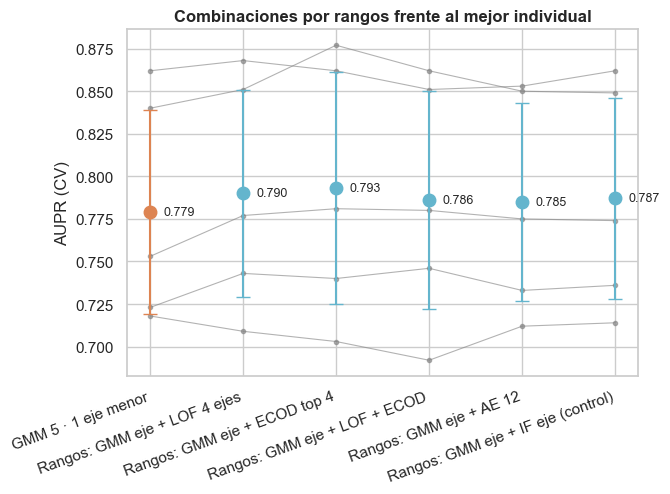

In [107]:
plot_folds([MEJOR, *COMBOS], title="Combinaciones por rangos frente al mejor individual");

Las cinco combinaciones superan al GMM 5 · 1 eje menor en media, pero por poco: de **+0,005** (con el AE) a **+0,013** (con ECOD, **0,793 ± 0,068**), menos de una cuarta parte de la std, y todas pierden en algún fold (hasta **−0,026**). GMM eje + LOF y GMM eje + ECOD ganan en 4 de 5 folds, que es la excepción de la regla de §1. Pero el **control** con IF, que mira el mismo eje y no añade ningún fraude, también gana en 4 de 5 (**+0,008**). Promediar dos rankings casi iguales ya suaviza el ruido, así que esa ganancia no viene de la diversidad. Además, quedarse con la mejor de cinco combinaciones medidas con la misma CV da una cifra optimista. Ninguna combinación gana de forma concluyente al mejor individual.

**Qué pasa al 04.** Los scores que pasan al 04 como variables deben tener buena AUPR y baja correlación entre sí (Aplicación B). Del bloque del eje menor (GMM, kNN, PCA 21, IF y también HBOS, que no añade ningún fraude) basta uno: el GMM, que es el mejor. LOF y ECOD, los otros dos del grupo de cabeza, miran otras variables. El GMM 5 full y el AE usan las 22 variables sin proyectar y ven fraudes que el GMM eje no ve. El AE es además el detector que propone la Aplicación B.

In [108]:
PARA_04 = ["GMM 5 · 1 eje menor", "LOF 20 · 4 ejes menores", "ECOD · top 4 + importe", "GMM 5 full (robust)", "AE 12 (robust)"]
r = RHO["todas las filas de train"].loc[PARA_04, PARA_04].mask(np.eye(len(PARA_04), dtype=bool))
pd.DataFrame({"AUPR (CV)": [RES[n]["media"] for n in PARA_04], "ρ máx. con los otros (todas las filas)": r.max(),
              f"añade al {MEJOR}": t_capt.loc[PARA_04].iloc[:, 2].astype(int)}, index=PARA_04).round(3)

,AUPR (CV),ρ máx. con los otros (todas las filas),añade al GMM 5 · 1 eje menor
GMM 5 · 1 eje menor,0.779,0.461,0
LOF 20 · 4 ejes menores,0.752,0.461,3
ECOD · top 4 + importe,0.748,0.386,9
GMM 5 full (robust),0.734,0.460,4
AE 12 (robust),0.707,0.354,2


In [109]:
ENSEMBLE = None     # ninguna combinación por rangos gana de forma concluyente al GMM 5 · 1 eje menor

> **Conclusión:** Los cuatro detectores sobre el eje menor son, en la práctica, el mismo: ρ = **0,83–0,96** en todas las filas y **los mismos 170 fraudes** (**82,5 %**) con un 1 % de falsas alarmas. Los demás añaden poco al GMM 5 · 1 eje menor (ECOD **9** fraudes, GMM 5 full **4**, LOF **3**, AE **2**): los nueve juntos ven **180 de 206** (**87,4 %**), y **26** (~1 de cada 8) no los ve ninguno. Las combinaciones por rangos suben a **0,785–0,793**, pero el control sin diversidad sube casi lo mismo (**0,787**, 4 de 5 folds): ninguna gana de forma concluyente, y `ENSEMBLE = None`. → **Impacto:** la referencia para el 03 sigue siendo el **GMM 5 · 1 eje menor** solo (**0,779**). Al 04 pasan cinco scores con ρ ≤ **0,46** entre ellos (`PARA_04`: GMM eje, LOF 4 ejes, ECOD top 4, GMM 5 full y AE 12), al estilo XGBOD: el supervisado decide cuánto pesa cada uno. Los 26 fraudes que no ve nadie solo los podrá encontrar el supervisado (03), y solo si se parecen a fraudes ya etiquetados.

## 12. ¿Se confirma en test?

**Qué miramos y por qué.** Todas las elecciones de las secciones anteriores se han hecho con la CV, y al elegir entre muchas configuraciones con los mismos folds sus cifras salen algo optimistas (§9). El test fijo (51.266 filas, 89 fraudes) se usa aquí por primera y única vez, solo para confirmar: si la AUPR de test cae dentro del ruido de la CV (§1), la CV no nos ha engañado. No cambia ninguna elección.

Cada finalista y cada referencia se ajusta con **todos los normales de train** (los 5 folds juntos) y puntúa el test y producción. Producción se puntúa ya aquí, con el mismo modelo, para exportarla en §14.

In [110]:
# ajuste con los normales de train (en paralelo) → scores de test y de producción
def _ajustar(nombre, est, cols):
    with threadpool_limits(2):
        m = fit(est, tr[cols].to_numpy(float), y_train)
        return nombre, m, score(m, te[cols].to_numpy(float)), score(m, df_prod[cols].to_numpy(float))

MODELOS = {**FINALISTAS, **REFERENCIAS}
AJUSTADOS, SC_TEST, SC_PROD = {}, {}, {}
t0 = time.time()
for n, m, s_te, s_pr in Parallel(n_jobs=6)(delayed(_ajustar)(n, est, cols) for n, (est, cols) in MODELOS.items()):
    AJUSTADOS[n], SC_TEST[n], SC_PROD[n] = m, s_te, s_pr
print(f"{len(AJUSTADOS)} detectores ajustados y puntuados en {time.time() - t0:.0f} s")

11 detectores ajustados y puntuados en 21 s


Si §11 ha definido un ensemble (`ENSEMBLE`), su score es la media de los rangos de sus detectores, calculados dentro de cada conjunto (test y producción por separado), como en la CV.

In [111]:
if globals().get("ENSEMBLE"):
    media_rangos = lambda S: np.mean([stats.rankdata(S[n]) / len(S[n]) for n in ENSEMBLE], axis=0)
    SC_TEST["Ensemble"], SC_PROD["Ensemble"] = media_rangos(SC_TEST), media_rangos(SC_PROD)

La tabla de test, **ordenada por la AUPR de CV** (el test no elige). `aupr_sin_dup` quita las 1.643 filas de test con copia exacta en train (D-1.1), y `test − CV` es la diferencia entre la AUPR de test y la media de CV.

In [112]:
import io, contextlib
with contextlib.redirect_stdout(io.StringIO()):            # report() imprime una línea por modelo: basta la tabla
    TEST = pd.DataFrame([report(n, s) for n, s in SC_TEST.items()]).set_index("modelo")
cv = pd.DataFrame(RES).T.reindex(TEST.index)
TEST = TEST.assign(familia=cv["familia"], cv_media=cv["media"].astype(float), cv_std=cv["std"].astype(float))
TEST["test − CV"] = TEST["aupr"] - TEST["cv_media"]
TEST = TEST[["familia", "cv_media", "cv_std", "aupr", "aupr_sin_dup", "roc_auc", "test − CV"]].sort_values("cv_media", ascending=False)
TEST.round(3)

,familia,cv_media,cv_std,aupr,aupr_sin_dup,roc_auc,test − CV
modelo,,,,,,,
GMM 5 · 1 eje menor,densidad,0.779,0.060,0.736,0.719,0.930,-0.043
LOF 20 · 4 ejes menores,vecindad,0.752,0.063,0.671,0.648,0.935,-0.081
ECOD · top 4 + importe,marginal,0.748,0.072,0.683,0.661,0.966,-0.066
kNN 20 · 1 eje menor,vecindad,0.746,0.061,0.664,0.639,0.925,-0.082
PCA 21 (standard),reconstrucción,0.745,0.061,0.664,0.640,0.923,-0.081
HBOS 10 · 1 eje menor,marginal,0.738,0.055,0.707,0.689,0.888,-0.031
IF 32768 · 1 eje menor,aislamiento,0.738,0.045,0.690,0.667,0.932,-0.048
GMM 5 full (robust),densidad,0.734,0.075,0.617,0.589,0.931,-0.117
AE 12 (robust),reconstrucción,0.707,0.062,0.630,0.602,0.933,-0.077


El GMM del profesor da aquí **0,495**, no el 0,567 del notebook de partida. Las filas de train son las mismas, pero aquí están ordenadas por `row_id`, y el profesor las tenía en el orden barajado de `train_test_split`. Con la misma semilla, otro orden cambia la inicialización por k-means (§4). Lo comprobamos ajustando el mismo modelo con las filas en el orden del profesor:

In [113]:
from sklearn.model_selection import train_test_split
tr_prof = train_test_split(df_const, test_size=.3, random_state=SEED, stratify=df_const["Class"])[0]   # train del notebook de partida
assert set(tr_prof["row_id"]) == set(tr["row_id"]), "no son las mismas filas"
gmm_prof = fit(REFERENCIAS["GMM 5 (crudo)"][0], tr_prof[FEAT_RAW].to_numpy(float), tr_prof["Class"])
print(f"GMM 5 (crudo), filas en el orden del profesor: AUPR test = {average_precision_score(y_test, score(gmm_prof, te[FEAT_RAW].to_numpy(float))):.3f}")

GMM 5 (crudo), filas en el orden del profesor: AUPR test = 0.567


CV frente a test: cada punto es un detector, con la AUPR media ± 1 std de CV en horizontal. Sobre la diagonal, el test confirma la CV; la banda gris es ± 1 std típica de la CV (regla de §1).

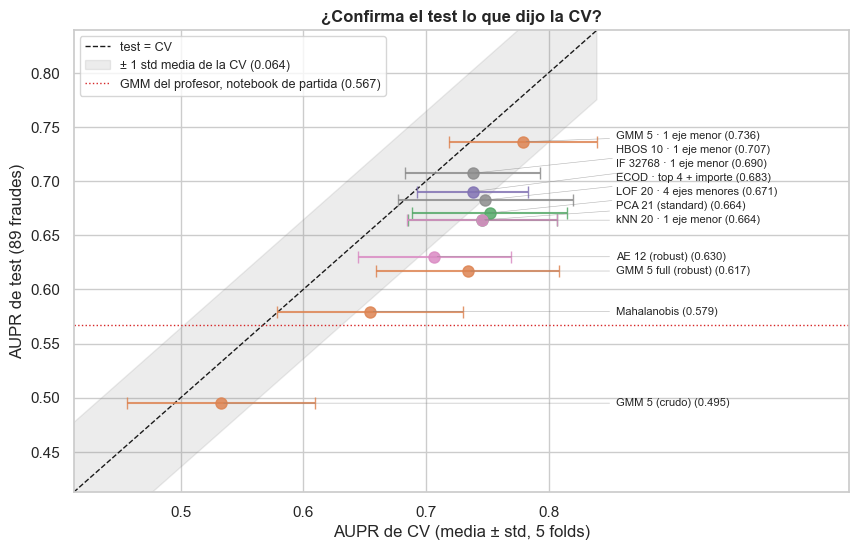

In [114]:
fig, ax = plt.subplots(figsize=(10, 6))
std_cv = TEST["cv_std"].mean()
lim = np.array([TEST["cv_media"].min() - .12, max(TEST["cv_media"].max(), TEST["aupr"].max()) + .06])
x_txt = (TEST["cv_media"] + TEST["cv_std"]).max() + .015                   # etiquetas en columna, a la derecha
y_txt = TEST["aupr"].sort_values().copy()                                   # y separadas para que no se pisen
for i in range(1, len(y_txt)):
    y_txt.iloc[i] = max(y_txt.iloc[i], y_txt.iloc[i - 1] + .013)
ax.plot(lim, lim, c="k", lw=1, ls="--", label="test = CV")
ax.fill_between(lim, lim - std_cv, lim + std_cv, color="grey", alpha=.15, label=f"± 1 std media de la CV ({std_cv:.3f})")
for n, r in TEST.iterrows():
    ax.errorbar(r["cv_media"], r["aupr"], xerr=r["cv_std"], fmt="o", ms=8, capsize=4, c=FAM.get(r["familia"], "k"), alpha=.85)
    ax.annotate(f"{n} ({r['aupr']:.3f})", (r["cv_media"], r["aupr"]), xytext=(x_txt, y_txt[n]), va="center", fontsize=8,
                arrowprops=dict(arrowstyle="-", color="grey", lw=.4, alpha=.6))
ax.axhline(.567, c=C[1], lw=1, ls=":", label="GMM del profesor, notebook de partida (0.567)")
ax.set(xlim=(lim[0], x_txt + .19), ylim=lim, xlabel="AUPR de CV (media ± std, 5 folds)", ylabel="AUPR de test (89 fraudes)",
       title="¿Confirma el test lo que dijo la CV?")
ax.set_xticks([t for t in ax.get_xticks() if lim[0] <= t <= lim[1]])
ax.legend(loc="upper left", fontsize=9);

In [115]:
# resumen de la comparación CV–test
pd.Series({"detectores con test < CV": f"{(TEST['test − CV'] < 0).sum()} de {len(TEST)}",
           "test dentro de CV ± 1 std": f"{(TEST['test − CV'].abs() <= TEST['cv_std']).sum()} de {len(TEST)}",
           "test − CV (mediana)": round(TEST["test − CV"].median(), 3),
           "Spearman CV–test": round(stats.spearmanr(TEST["cv_media"], TEST["aupr"]).statistic, 3),
           "mejor en test": TEST["aupr"].idxmax()}, name="valor").to_frame()

,valor
detectores con test < CV,11 de 11
test dentro de CV ± 1 std,5 de 11
test − CV (mediana),-0.075
Spearman CV–test,0.755
mejor en test,GMM 5 · 1 eje menor


La AUPR de test baja en todos, también en los que no se eligieron con la CV: Mahalanobis da 0,579, dentro del rango de sus folds en §1 (0,554–0,749). Es sobre todo un test algo más difícil que la media de los folds, más algo de optimismo por elegir con la CV (§9). El orden se mantiene en lo grueso: el mejor de CV es también el mejor en test, y el mayor cambio es HBOS, que sube del sexto al segundo puesto.

¿Es clara la mejora sobre el profesor? **Bootstrap estratificado** del test (1.000 réplicas): se remuestrean normales y fraudes por separado y se recalcula la AUPR del mejor de CV y del GMM del profesor **con las mismas filas** en cada réplica, para medir también la diferencia.

In [116]:
MEJOR_CV = TEST.index[0]
PAR = [MEJOR_CV, "GMM 5 (crudo)"]
rng = np.random.default_rng(SEED)
y_te = y_test.to_numpy()
i0, i1 = np.flatnonzero(y_te == 0), np.flatnonzero(y_te == 1)
boot_te = []
for _ in range(1000):
    ib = np.r_[rng.choice(i0, len(i0)), rng.choice(i1, len(i1))]
    boot_te.append([average_precision_score(y_te[ib], SC_TEST[n][ib]) for n in PAR])
boot_te = pd.DataFrame(boot_te, columns=PAR).assign(diferencia=lambda b: b[PAR[0]] - b[PAR[1]])

In [117]:
# AUPR de test e intervalo bootstrap del 95 %
ic_te = boot_te.quantile([.025, .975]).T.set_axis(["p2.5", "p97.5"], axis=1)
ic_te.insert(0, "AUPR test", [TEST.loc[PAR[0], "aupr"], TEST.loc[PAR[1], "aupr"], TEST.loc[PAR[0], "aupr"] - TEST.loc[PAR[1], "aupr"]])
ic_te["% réplicas > 0"] = [np.nan, np.nan, 100 * (boot_te["diferencia"] > 0).mean()]
ic_te.round(3).fillna("")

,AUPR test,p2.5,p97.5,% réplicas > 0
GMM 5 · 1 eje menor,0.736,0.642,0.822,
GMM 5 (crudo),0.495,0.400,0.589,
diferencia,0.241,0.159,0.324,100.0


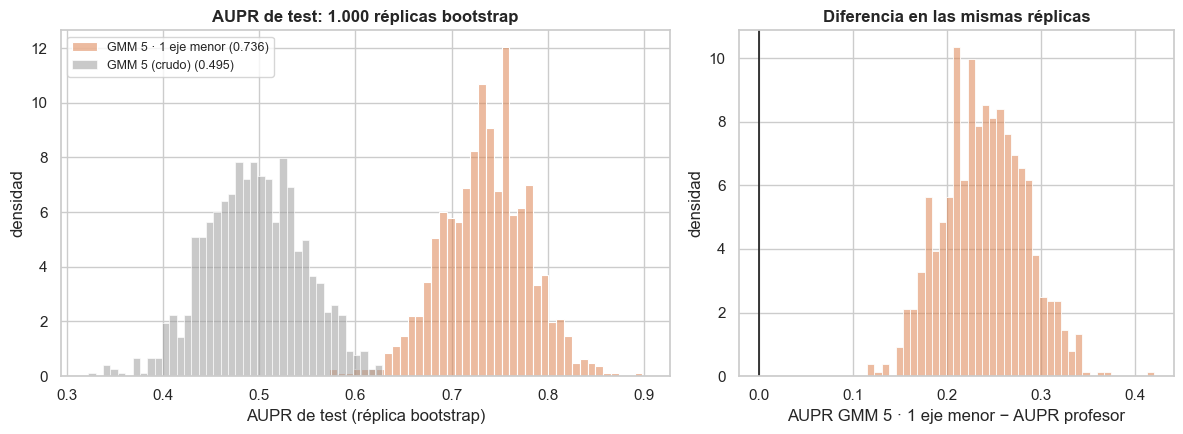

In [118]:
fig, (a1, a2) = plt.subplots(1, 2, figsize=(12, 4.5), gridspec_kw={"width_ratios": [1.4, 1]})
for n, c in zip(PAR, [FAM["densidad"], C[0]]):
    sns.histplot(boot_te[n], bins=40, stat="density", color=c, alpha=.55, ax=a1, label=f"{n} ({TEST.loc[n, 'aupr']:.3f})")
a1.set(xlabel="AUPR de test (réplica bootstrap)", ylabel="densidad", title="AUPR de test: 1.000 réplicas bootstrap")
a1.legend(fontsize=9)
sns.histplot(boot_te["diferencia"], bins=40, stat="density", color=FAM["densidad"], alpha=.55, ax=a2)
a2.axvline(0, c="k", lw=1.2)
a2.set(xlabel=f"AUPR {PAR[0]} − AUPR profesor", ylabel="densidad", title="Diferencia en las mismas réplicas")
fig.tight_layout();

Curvas precisión-recall en test del mejor de CV, los dos siguientes y el GMM del profesor:

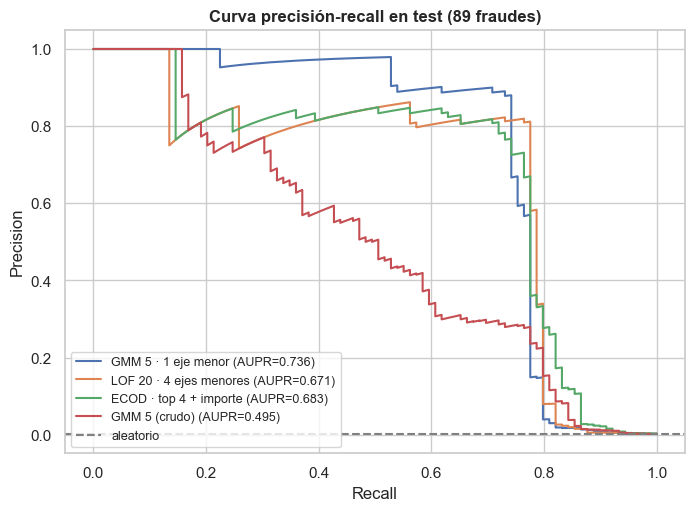

In [119]:
CURVAS = [*TEST.index[:3], "GMM 5 (crudo)"]
ax = plot_pr(y_test, {n: SC_TEST[n] for n in CURVAS}, ax=plt.subplots(figsize=(8, 5.5))[1])
ax.set(title="Curva precisión-recall en test (89 fraudes)")
ax.legend(fontsize=9, loc="lower left");

Los tres primeros de CV mantienen la precisión alta hasta un recall de ~0,75–0,8 y después caen en vertical: el último ~20–25 % de fraudes de test no se distingue de los normales.

> **Conclusión:** El mejor de la CV, **GMM 5 · 1 eje menor**, es también el mejor en test: **0,736** (**0,719** sin duplicados), dentro de su ruido de CV (**−0,043**, std 0,060). Los **11** detectores bajan en test (mediana **−0,075**, ~1 std), pero el orden se mantiene en lo grueso (Spearman CV–test **0,755**). La mejora sobre el profesor es clara: **+0,241** sobre el mismo GMM ajustado aquí (**0,495**; IC 95 % de la diferencia **0,159–0,324**, positiva en el **100 %** de las réplicas), y su 0,567 del notebook de partida, que se reproduce exacto con su orden de filas, queda por debajo del IC del mejor (**0,642–0,822**). → **Impacto:** el test confirma la CV. **GMM 5 · 1 eje menor** es la referencia no supervisada que tiene que batir el 03, con una AUPR esperada de ~0,74 (IC 0,64–0,82), no el 0,78 de la CV. Sin data shift (D-1.3), el test es la mejor estimación para producción, pero con 89 fraudes su incertidumbre es de ±0,09: *"siempre se suele acertar mirando para atrás, pero nunca mirando para delante"* [01:00:29].

## 13. ¿Por qué un punto es fraude?

**Qué miramos y por qué.** Una alerta hay que poder explicarla, y la explicación mínima es el propio umbral: "tengo un umbral que son 5 y esto estaba a una distancia de 6", más "qué características… son las que han hecho que esta distancia sea esa" [03:24:27]. Con outliers no sirven LIME, SHAP ni los contrafactuales directos: el punto está lejos de cualquier frontera y la aproximación local es mala [03:30:31]–[03:34:17]. El mejor detector, **GMM 5 · 1 eje menor** (§9), lo pone fácil: su score depende de una sola coordenada, que es una suma ponderada de las 22 variables.

Se ajusta como en §12, con todos los normales de train. Los fraudes de train no entran en el ajuste, así que su score es el de una transacción nueva: son los ejemplos de esta sección, y el test no se vuelve a mirar.

In [120]:
# el mejor detector, ajustado solo con los normales de train
m_eje = fit(GMM_FINAL_SEL, tr[FEATS_GMM], y_train)
eje = m_eje[0]                                                       # EjesPropios(1): escalador + eje menor
Z_tr = pd.DataFrame(eje.sc_.transform(tr[FEATS_GMM]), columns=FEATS_GMM, index=tr.index)   # variables estandarizadas
lado = np.sign(stats.skew(Z_tr[y_train == 0].to_numpy() @ eje.V_[:, 0]))   # signo: cola larga de los normales en positivo
pesos = pd.Series(lado * eje.V_[:, 0], index=FEATS_GMM)
z_eje = Z_tr.to_numpy() @ pesos.to_numpy()                           # coordenada de cada transacción en el eje menor
s_eje = score(m_eje, tr[FEATS_GMM])                                  # −log p(z) del GMM 1D
y_np = y_train.to_numpy()

### 13.1 Qué mira el detector: el eje menor

La coordenada de una transacción en el eje menor es $z = \sum_j w_j\,\tilde x_j$, donde $\tilde x_j$ es la variable $j$ estandarizada con los normales y $w_j$ su peso (el autovector de §3). El signo de un autovector es arbitrario: lo fijamos para que la cola larga de los normales quede en positivo, sin mirar etiquetas (en §3 se fijó con X17 positiva; aquí queda al revés). Los pesos:

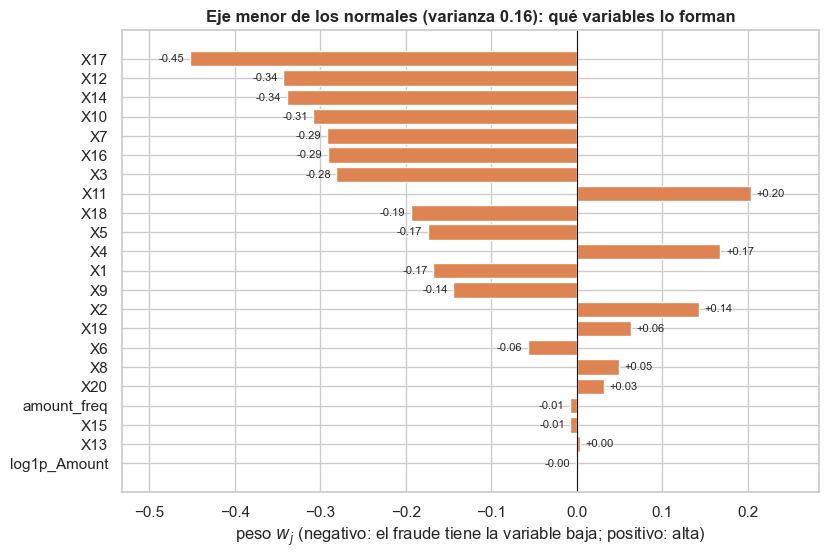

In [121]:
fig, ax = plt.subplots(figsize=(9, 6))
p = pesos.sort_values(key=abs)
ax.barh(p.index, p, color=FAM["densidad"])
for i, w in enumerate(p):
    ax.annotate(f"{w:+.2f}", (w, i), xytext=(4 if w > 0 else -4, 0), textcoords="offset points", va="center",
                ha="left" if w > 0 else "right", fontsize=8)
ax.axvline(0, c="k", lw=.8)
ax.set_xlim(p.min() - .08, p.max() + .08)
ax.set(xlabel="peso $w_j$ (negativo: el fraude tiene la variable baja; positivo: alta)", ylabel="",
       title=f"Eje menor de los normales (varianza {np.var(z_eje[y_np == 0]):.2f}): qué variables lo forman");

Un punto está lejos en el eje menor cuando **X17, X12, X14 y X10** (y después X7, X16 y X3) son muy negativas **a la vez**, con X11 y X4 algo positivas. Es la **cola diagonal** del top 4 en §8 del 01, ahora con las 22 variables. El importe pesa casi cero: el detector no mira cuánto se paga. Cada una de esas variables ya separaba algo por sí sola (§5 del 01); el eje las suma con los pesos que dicta la covarianza de los normales, en la dirección en la que estos casi no varían (§3).

### 13.2 El umbral

El GMM de 5 gaussianas se ajusta sobre $z$, y su score es $-\log p(z)$. Como umbral tomamos el **p99,9 del score de los normales** de train (el mismo percentil que en §3). Arriba, el score frente a la coordenada; abajo, dónde caen normales y fraudes (eje x lineal entre −0,5 y 0,5 y logarítmico fuera):

In [122]:
UMBRAL_EJE = np.quantile(s_eje[y_np == 0], .999)
score_z = lambda z: -m_eje[1].score_samples(lado * np.asarray(z).reshape(-1, 1))     # score en función de z
g = np.linspace(-2, 2, 40_001)
nucleo = g[score_z(g) <= UMBRAL_EJE][[0, -1]]                         # tramo de z que el umbral considera normal
pd.Series({"umbral (score)": UMBRAL_EJE, "z mínimo normal": nucleo[0], "z máximo normal": nucleo[1]}, name="p99,9 de los normales").round(2).to_frame().T

,umbral (score),z mínimo normal,z máximo normal
"p99,9 de los normales",11.28,-0.54,0.55


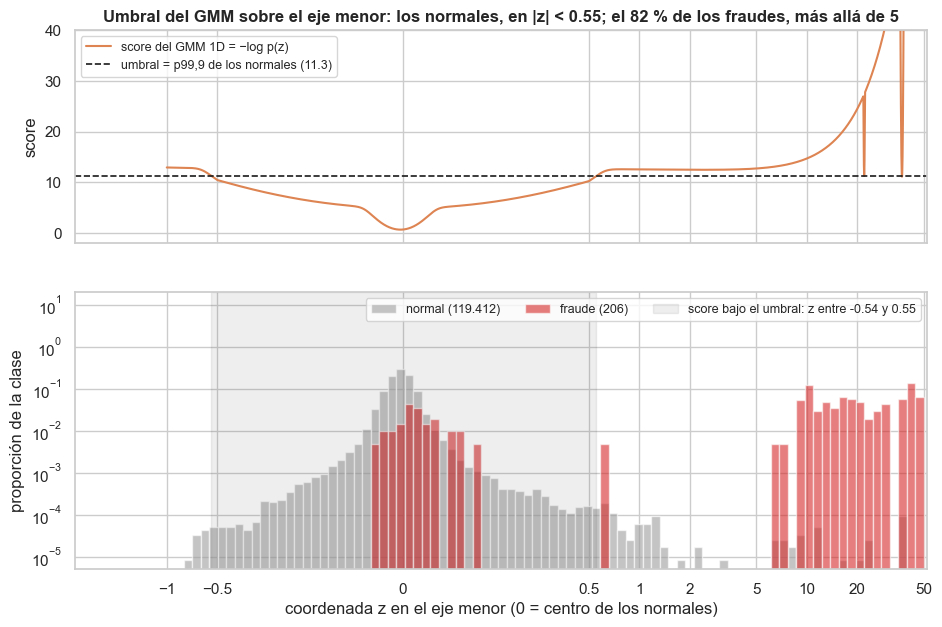

In [123]:
from matplotlib.scale import SymmetricalLogTransform
fig, (a1, a2) = plt.subplots(2, 1, figsize=(11, 7), sharex=True, gridspec_kw={"height_ratios": [1, 1.3]})
gz = np.r_[np.linspace(-1, 1, 4001), np.linspace(1, 50, 20_000)]
a1.plot(gz, score_z(gz), c=FAM["densidad"], lw=1.5, label="score del GMM 1D = −log p(z)")
a1.axhline(UMBRAL_EJE, c="k", ls="--", lw=1.2, label=f"umbral = p99,9 de los normales ({UMBRAL_EJE:.1f})")
a1.set(ylim=(-2, 40), ylabel="score")
a1.legend(loc="upper left", fontsize=9)
tf = SymmetricalLogTransform(10, .5, 1)
bins = tf.inverted().transform(np.linspace(*tf.transform([-1, 50]), 90))
for k in (0, 1):
    zk = z_eje[y_np == k]
    a2.hist(zk, bins=bins, weights=np.full(len(zk), 1 / len(zk)), color=C[k], alpha=.6, label=f"{LBL[k]} ({len(zk):,})".replace(",", "."))
a2.axvspan(*nucleo, color="k", alpha=.07, label=f"score bajo el umbral: z entre {nucleo[0]:.2f} y {nucleo[1]:.2f}")
a2.set(yscale="log", ylim=(5e-6, 20), xlabel="coordenada z en el eje menor (0 = centro de los normales)", ylabel="proporción de la clase")
a2.set_xscale("symlog", linthresh=.5)
a2.set_xticks([-1, -.5, 0, .5, 1, 2, 5, 10, 20, 50], ["−1", "−0.5", "0", "0.5", "1", "2", "5", "10", "20", "50"])
a2.legend(loc="upper right", fontsize=9, ncols=3)
lejos = 100 * (z_eje[y_np == 1] > 5).mean()
a1.set_title(f"Umbral del GMM sobre el eje menor: los normales, en |z| < {nucleo[1]:.2f}; el {lejos:.0f} % de los fraudes, más allá de 5");

El umbral es, en la práctica, una **distancia en el eje menor**: un score por encima de él equivale a $z$ fuera del tramo sombreado (salvo dos huecos muy estrechos en $z \approx 22$ y $z \approx 37$, que se explican en 13.3). Qué parte de cada clase lo supera, con el modelo ajustado y con los scores *out-of-fold* de §9 (umbral = el mismo percentil de los normales OOF):

In [124]:
o = OOF["GMM 5 · 1 eje menor"]
alerta = lambda s, q: s > np.quantile(s[y_np == 0], q)                 # supera el percentil q de los normales
pd.DataFrame({f"p{q * 100:g}".replace(".", ","): {"% fraudes (ajuste)": 100 * alerta(s_eje, q)[y_np == 1].mean(),
                                                   "% normales (ajuste)": 100 * alerta(s_eje, q)[y_np == 0].mean(),
                                                   "% fraudes (OOF)": 100 * alerta(o, q)[y_np == 1].mean(),
                                                   "% normales (OOF)": 100 * alerta(o, q)[y_np == 0].mean(),
                                                   "% de alertas que son fraude (OOF)": 100 * y_np[alerta(o, q)].mean()}
              for q in [.99, .999]}).T.rename_axis("umbral").round(2)

,% fraudes (ajuste),% normales (ajuste),% fraudes (OOF),% normales (OOF),% de alertas que son fraude (OOF)
umbral,,,,,
p99,82.52,1.0,82.52,1.0,12.45
"p99,9",81.55,0.1,82.04,0.1,58.48


### 13.3 Explicación de una transacción

Tres fraudes de train, elegidos con una regla fija sobre su score (no a mano): el detectado **mediano**, el **más cercano al umbral** y el mediano de los que **se escapan**. Como $z$ es una suma, la contribución de cada variable es $w_j\,\tilde x_j$ (peso × valor estandarizado), y las contribuciones suman exactamente la coordenada $z$: es la descomposición del score por variables que pide el profesor, sin perturbar el punto.

In [125]:
fr = np.flatnonzero(y_np == 1)
det, esc = fr[s_eje[fr] > UMBRAL_EJE], fr[s_eje[fr] <= UMBRAL_EJE]
mediana = lambda idx: idx[np.argsort(s_eje[idx])[len(idx) // 2]]
EJEMPLOS = {"detectado (mediano)": mediana(det), "en el límite": fr[np.argmin(np.abs(s_eje[fr] - UMBRAL_EJE))],
            "se escapa (mediano)": mediana(esc)}
contrib = pd.DataFrame({n: Z_tr.iloc[i] * pesos for n, i in EJEMPLOS.items()})      # w_j · x̃_j; cada columna suma z
assert np.allclose(contrib.sum(), z_eje[list(EJEMPLOS.values())])
pd.DataFrame({n: {"row_id": tr["row_id"].iloc[i], "z": z_eje[i], "score": s_eje[i], "umbral": UMBRAL_EJE, "Amount": tr["Amount"].iloc[i]}
              for n, i in EJEMPLOS.items()}).T.astype(float).round(2).astype({"row_id": int})

,row_id,z,score,umbral,Amount
detectado (mediano),149261,15.67,19.23,11.28,10.11
en el límite,24201,37.08,11.30,11.28,149.98
se escapa (mediano),101054,0.04,1.95,11.28,480.00


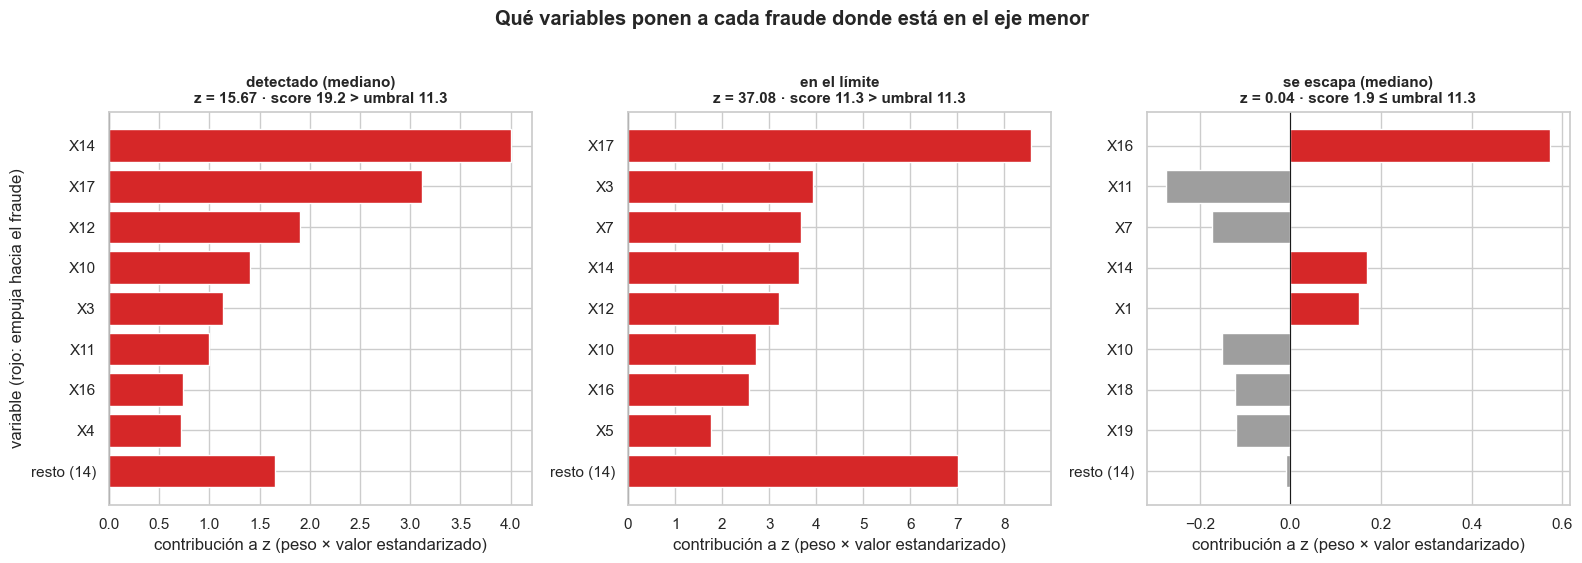

In [126]:
fig, axs = plt.subplots(1, 3, figsize=(16, 5.5))
for ax, (n, i) in zip(axs, EJEMPLOS.items()):
    c = contrib[n].sort_values(key=abs, ascending=False)
    c = pd.concat([c[:8], pd.Series({f"resto ({len(c) - 8})": c[8:].sum()})])[::-1]
    ax.barh(c.index, c, color=[C[1] if v > 0 else C[0] for v in c])
    ax.axvline(0, c="k", lw=.8)
    sig = ">" if s_eje[i] > UMBRAL_EJE else "≤"
    ax.set_title(f"{n}\nz = {z_eje[i]:.2f} · score {s_eje[i]:.1f} {sig} umbral {UMBRAL_EJE:.1f}", fontsize=11)
    ax.set_xlabel("contribución a z (peso × valor estandarizado)")
axs[0].set_ylabel("variable (rojo: empuja hacia el fraude)")
fig.suptitle("Qué variables ponen a cada fraude donde está en el eje menor", weight="bold", y=1.02)
fig.tight_layout();

- **Detectado**: $z$ = 15,67, unas 39 veces la desviación típica de los normales en el eje (0,40). X14, X17, X12 y X10, muy negativas a la vez, aportan dos tercios. Es la explicación que pide el profesor, con nuestras cifras: el umbral es 11,3, este punto tiene 19,2, y lo causan sobre todo X14 y X17.
- **En el límite**: está **más lejos** que el detectado (z = 37,08), y aun así su score (11,30) apenas supera el umbral (11,28). El score no es una distancia sino una densidad: en esa zona hay normales de train, y el GMM les ha dado su propia gaussiana. Es uno de los dos huecos de la figura anterior.
- **Se escapa**: ninguna contribución pasa de 0,6 y se compensan entre sí (X16 empuja hacia el fraude, X11 y X7 en contra). Para este detector es un normal más. No hay explicación que dar, porque no hay alerta.

Las transacciones de train en las dos zonas de los huecos del umbral ($z \approx 22$ y $z \approx 37$), por clase e importe:

In [127]:
zona = pd.Series(np.select([(z_eje > 21.5) & (z_eje < 23), (z_eje > 36) & (z_eje < 38)], ["z ≈ 22", "z ≈ 37"], ""), index=tr.index)
en_zona = zona != ""
pd.crosstab([zona[en_zona].rename("zona"), tr.loc[en_zona, "Amount"].rename("Amount (€)")], y_train[en_zona].map(LBL).rename("clase"))

clase              fraude  normal
zona   Amount (€)                
z ≈ 22 1.50             3       2
       134.98           0       2
       149.77           1       0
       149.98           3       0
z ≈ 37 1.50             0       3
       134.98           0       8
       149.98          12       0

Son una misma "familia": el mismo patrón en las variables, en $z \approx 37$, **12** fraudes de **149,98 €** y **11** normales de **134,98 €** y **1,50 €** intercalados; en $z \approx 22$, lo mismo a menor escala. Pueden ser fraudes sin etiquetar o un uso legítimo con la misma huella; con las variables anonimizadas no lo podemos saber. Como el detector aprende de todos los normales, aprende también esta zona, y los dos fraudes que caen en su centro quedan por debajo del umbral.

### 13.4 Los que se escapan

Primero, dónde están los fraudes que el detector deja por debajo del umbral:

In [128]:
pd.Series({"en el tramo normal del eje": (np.abs(z_eje[esc]) <= nucleo[1]).sum(), "en las zonas z ≈ 22 o z ≈ 37": (zona.iloc[esc] != "").sum(),
           "total": len(esc)}, name="fraudes bajo el umbral").to_frame().T

,en el tramo normal del eje,en las zonas z ≈ 22 o z ≈ 37,total
fraudes bajo el umbral,36,2,38


¿En qué se diferencian de los detectados? Mediana de la coordenada, de las variables con más peso en el eje (estandarizadas) y del importe, por grupo:

In [129]:
grupo = pd.Series(np.where(y_np == 0, "normales", np.where(s_eje > UMBRAL_EJE, "fraudes detectados", "fraudes que se escapan")), index=tr.index)
perfil = Z_tr[["X17", "X14", "X12", "X10", "X4"]].assign(z=z_eje, **{"Amount (€)": tr["Amount"]})
perfil.groupby(grupo).median().assign(n=grupo.value_counts()).loc[["normales", "fraudes detectados", "fraudes que se escapan"]].round(2)

,X17,X14,X12,X10,X4,z,Amount (€),n
normales,-0.11,0.04,0.14,-0.10,-0.01,-0.01,33.25,119412
fraudes detectados,-9.18,-9.31,-7.19,-5.36,3.68,18.19,16.78,168
fraudes que se escapan,0.90,-1.66,-0.48,-0.37,1.62,0.03,5.24,38


Y qué variables separan, una a una, a los que se escapan de los normales (AUROC orientada; 0,5 = nada). Las etiquetas se usan solo para describir, no para elegir nada:

In [130]:
sin_det = grupo != "fraudes detectados"
auroc = lambda x, yy: max(roc_auc_score(yy, x), roc_auc_score(yy, -x))
y_esc = (grupo[sin_det] == "fraudes que se escapan").astype(int)
sep = pd.Series({c: auroc(tr.loc[sin_det, c], y_esc) for c in FEATS_GMM + ["Amount"]}).nlargest(6)
sep.round(3).rename("AUROC: se escapan frente a normales").to_frame().T

,X4,X14,X17,X18,X3,X12
AUROC: se escapan frente a normales,0.812,0.774,0.71,0.688,0.668,0.655


Los que se escapan dentro de la nube no se parecen al fraude típico: su X14 es negativa, pero X17 va en sentido contrario y en el eje se compensan, como en el ejemplo de 13.3. Lo que los delata es más débil y está repartido: X4 alta, X14 algo negativa e importes pequeños (mediana 5,24 € frente a 33,25 € de los normales). Ninguna variable sola pasa de una AUROC de 0,81, y con 38 casos entre 119.412 normales eso no basta. Mover el umbral tampoco: bajarlo al p99 multiplica por diez las falsas alarmas (del 0,1 % al 1 % de los normales) y solo añade dos fraudes (13.2).

> **Conclusión:** El mejor detector se explica entero con una coordenada: el eje menor de los normales (varianza **0,16**), donde pesan **X17 (−0,45), X12 (−0,34), X14 (−0,34) y X10 (−0,31)** y el importe casi nada. El umbral p99,9 de los normales (score **11,28**) equivale a salir del tramo **−0,54 < z < 0,55**: lo supera el **81,55 %** de los fraudes de train y el **0,10 %** de los normales, y en CV el **58 %** de esas alertas son fraude. Cada alerta se explica con su margen sobre el umbral y las contribuciones $w_j\tilde x_j$, que suman exactamente $z$: el fraude mediano detectado tiene score **19,2** (z = **15,67**), dos tercios por X14, X17, X12 y X10. Se escapan **38** fraudes: **36** dentro del tramo normal, donde X17 va en sentido contrario y compensa a X14, y **2** en la "familia" de z ≈ 37 (**12** fraudes de 149,98 € y **11** normales intercalados). → **Impacto:** el 99 puede justificar cada alerta del no supervisado sin LIME, SHAP ni contrafactuales: umbral, z y las 3–4 variables que más aportan. Los 36 fraudes de la nube son invisibles para un umbral sobre este eje: son el objetivo del supervisado (03), que tendrá que combinar señales débiles (X4, X14, X17 y el importe; ninguna pasa de AUROC **0,81** sola). Las zonas z ≈ 22 y 37 son la primera lista para revisar etiquetas.

## 14. Exportar scores para el 04

**Qué miramos y por qué.** El 04 usará los scores no supervisados como variables de un modelo supervisado (D-2.1). Para que aprenda bien, cada score de train tiene que estar calculado **sin haber visto esa fila**, igual que lo estarán los de test y producción. Además se deja un entregable de producción de respaldo con el mejor detector de CV.

Qué se exporta, por fila (construcción + producción, en el orden de `01_dataset_preparado.csv`):

- **train → scores out-of-fold** (`OOF`, de la CV). Si se puntúan los normales con los que se ajustó el detector, salen "demasiado normales", y el 04 aprendería que un score bajo es señal de normal más de lo que lo será en test y producción.
- **test y producción → modelo ajustado con todos los normales de train** (`SC_TEST`, `SC_PROD`, de §12).

Una columna por detector de `PARA_04` (§11), con un nombre corto sin espacios:

In [131]:
import re
PARA_04 = globals().get("PARA_04") or list(FINALISTAS)
CORTO = {"GMM 5 · 1 eje menor": "gmm_eje", "LOF 20 · 4 ejes menores": "lof_4ejes", "ECOD · top 4 + importe": "ecod_top4",
         "kNN 20 · 1 eje menor": "knn_eje", "PCA 21 (standard)": "pca21", "IF 32768 · 1 eje menor": "if_eje",
         "HBOS 10 · 1 eje menor": "hbos_eje", "GMM 5 full (robust)": "gmm_full", "AE 12 (robust)": "ae12",
         "Mahalanobis": "mahalanobis", "GMM 5 (crudo)": "gmm_crudo", "Ensemble": "ensemble"}
COL_04 = {n: "s02_" + CORTO.get(n, re.sub(r"\W+", "_", n.lower()).strip("_")) for n in PARA_04}
pd.Series(COL_04, name="columna").to_frame()

,columna
GMM 5 · 1 eje menor,s02_gmm_eje
LOF 20 · 4 ejes menores,s02_lof_4ejes
ECOD · top 4 + importe,s02_ecod_top4
GMM 5 full (robust),s02_gmm_full
AE 12 (robust),s02_ae12


In [132]:
# train (OOF) + test + producción, en el orden del CSV del 01: construcción por row_id y después producción
partes = [d[["row_id", "split"]].assign(**{c: S[n] for n, c in COL_04.items()}) for d, S in [(tr, OOF), (te, SC_TEST), (df_prod, SC_PROD)]]
cons = pd.concat(partes[:2]).sort_values("row_id")
SCORES_04 = pd.concat([cons, partes[2]], ignore_index=True)

Comprobaciones de alineación: mismas filas y mismo orden que el CSV del 01, scores finitos, y la AUPR recalculada **desde el fichero exportado** coincide con la de CV (por fold) y con la de test de §12.

In [133]:
assert SCORES_04[["split", "row_id"]].equals(df[["split", "row_id"]].reset_index(drop=True)), "orden distinto al del 01"
assert all(len(S[n]) == len(d) for n in PARA_04 for d, S in [(tr, OOF), (te, SC_TEST), (df_prod, SC_PROD)])
assert np.isfinite(SCORES_04[list(COL_04.values())].to_numpy()).all(), "hay scores no finitos"
lab = SCORES_04.merge(df_const[["row_id", "split", "Class", "fold"]], on=["row_id", "split"])    # solo construcción
for n, c in COL_04.items():
    a_tr = lab[lab.split == "train"]
    cv_rec = np.mean([average_precision_score(g.Class, g[c]) for _, g in a_tr.groupby("fold")])
    a_te = lab[lab.split == "test"]
    assert np.isclose(cv_rec, RES[n]["media"]) and np.isclose(average_precision_score(a_te.Class, a_te[c]), TEST.loc[n, "aupr"]), n
SCORES_04.groupby("split", sort=False).size().rename("filas").to_frame().T

split,train,test,prod
filas,119618,51266,113923


In [134]:
SCORES_04.to_csv(OUTPUT_DIR / "02_scores.csv", index=False, float_format="%.8g")
SCORES_04.head()

,row_id,split,s02_gmm_eje,s02_lof_4ejes,s02_ecod_top4,s02_gmm_full,s02_ae12
0,0,train,1.423792,1.023704,7.031816,-5.258285,0.196087
1,1,train,0.732833,1.033333,7.510237,16.578788,0.389191
2,2,train,1.291064,1.129328,6.913726,-12.677998,0.006943
3,3,train,1.307951,1.049363,5.083800,17.797207,0.206403
4,4,train,0.893197,0.959203,7.313021,-6.566421,0.190761


Las métricas, para la tabla final del 99: la CV de todos los detectores evaluados (`RES`) y la tabla de test de §12.

In [135]:
tabla_cv().rename_axis("modelo").to_csv(OUTPUT_DIR / "02_metricas_cv.csv")
TEST.rename_axis("modelo").to_csv(OUTPUT_DIR / "02_metricas_test.csv")
pd.Series({f: (OUTPUT_DIR / f).stat().st_size / 1e6 for f in ["02_scores.csv", "02_metricas_cv.csv", "02_metricas_test.csv"]}, name="MB").round(3).to_frame().T

,02_scores.csv,02_metricas_cv.csv,02_metricas_test.csv
MB,18.391,0.012,0.002


**Entregable provisional.** El mejor detector de CV, reajustado con los normales de **toda la construcción** (train + test): el test ya no va a elegir nada más, y así el modelo ve un 43 % más de normales. Puntúa producción y se guarda con el formato de D-3.1. El entregable final lo genera el 04: este es el de respaldo.

In [136]:
ENTREGA = tabla_cv([*FINALISTAS, *(["Ensemble"] if "Ensemble" in RES and globals().get("ENSEMBLE") else [])]).index[0]
miembros = ENSEMBLE if ENTREGA == "Ensemble" else [ENTREGA]
y_cons = df_const["Class"].to_numpy(int)
s_cons = [score(fit(MODELOS[n][0], df_const[MODELOS[n][1]].to_numpy(float), y_cons), df_prod[MODELOS[n][1]].to_numpy(float)) for n in miembros]
s_entrega = s_cons[0] if len(s_cons) == 1 else np.mean([stats.rankdata(s) / len(s) for s in s_cons], axis=0)
save_submission(s_entrega, name="02_scores_produccion_no_supervisado")
print(f"{ENTREGA}: ajustado con {(y_cons == 0).sum():,} normales de construcción".replace(",", "."))

GMM 5 · 1 eje menor: ajustado con 170.589 normales de construcción


In [137]:
# el fichero guardado: forma, primeras filas y parecido con el mismo detector ajustado solo con train (§12)
sub = pd.read_csv(OUTPUT_DIR / "02_scores_produccion_no_supervisado.csv")
assert sub.shape == (len(df_prod), 1) and list(sub.columns) == ["score"]
top1 = lambda s: set(np.argsort(-np.asarray(s))[: len(s) // 100])        # el 1 % de producción con más score
print(f"forma {sub.shape} · Spearman con el ajuste de §12: {stats.spearmanr(sub['score'], SC_PROD[ENTREGA]).statistic:.3f}"
      f" · top 1 % compartido: {100 * len(top1(sub['score']) & top1(SC_PROD[ENTREGA])) / (len(sub) // 100):.1f} %")
sub.head()

forma (113923, 1) · Spearman con el ajuste de §12: 0.952 · top 1 % compartido: 89.4 %


,score
0,0.751918
1,0.633206
2,0.684572
3,0.806023
4,1.903438


> **Conclusión:** `02_scores.csv` tiene **284.807** filas (**119.618** de train con scores out-of-fold, **51.266** de test y **113.923** de producción) y una columna por detector de `PARA_04` (**5**: `s02_gmm_eje`, `s02_lof_4ejes`, `s02_ecod_top4`, `s02_gmm_full` y `s02_ae12`). La AUPR recalculada desde el fichero coincide con la de CV fold a fold y con la de test de §12, así que filas y scores están alineados. El entregable de respaldo, `02_scores_produccion_no_supervisado.csv` (113.923 × 1, columna `score`), es el **GMM 5 · 1 eje menor** reajustado con **170.589** normales de construcción. Frente al ajuste solo con train comparte el **89,4 %** del 1 % de producción con más score (Spearman **0,952**): el reajuste reordena sobre todo el interior de la nube de normales. → **Impacto:** el 04 recibe los scores no supervisados como variables, sin fuga en train (OOF) y con el mismo modelo en test y producción, y une por `split` + `row_id` con el CSV del 01. Si el híbrido no mejora al no supervisado, ya hay un entregable válido (AUPR de test **0,736**). El entregable final lo genera el 04.

## 15. Conclusiones

Cada hallazgo se traduce en una decisión y en el notebook donde se aplica (03 = `03_supervisados`, 04 = `04_hibrido_y_ensemble`, 99 = `99_ENTREGA`). Las cifras son AUPR de CV (5 folds) salvo que se diga test.

| Hallazgo | Evidencia | Decisión | Afecta a |
|---|---|---|---|
| La AUPR de un fold es muy ruidosa | Mahalanobis: de 0,554 a 0,749 según el fold; banda bootstrap de 0,18–0,26 dentro de cada fold (§1) | Elegir por media ± std y fold a fold; < ~1 std no es concluyente salvo 4 de 5 folds; el test solo confirma | 02–04 |
| El preprocesado del 01 ayuda | GMM del profesor 0,533 → 0,638 con `log1p_Amount` + `amount_freq`, gana en los 5 folds (§2) | `FEATURES` como conjunto por defecto | 02–04 |
| Manda la covarianza, y la clásica | Mahalanobis 0,655 frente a euclídea 0,316 (5 de 5 folds); la robusta cae a 0,384 (§3) | Descartar la euclídea y la covarianza robusta | 02 |
| El escalador cambia la inicialización del GMM, no el modelo | Arranque aleatorio: 0,646 con los tres escaladores; arranque k-means: robust 0,734 frente a standard 0,660 (§4) | D-1.2 por familia: robust en densidad; standard en vecindad, OCSVM y PCA | 02, 04 |
| LOF depende del tamaño del vecindario, más que de los duplicados | Todos los normales 0,073; deduplicados 0,123; submuestra de 20k 0,693 (§5) | Vecindad con submuestra de 20k normales y k = 20; no deduplicar | 02, 04 |
| La señal vive en el eje menor de los normales | PCA 21 0,745; IF 0,504 → 0,738 y kNN 0,533 → 0,746 con solo ese eje; ECOD 0,583 → 0,748 con top 4 + importe (§6–§9) | La representación importa más que el detector: cada detector con su conjunto de variables (§9) | 02–04 |
| Mejor detector no supervisado | **GMM 5 · 1 eje menor: 0,779 ± 0,060 en CV y 0,736 en test** (IC 95 % 0,642–0,822); empata en CV con LOF 20 · 4 ejes menores (0,752) y ECOD · top 4 + importe (0,748). El GMM del profesor da 0,495 en el mismo test, 0,567 con su orden de filas (§10, §12) | Referencia que tiene que batir el supervisado | 03, 04 |
| Los detectores ven casi lo mismo | Bloque del eje menor con ρ de Spearman 0,83–0,96; la mejor combinación por rangos suma +0,013, y un control sin diversidad, +0,008 (§11) | Sin ensemble no supervisado; 5 scores poco correlados pasan al 04 | 04 |
| Una parte del fraude es invisible para la rareza | Con el umbral p99,9 de los normales se escapan 38 de 206 fraudes de train; con un 1 % de falsas alarmas, 26 no los ve ningún finalista. Dentro de la nube, X17 compensa a X14 en el eje, con importes pequeños (§11, §13) | Es lo que tiene que aprender el supervisado o el híbrido | 03, 04 |
| El test sale por debajo de la CV | Los 11 detectores bajan en test (mediana −0,075); el orden se mantiene en lo grueso (Spearman 0,755) y el mejor de CV es el mejor en test (§12) | Esperar ~0,74 en producción, no 0,78 | 99 |
| Posibles fraudes sin etiquetar | 12 fraudes de 149,98 € mezclados con 11 normales con el mismo patrón en el eje (§13) | Comentarlo en la reflexión final | 99 |

**Respuesta parcial a D-2.1 (enfoque).** Sin ver una sola etiqueta al entrenar, un detector de densidad sobre la dirección correcta llega a **0,736 en test**, por encima de la regresión logística simple medida al preparar los datos (0,685 en test, README). La pregunta para el 03 ya no es si las etiquetas ayudan, sino si recuperan los ~1/6 de fraudes que están dentro de la nube normal sin perder lo que el eje menor ya ordena bien.

---
## Conectores

| | Ficheros |
|---|---|
| **Recibe** | `data/output/01_dataset_preparado.csv` (vía la celda común v2: split fijo, `fold`, `FEATURES`) |
| **Entrega** | `data/output/02_metricas_cv.csv` (CV de todos los detectores) · `data/output/02_metricas_test.csv` (test de finalistas y referencias) · `data/output/02_scores.csv` (`row_id`, `split` y los 5 scores de `PARA_04`: OOF en train, ajuste con los normales de train en test y producción), que lee el 04 · `data/output/02_scores_produccion_no_supervisado.csv` (entregable de respaldo: GMM 5 · 1 eje menor ajustado con toda la construcción) |